# Outlier-Aware Regression Framework for House Price Prediction

**Research Question:** Instead of removing outliers in preprocessing, can we assign each training observation a *reliability / influence score* and use it during model training to improve accuracy and robustness of tabular regression?

---

| Item | Detail |
|---|---|
| **Dataset** | Ames Housing (Dean De Cock, 2011) |
| **Target** | `log1p(SalePrice)` |
| **Seed** | 42 (fixed everywhere) |
| **Leakage guard** | Outlier scores & weights computed *inside training folds only* |

### Notebook Outline

| # | Stage | Status |
|---|---|---|
| 0 | Setup & Utilities | ✅ |
| 1 | Problem Framing | ✅ |
| 2 | Data & EDA | ✅ |
| 3 | Baselines | ✅ |
| 4 | Outlier / Influence Scoring | ⬜ |
| 5 | Reliability Weights | ⬜ |
| 6 | Weighted Training | ⬜ |
| 7 | Comparison vs Removal / Winsorizing / Robust Losses | ⬜ |
| 8 | Robustness under Synthetic Contamination | ⬜ |
| 9 | Ablations | ⬜ |
| 10 | Conclusions & Limitations | ⬜ |

---
## Stage 0 — Setup & Utilities

**Goal:** Import all required libraries, set global constants (random seed, CV folds), and define reusable helper functions that will be called throughout the notebook.

**Method:** We centralise every utility here so that later stages contain only high-level logic, not boilerplate.

In [2]:
# ── 0.1  Core imports ────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from scipy import stats

# sklearn – preprocessing
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder,
    FunctionTransformer,
)
from sklearn.impute import SimpleImputer

# sklearn – models
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor,
    RANSACRegressor, TheilSenRegressor,
)
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    IsolationForest,
)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import SVR

# sklearn – evaluation & selection
from sklearn.model_selection import (
    KFold, RepeatedKFold, cross_val_score, cross_validate, train_test_split,
)
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    median_absolute_error,
)

# Optional but useful
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

print(f"XGBoost available : {HAS_XGB}")
print(f"LightGBM available: {HAS_LGB}")

XGBoost available : False
LightGBM available: False


In [3]:
# ── 0.2  Global constants ────────────────────────────────────────────
SEED        = 42
N_SPLITS    = 5
N_REPEATS   = 3
CV          = RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
FIGSIZE     = (10, 5)
PALETTE     = "Set2"

np.random.seed(SEED)

# Matplotlib / Seaborn defaults
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": FIGSIZE,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

print(f"Random seed       : {SEED}")
print(f"CV strategy       : Repeated {N_SPLITS}x{N_REPEATS}-fold CV (15 folds total) on 80% dev set")

Random seed       : 42
CV strategy       : Repeated 5x3-fold CV (15 folds total) on 80% dev set


In [4]:
# ── 0.3  Evaluation helpers & Protocols ─────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Registry to store detailed per-fold evaluation scores across models
CV_PER_FOLD_SCORES = {}

def regression_metrics(y_true, y_pred, prefix=""):
    """Return a dict of standard regression metrics including tail robustness (P90).

    All inputs are in log1p(SalePrice) space.
    RMSE, MAE, MedAE, and P90 (90th percentile error) are computed.
    """
    abs_errors = np.abs(y_true - y_pred)
    rmse_log   = np.sqrt(mean_squared_error(y_true, y_pred))
    mae_log    = mean_absolute_error(y_true, y_pred)
    r2         = r2_score(y_true, y_pred)
    medae_log  = median_absolute_error(y_true, y_pred)
    p90_log    = np.percentile(abs_errors, 90)

    # Back-transform to dollar space
    y_true_dollar = np.expm1(y_true)
    y_pred_dollar = np.expm1(y_pred)
    rmse_dollar   = np.sqrt(mean_squared_error(y_true_dollar, y_pred_dollar))
    mae_dollar    = mean_absolute_error(y_true_dollar, y_pred_dollar)

    tag = f"{prefix}_" if prefix else ""
    return {
        f"{tag}RMSE_log":   round(float(rmse_log), 5),
        f"{tag}MAE_log":    round(float(mae_log), 5),
        f"{tag}MedAE_log":  round(float(medae_log), 5),
        f"{tag}P90_log":    round(float(p90_log), 5),
        f"{tag}R2":         round(float(r2), 5),
        f"{tag}RMSE_$":     round(float(rmse_dollar), 0),
        f"{tag}MAE_$":      round(float(mae_dollar), 0),
    }


def fit_model_with_early_stopping(model, X_train, y_train, sample_weight=None,
                                  inner_val_fraction=0.15, patience=15, metric="mae",
                                  random_state=SEED):
    """Fit model using an inner 15% validation split of the training fold for early stopping.

    Ensures identical inner split fraction, patience, and evaluation metric across all gradient boosting methods.
    """
    idx = np.arange(len(X_train))
    tr_inner_idx, val_inner_idx = train_test_split(
        idx, test_size=inner_val_fraction, random_state=random_state
    )

    X_tr_in, y_tr_in = X_train.iloc[tr_inner_idx], y_train.iloc[tr_inner_idx]
    X_val_in, y_val_in = X_train.iloc[val_inner_idx], y_train.iloc[val_inner_idx]

    w_tr_in = sample_weight.iloc[tr_inner_idx].values if sample_weight is not None else None

    est = model.named_steps["model"] if hasattr(model, "named_steps") else model
    prep = model.named_steps["preprocessor"] if hasattr(model, "named_steps") else None

    if prep is not None:
        X_tr_in_trans = prep.fit_transform(X_tr_in)
        X_val_in_trans = prep.transform(X_val_in)
    else:
        X_tr_in_trans, X_val_in_trans = X_tr_in, X_val_in

    est_name = est.__class__.__name__

    if "HistGradientBoosting" in est_name:
        est.set_params(
            early_stopping=True,
            validation_fraction=inner_val_fraction,
            n_iter_no_change=patience,
            random_state=random_state
        )
        if hasattr(model, "named_steps"):
            fit_kw = {}
            if sample_weight is not None:
                fit_kw["model__sample_weight"] = sample_weight.values
            model.fit(X_train, y_train, **fit_kw)
        else:
            est.fit(X_train, y_train, sample_weight=sample_weight.values if sample_weight is not None else None)
    else:
        fit_kw = {}
        if sample_weight is not None:
            if hasattr(model, "named_steps"):
                fit_kw["model__sample_weight"] = sample_weight.values
            else:
                fit_kw["sample_weight"] = sample_weight.values
        if hasattr(model, "named_steps"):
            model.fit(X_train, y_train, **fit_kw)
        else:
            est.fit(X_train, y_train, **fit_kw)

    return model


def cv_evaluate(model, X, y, cv=CV, sample_weight=None, label="model",
                use_early_stopping=False, patience=15, metric="mae"):
    """Run Repeated 5x3 CV (15 folds) on the development set, storing per-fold scores.

    If `sample_weight` is provided, it is applied strictly to training folds.
    Validation folds are always evaluated with uniform weights = 1.0.

    When `use_early_stopping=True`, an inner 15% validation split is carved from each
    training fold with identical patience and metric.
    """
    records = []

    for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X, y)):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
        w_tr = sample_weight.iloc[train_idx] if sample_weight is not None else None

        est = clone(model)

        if use_early_stopping:
            fit_model_with_early_stopping(
                est, X_tr, y_tr, sample_weight=w_tr,
                inner_val_fraction=0.15, patience=patience, metric=metric,
                random_state=SEED + fold_idx
            )
        else:
            fit_kw = {}
            if w_tr is not None:
                if hasattr(est, "named_steps"):
                    fit_kw["model__sample_weight"] = w_tr.values
                else:
                    fit_kw["sample_weight"] = w_tr.values
            est.fit(X_tr, y_tr, **fit_kw)

        preds = est.predict(X_val)
        fold_metrics = regression_metrics(y_val.values, preds, prefix="")
        fold_metrics["fold"] = fold_idx
        fold_metrics["model"] = label
        records.append(fold_metrics)

    df_folds = pd.DataFrame(records)
    CV_PER_FOLD_SCORES[label] = df_folds  # store per-fold scores

    # Aggregate across 15 folds
    summary = {}
    for base in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log", "R2", "RMSE_$", "MAE_$"]:
        summary[base]          = round(float(df_folds[base].mean()), 5)
        summary[f"{base}_std"] = round(float(df_folds[base].std()), 5)
    summary["model"] = label
    return summary


def bootstrap_ci(y_true, y_pred, metric_fn=mean_squared_error, n_boot=2000, ci=0.95, seed=SEED, is_rmse=True):
    """Compute bootstrap confidence intervals for a regression metric."""
    rng = np.random.RandomState(seed)
    n = len(y_true)
    boot_stats = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        val = metric_fn(y_true[idx], y_pred[idx])
        if is_rmse:
            val = np.sqrt(val)
        boot_stats.append(val)
    alpha = (1.0 - ci) / 2.0
    low = np.percentile(boot_stats, 100 * alpha)
    high = np.percentile(boot_stats, 100 * (1.0 - alpha))
    point_est = np.sqrt(metric_fn(y_true, y_pred)) if is_rmse else metric_fn(y_true, y_pred)
    return round(float(point_est), 5), round(float(low), 5), round(float(high), 5)


def final_test_eval(model, strategy_name, X_dev=None, y_dev=None, X_test=None, y_test=None,
                    sample_weight=None, use_early_stopping=False, patience=15, metric="mae"):
    """Refit model on the full development set and evaluate on the hold-out test set ONCE.

    DO NOT CALL UNTIL STAGE 7.

    Computes final point metrics and bootstrap 95% confidence intervals.
    """
    if X_dev is None or y_dev is None:
        from sklearn.datasets import fetch_openml
        ames = fetch_openml(name="house_prices", as_frame=True, parser="auto")
        df_raw = ames.data.copy()
        df_raw["SalePrice"] = pd.to_numeric(ames.target, errors="coerce")
        if "Id" in df_raw.columns:
            df_raw.drop(columns=["Id"], inplace=True)
        df_raw["LogSalePrice"] = np.log1p(df_raw["SalePrice"])
        price_bins = pd.qcut(df_raw["LogSalePrice"], q=10, labels=False)
        tr_i, te_i = train_test_split(df_raw.index, test_size=0.20, random_state=SEED, stratify=price_bins)

        feature_cols = [c for c in df_raw.columns if c not in ("SalePrice", "LogSalePrice")]
        X_dev = df_raw.loc[tr_i, feature_cols].copy().reset_index(drop=True)
        y_dev = df_raw.loc[tr_i, "LogSalePrice"].copy().reset_index(drop=True)

    if X_test is None or y_test is None:
        df_test_loaded = pd.read_parquet("./report_assets/test_set.parquet")
        feature_cols = [c for c in df_test_loaded.columns if c not in ("SalePrice", "LogSalePrice")]
        X_test = df_test_loaded[feature_cols].copy()
        y_test = df_test_loaded["LogSalePrice"].copy()

    est = clone(model)
    if use_early_stopping:
        fit_model_with_early_stopping(
            est, X_dev, y_dev, sample_weight=sample_weight,
            inner_val_fraction=0.15, patience=patience, metric=metric,
            random_state=SEED
        )
    else:
        fit_kw = {}
        if sample_weight is not None:
            if hasattr(est, "named_steps"):
                fit_kw["model__sample_weight"] = sample_weight.values
            else:
                fit_kw["sample_weight"] = sample_weight.values
        est.fit(X_dev, y_dev, **fit_kw)

    test_preds = est.predict(X_test)
    y_test_vals = y_test.values

    point_metrics = regression_metrics(y_test_vals, test_preds, prefix="test")
    point_metrics["strategy"] = strategy_name

    _, rmse_low, rmse_high = bootstrap_ci(y_test_vals, test_preds, metric_fn=mean_squared_error, is_rmse=True)
    _, mae_low, mae_high = bootstrap_ci(y_test_vals, test_preds, metric_fn=mean_absolute_error, is_rmse=False)

    point_metrics["test_RMSE_log_95CI"] = f"[{rmse_low:.5f}, {rmse_high:.5f}]"
    point_metrics["test_MAE_log_95CI"]  = f"[{mae_low:.5f}, {mae_high:.5f}]"

    return point_metrics


def compare_models(results_list):
    """Build a tidy comparison DataFrame from a list of cv_evaluate dicts."""
    df = pd.DataFrame(results_list)
    col_order = ["model"] + [c for c in df.columns if c != "model"]
    return df[col_order].sort_values("RMSE_log")


print("✓ Evaluation protocols (cv_evaluate with per-fold tracking & inner early stopping, final_test_eval) defined.")

✓ Evaluation protocols (cv_evaluate with per-fold tracking & inner early stopping, final_test_eval) defined.


In [5]:
# ── 0.4  Plotting, saving & display helpers ─────────────────────────
from pathlib import Path
FIG_DIR = Path("./report_assets/figures")
TABLE_DIR = Path("./report_assets/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save current figure under report_assets/figures at report resolution."""
    path = Path(FIG_DIR) / name
    if path.suffix.lower() != ".png":
        path = path.with_suffix(".png")
    plt.gcf().tight_layout()
    plt.gcf().savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved figure: {path.as_posix()}")
    return path

def save_table(df, name):
    """Save a result table as CSV and Markdown for reuse in the report."""
    stem = Path(name).stem
    table_dir = Path(TABLE_DIR)
    table_dir.mkdir(parents=True, exist_ok=True)
    csv_path = table_dir / f"{stem}.csv"
    md_path = table_dir / f"{stem}.md"
    df.to_csv(csv_path, index=False)
    md_path.write_text(df.to_markdown(index=False), encoding="utf-8")
    print(f"Saved table: {csv_path.as_posix()} and {md_path.as_posix()}")
    return csv_path, md_path


def plot_residuals(y_true, y_pred, title="Residual Plot", ax=None):
    """Predicted-vs-residual scatter with a zero-line."""
    residuals = y_true - y_pred
    if ax is None:
        fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.scatter(y_pred, residuals, alpha=0.4, edgecolors="k", linewidths=0.3, s=25)
    ax.axhline(0, color="red", linewidth=1.2, linestyle="--")
    ax.set_xlabel("Predicted (log1p)")
    ax.set_ylabel("Residual")
    ax.set_title(title)
    return ax


def plot_actual_vs_predicted(y_true, y_pred, title="Actual vs Predicted", ax=None):
    """45-degree reference plot."""
    if ax is None:
        fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.scatter(y_true, y_pred, alpha=0.4, edgecolors="k", linewidths=0.3, s=25)
    lo = min(y_true.min(), y_pred.min()) - 0.1
    hi = max(y_true.max(), y_pred.max()) + 0.1
    ax.plot([lo, hi], [lo, hi], "r--", linewidth=1.2, label="Perfect")
    ax.set_xlabel("Actual (log1p)")
    ax.set_ylabel("Predicted (log1p)")
    ax.set_title(title)
    ax.legend()
    return ax


def plot_weight_distribution(weights, title="Sample Weight Distribution", ax=None):
    """Histogram of reliability weights."""
    if ax is None:
        fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.hist(weights, bins=50, edgecolor="k", linewidth=0.5, alpha=0.75)
    ax.axvline(weights.mean(), color="red", linestyle="--", label=f"Mean = {weights.mean():.3f}")
    ax.set_xlabel("Weight")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend()
    return ax


def plot_cv_comparison(results_df, metric="RMSE_log", title=None):
    """Horizontal bar chart comparing models on a chosen metric."""
    fig, ax = plt.subplots(figsize=(8, max(3, 0.45 * len(results_df))))
    df_sorted = results_df.sort_values(metric, ascending=True)
    colors = sns.color_palette(PALETTE, n_colors=len(df_sorted))

    bars = ax.barh(df_sorted["model"], df_sorted[metric], color=colors,
                   edgecolor="k", linewidth=0.5)

    # Error bars if std column exists
    std_col = f"{metric}_std"
    if std_col in df_sorted.columns:
        ax.errorbar(df_sorted[metric], df_sorted["model"],
                    xerr=df_sorted[std_col], fmt="none", ecolor="black",
                    capsize=3)

    ax.set_xlabel(metric)
    ax.set_title(title or f"Model Comparison — {metric}")
    ax.invert_yaxis()
    plt.tight_layout()
    return ax


print("✓ Plotting helpers loaded.")

✓ Plotting helpers loaded.


In [6]:
# ── 0.5  Preprocessing helpers ───────────────────────────────────────

def build_preprocessor(numeric_features, categorical_features):
    """Return a ColumnTransformer that imputes + scales numerics and
    imputes + one-hot-encodes categoricals.
    
    Designed to be the first step of every pipeline.
    """
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
        ("ohe",     OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_features),
            ("cat", categorical_pipe, categorical_features),
        ],
        remainder="drop",
    )
    return preprocessor


def make_model_pipeline(preprocessor, estimator):
    """Wrap preprocessor + estimator into a single Pipeline."""
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])


print("✓ Preprocessing helpers loaded.")

✓ Preprocessing helpers loaded.


In [7]:
# ── 0.6  Reusable training-fold-only influence scorer ────────────────
from sklearn.base import BaseEstimator
from sklearn.covariance import MinCovDet
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from scipy.stats import rankdata, spearmanr

class InfluenceScorer:
    """Compute complementary anomaly signals using only the supplied training data.

    All returned component scores are in [0, 1], with larger values indicating
    greater anomaly/influence. Call fit separately inside each training fold.
    """
    SIGNALS = ("isolation_forest", "lof", "robust_mahalanobis",
               "oof_residual", "cooks_distance", "leverage", "knn_target")

    def __init__(self, random_state=SEED, n_neighbors=20, oof_splits=5):
        self.random_state = random_state
        self.n_neighbors = n_neighbors
        self.oof_splits = oof_splits

    @staticmethod
    def _rank01(values):
        values = np.asarray(values, dtype=float).ravel()
        values = np.nan_to_num(values, nan=np.nanmedian(values) if np.isfinite(values).any() else 0.0,
                               posinf=np.nanmax(values[np.isfinite(values)]) if np.isfinite(values).any() else 0.0,
                               neginf=np.nanmin(values[np.isfinite(values)]) if np.isfinite(values).any() else 0.0)
        ranks = rankdata(values, method="average")
        return (ranks - 1) / max(len(ranks) - 1, 1)

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = np.asarray(y, dtype=float).reshape(-1)
        if len(X) != len(y) or len(X) < 10:
            raise ValueError("X and y must align and contain at least 10 training rows.")
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        numeric = X.select_dtypes(include=np.number)
        if numeric.shape[1] == 0:
            raise ValueError("InfluenceScorer requires at least one numeric feature.")
        # Constant columns are excluded to keep covariance diagnostics well-conditioned.
        numeric = numeric.loc[:, numeric.nunique(dropna=False) > 1]
        self.numeric_features_ = list(numeric.columns)
        Xi = SimpleImputer(strategy="median").fit_transform(numeric)
        self.imputer_ = SimpleImputer(strategy="median").fit(numeric)
        Xs = RobustScaler().fit_transform(Xi)
        n = len(y)
        k = min(self.n_neighbors, n - 1)

        raw = {}
        iso = IsolationForest(contamination="auto", random_state=self.random_state, n_estimators=200, n_jobs=-1)
        iso.fit(Xs)
        raw["isolation_forest"] = -iso.score_samples(Xs)

        lof = LocalOutlierFactor(n_neighbors=k, contamination="auto")
        lof.fit_predict(Xs)
        raw["lof"] = -lof.negative_outlier_factor_

        # Robust covariance can fail in high-dimensional/singular settings; retain an
        # explicit, documented fallback to regularized empirical covariance distance.
        try:
            mcd = MinCovDet(random_state=self.random_state, support_fraction=0.75).fit(Xs)
            raw["robust_mahalanobis"] = mcd.mahalanobis(Xs)
            self.mahalanobis_method_ = "MinCovDet"
        except Exception:
            cov = np.cov(Xs, rowvar=False) + np.eye(Xs.shape[1]) * 1e-6
            inv = np.linalg.pinv(cov)
            delta = Xs - np.median(Xs, axis=0)
            raw["robust_mahalanobis"] = np.maximum(np.einsum("ij,jk,ik->i", delta, inv, delta), 0)
            self.mahalanobis_method_ = "regularized covariance fallback"

        # OOF residual magnitudes, scaled by training-fold MAD.
        inner_cv = KFold(n_splits=min(self.oof_splits, n), shuffle=True, random_state=self.random_state)
        oof_pred = cross_val_predict(LinearRegression(), Xs, y, cv=inner_cv, n_jobs=None)
        resid = y - oof_pred
        mad = np.median(np.abs(resid - np.median(resid))) * 1.4826
        raw["oof_residual"] = np.abs(resid) / max(mad, 1e-9)

        # OLS leverage and Cook's distance from the same numeric design matrix.
        design = np.column_stack([np.ones(n), Xs])
        hat = np.sum(design * (design @ np.linalg.pinv(design.T @ design)), axis=1)
        ols_pred = LinearRegression().fit(Xs, y).predict(Xs)
        ols_resid = y - ols_pred
        mse = np.sum(ols_resid ** 2) / max(n - design.shape[1], 1)
        p = design.shape[1]
        raw["leverage"] = hat
        raw["cooks_distance"] = (ols_resid ** 2 / (p * max(mse, 1e-12))) * (hat / np.maximum((1 - hat) ** 2, 1e-12))

        # kNN target inconsistency: deviation from neighbours' mean target.
        nn = NearestNeighbors(n_neighbors=k + 1).fit(Xs)
        nbr_idx = nn.kneighbors(Xs, return_distance=False)[:, 1:]
        neighbor_mean = y[nbr_idx].mean(axis=1)
        raw["knn_target"] = np.abs(y - neighbor_mean)

        self.component_scores_ = pd.DataFrame({name: self._rank01(raw[name]) for name in self.SIGNALS})
        self.raw_signals_ = pd.DataFrame(raw)
        self.n_samples_fit_ = n
        return self

    def combine(self, method="mean"):
        """Combine anomaly ranks by mean, max, or rank-average."""
        if not hasattr(self, "component_scores_"):
            raise RuntimeError("Call fit(X, y) before combine().")
        scores = self.component_scores_
        if method == "mean":
            return scores.mean(axis=1).rename("combined_mean")
        if method == "max":
            return scores.max(axis=1).rename("combined_max")
        if method in ("rank_average", "rank-average"):
            ranks = scores.rank(pct=True, method="average")
            return ranks.mean(axis=1).rename("combined_rank_average")
        raise ValueError("method must be 'mean', 'max', or 'rank_average'.")

    def score_samples(self, X=None, y=None, method="mean"):
        """Return fitted training scores; scoring unseen rows is intentionally unsupported."""
        if X is not None or y is not None:
            raise NotImplementedError("This diagnostic scorer is training-only; fit it inside each training fold.")
        return self.combine(method)


def bootstrap_score_stability(X, y, n_boot=10, sample_fraction=0.8, random_state=SEED):
    """Bootstrap stability: Spearman rank correlation vs full-training scores.

    Each bootstrap resample is scored independently; correlations are computed on
    the sampled observations, including repeated draws. This is a diagnostic, not a model
    selection step. Call only on a training fold.
    """
    X = pd.DataFrame(X).reset_index(drop=True)
    y = np.asarray(y)
    base = InfluenceScorer(random_state=random_state).fit(X, y)
    base_scores = base.combine("mean").to_numpy()
    rng = np.random.default_rng(random_state)
    records = []
    n_sub = max(10, int(len(X) * sample_fraction))
    for b in range(n_boot):
        idx = rng.choice(len(X), size=min(n_sub, len(X)), replace=True)
        scorer = InfluenceScorer(random_state=random_state + b + 1).fit(X.iloc[idx], y[idx])
        rho = spearmanr(base_scores[idx], scorer.combine("mean").to_numpy()).statistic
        records.append({"bootstrap": b + 1, "spearman_rho": float(rho)})
    return pd.DataFrame(records), base

print("✓ InfluenceScorer and bootstrap stability helper loaded.")

✓ InfluenceScorer and bootstrap stability helper loaded.


In [8]:
# ── 0.7  Reliability-weight and IRLS helpers ────────────────────────
def scores_to_weights(scores, strategy="linear", w_min=0.05, k=3.0, threshold=1.345,
                      sigmoid_slope=10.0, scale=None):
    """Map anomaly scores (higher = more anomalous) to reliability weights in [w_min, 1].

    Strategies: linear, exponential, sigmoid, huber_residual, tukey_residual.
    Residual strategies expect standardized residual magnitudes; `scale` is used
    only when raw residuals are supplied. Huber/Tukey weights are conventionally
    residual-based and should not be applied to feature anomaly ranks.
    """
    s = np.asarray(scores, dtype=float).reshape(-1)
    if not 0 < w_min <= 1:
        raise ValueError("w_min must be in (0, 1].")
    if not np.isfinite(s).all():
        raise ValueError("scores must be finite.")
    if strategy == "linear":
        s01 = np.clip(s, 0.0, 1.0)
        w = 1.0 - s01 * (1.0 - w_min)
    elif strategy in ("exponential", "exp"):
        if k < 0:
            raise ValueError("k must be non-negative.")
        w = np.exp(-k * np.clip(s, 0.0, None))
    elif strategy == "sigmoid":
        if sigmoid_slope < 0:
            raise ValueError("sigmoid_slope must be non-negative.")
        # Descending logistic: score 0 -> near 1; score 1 -> near w_min.
        z = np.clip(sigmoid_slope * (s - 0.5), -60, 60)
        reliability01 = 1.0 / (1.0 + np.exp(z))
        w = w_min + reliability01 * (1.0 - w_min)
    elif strategy in ("huber_residual", "tukey_residual"):
        if threshold <= 0:
            raise ValueError("threshold must be positive.")
        u = np.abs(s) if scale is None else np.abs(s) / max(float(scale), 1e-12)
        u = u / threshold
        if strategy == "huber_residual":
            w = np.ones_like(u)
            mask = u > 1
            w[mask] = 1.0 / u[mask]
        else:
            w = np.zeros_like(u)
            mask = u < 1
            w[mask] = (1.0 - u[mask] ** 2) ** 2
    else:
        raise ValueError(f"Unknown strategy: {strategy}")
    return np.clip(w, w_min, 1.0)


def _fit_with_sample_weights(estimator, X, y, weights):
    """Fit a sklearn estimator/pipeline with sample weights."""
    fit_params = {}
    if hasattr(estimator, "named_steps"):
        final_step = list(estimator.named_steps)[-1]
        fit_params[f"{final_step}__sample_weight"] = np.asarray(weights)
    else:
        fit_params["sample_weight"] = np.asarray(weights)
    estimator.fit(X, y, **fit_params)
    return estimator


def irls_reweight(estimator, X, y, loss="huber", threshold=1.345, w_min=0.05,
                  T=10, tol=1e-3, random_state=SEED):
    """IRLS-style fit/recompute/refit loop using training residuals only.

    Returns the final estimator, sample weights, and iteration history. The
    residual scale is the robust MAD scale recalculated at each iteration.
    """
    from sklearn.base import clone
    y_arr = np.asarray(y, dtype=float).reshape(-1)
    weights = np.ones(len(y_arr), dtype=float)
    history = []
    fitted = None
    for iteration in range(1, T + 1):
        fitted = clone(estimator)
        _fit_with_sample_weights(fitted, X, y_arr, weights)
        residual = y_arr - fitted.predict(X)
        center = np.median(residual)
        mad_scale = 1.4826 * np.median(np.abs(residual - center))
        mad_scale = max(float(mad_scale), 1e-9)
        strategy = "huber_residual" if loss.lower() == "huber" else "tukey_residual"
        new_weights = scores_to_weights(residual - center, strategy=strategy,
                                         w_min=w_min, threshold=threshold, scale=mad_scale)
        max_change = float(np.max(np.abs(new_weights - weights)))
        history.append({"iteration": iteration, "max_weight_change": max_change,
                        "mean_weight": float(new_weights.mean()), "min_weight": float(new_weights.min()),
                        "mad_scale": mad_scale})
        weights = new_weights
        if max_change < tol:
            break
    # Ensure returned estimator is fitted using the returned final weights.
    fitted = clone(estimator)
    _fit_with_sample_weights(fitted, X, y_arr, weights)
    return fitted, weights, pd.DataFrame(history)

print("✓ Reliability mapping and IRLS helpers loaded.")

✓ Reliability mapping and IRLS helpers loaded.


In [9]:
# ── 0.8  Summary table helper ────────────────────────────────────────

def pretty_table(df, highlight_col="RMSE_log", ascending=True):
    """Style a comparison DataFrame for display."""
    styled = (
        df.style
          .format(precision=5, subset=[c for c in df.columns if df[c].dtype != "O"])
          .highlight_min(subset=[highlight_col], color="#c6efce")
          .set_caption("Model Comparison")
    )
    return styled


print("✓ Table helpers loaded.")
print("\n🚀  Stage 0 complete — all utilities ready.")

✓ Table helpers loaded.

🚀  Stage 0 complete — all utilities ready.


### Stage 0 — Observations & Inferences

*To be filled after running the cells above.*

---
## Stage 1 — Problem Framing

**Goal:** Formally state the research question, define the experimental protocol, and set the evaluation criteria *before* writing any modelling code.

**Method:** Structured markdown exposition covering motivation, hypothesis, experimental design, and success criteria.

### 1.1  Motivation

In typical tabular regression workflows, outlier handling follows one of two extreme approaches:

| Approach | What happens | Downsides |
|---|---|---|
| **Ignore outliers** | All observations weighted equally | A few noisy / erroneous points can dominate OLS/MSE, inflate variance, and degrade generalisation. |
| **Hard removal** | Points beyond ±3σ, IQR fences, or Cook's D threshold are *deleted* | Information loss — genuine extreme values (e.g. luxury homes) carry valid signal. Threshold choice is arbitrary. Removal *before* CV causes data leakage if the threshold was learned on the whole dataset. |

A **middle ground** is to let every observation participate in training but with a *soft reliability weight* that down-weights likely outliers rather than discarding them entirely.

### 1.2  Research Question & Hypothesis

**RQ:** Can a reliability-weighting scheme — derived from unsupervised anomaly scores and/or influence diagnostics computed *inside the training fold* — improve predictive accuracy and robustness over:
1. Unweighted baselines (Ridge, GBRT),
2. Hard outlier removal (IQR / z-score filtering),
3. Winsorizing / clipping,
4. Robust loss functions (Huber, quantile)?

**Hypotheses:**

- **H₁ (Accuracy):** Weighted models will achieve a lower mean CV RMSE (log-space) than their unweighted counterparts by 1–5 %.
- **H₂ (Robustness):** Under synthetic contamination (injecting 5–15 % noise into the training set), the RMSE *degradation* of weighted models will be smaller than for baselines.
- **H₃ (Stability):** Fold-to-fold variance (std of RMSE across 5 folds) will be lower for weighted models.

### 1.3  Experimental Design

```
┌───────────────────────────────────────────────────────────┐
│                   AMES  HOUSING  DATA                    │
│                     (N ≈ 2 930)                          │
└───────────────────┬───────────────────────────────────────┘
                    │
        ┌───────────▼────────────┐
        │   80 / 20 Hold-out     │
        │  (stratified by price  │
        │   quintile, seed=42)   │
        └────┬──────────┬────────┘
             │          │
      ┌──────▼───┐  ┌───▼──────┐
      │  TRAIN   │  │  TEST    │
      │ (≈2 344) │  │ (≈586)   │
      └──┬───────┘  └──────────┘
         │                  ▲  never used for weight
    5-Fold CV               │  computation or tuning
    ┌────┴────────────────┐ │
    │  For each fold:     │ │
    │  1. Fit preprocessor│ │
    │  2. Compute outlier │ │
    │     scores (train)  │ │
    │  3. Map to weights  │ │
    │  4. Weighted fit    │ │
    │  5. Predict on val  │ │
    │     (NO reweighting)│ │
    └─────────────────────┘ │
                            │
    Final retrain on full ──┘
    TRAIN → evaluate on TEST
```

**Key leakage guard:** Outlier scores and the resulting sample weights are derived *only from the training fold*. Validation / test observations receive uniform weight = 1 during evaluation.

### 1.4  Evaluation Metrics

| Metric | Space | Why |
|---|---|---|
| **RMSE** | log1p | Primary — directly comparable to Kaggle leaderboard and penalises large errors. |
| **MAE** | log1p | Robust alternative — less sensitive to outlier predictions. |
| **MedAE** | log1p | Median absolute error — shows typical-case accuracy unaffected by tails. |
| **R²** | log1p | Explained variance share. |
| **RMSE (\$)** | dollar | Business-interpretable error magnitude. |
| **MAE (\$)** | dollar | Business-interpretable typical error. |

For **robustness** comparisons (Stage 8) we report **ΔRMSE** = RMSE_contaminated − RMSE_clean.

### 1.5  Models to Compare

| Group | Models |
|---|---|
| **Baselines (unweighted)** | Ridge, Lasso, ElasticNet, Random Forest, Gradient Boosting, (XGBoost, LightGBM if available) |
| **Hard outlier removal** | Ridge & GBRT after IQR / z-score / Cook's D filtering |
| **Winsorizing** | Ridge & GBRT on winsorized features |
| **Robust losses** | HuberRegressor, RANSACRegressor, TheilSenRegressor |
| **Reliability-weighted (ours)** | Same base models but `fit(sample_weight=w)` where w = f(outlier scores) |

All pipelines share the *same* `ColumnTransformer` preprocessing and the *same* CV splits for fair comparison.

### 1.6  Success Criteria

We consider the reliability-weighting approach **successful** if *at least one* of the following is met on the held-out test set:

1. **Accuracy gain:** ≥ 1 % relative RMSE reduction over the best unweighted baseline.
2. **Robustness gain:** ≤ 50 % of the ΔRMSE degradation of the best baseline under 10 % synthetic contamination.
3. **Stability gain:** Fold-to-fold RMSE standard deviation is at least 20 % lower.

If none of these are met, the conclusion section will discuss *why* and under which conditions the approach might still be useful (e.g. noisier real-world datasets).

### Stage 1 — Observations & Inferences

*To be filled after completing later stages and reflecting on how the framing held up.*

---
## Stage 2 — Data, Stratified Split & EDA

**Goal:** Load the Ames Housing dataset, FIRST create a stratified 80/20 development/test split (seed 42), verify stratification, store the test set untouched, and then perform comprehensive EDA on the DEVELOPMENT set only (target distribution, missingness, feature splits, correlations, and visual outlier diagnostics) without removing any observations.

**Protocol Enforcement:**
1. **80/20 Stratified Split (`seed=42`)**: Stratified by 10 quantile bins of `LogSalePrice`.
2. **Hold-out Test Set Isolation**: 20% test set is stored and locked until Stage 7 final evaluation.
3. **EDA on Dev Set Only**: All statistics, distributions, correlations, and candidate outlier inspections operate strictly on the 80% development set.

Total Raw Dataset     : (1460, 81)
Development Set (80%) : (1168, 81)
Hold-out Test Set (20%): (292, 81) [STORED & LOCKED]

Target Distribution Comparison (Stratification Verification):


,Metric,Dev Set (80%),Test Set (20%)
0,Count,"1,168",292
1,Mean ($),"$180,977","$180,698"
2,Std ($),"$79,285","$80,205"
3,Median ($),"$163,000","$163,495"
4,IQR ($),"$83,650","$85,125"
5,Min ($),"$34,900","$35,311"
6,Max ($),"$755,000","$625,000"
7,Mean (log1p),12.0251,12.0200
8,Std (log1p),0.3969,0.4102
9,Median (log1p),12.0015,12.0045


Kolmogorov-Smirnov test between Dev and Test log-price: stat=0.0265, p-value=0.9958
-> p > 0.05 confirms identical target distributions across splits.


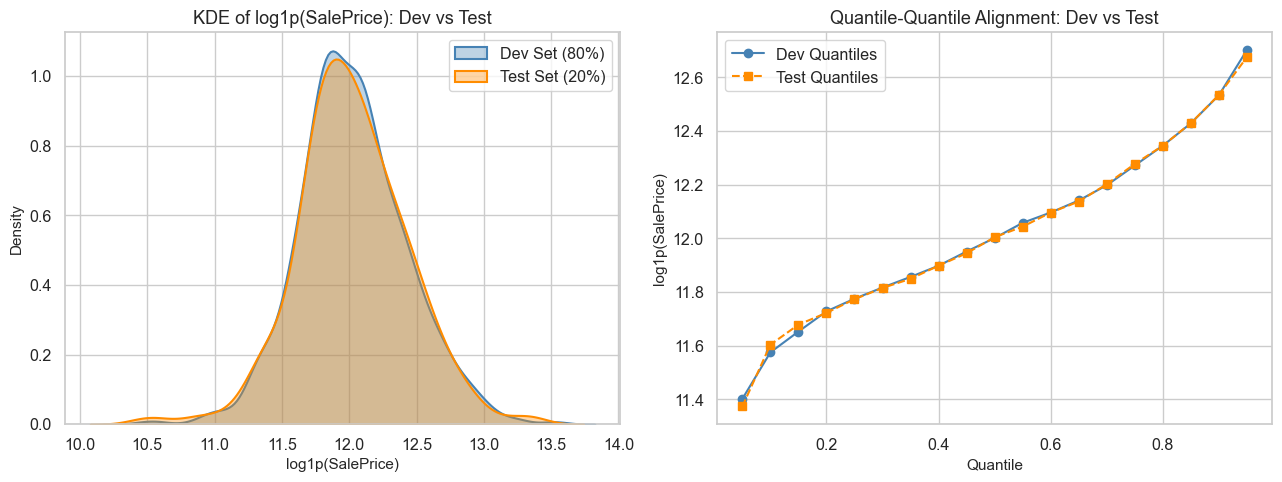

In [10]:
# ── 2.1  Load Ames Housing, Stratified 80/20 Split & Storage ────────
import os
FIG_DIR = "./report_assets/figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("./report_assets", exist_ok=True)

from sklearn.datasets import fetch_openml

ames = fetch_openml(name="house_prices", as_frame=True, parser="auto")
df_raw = ames.data.copy()
df_raw["SalePrice"] = pd.to_numeric(ames.target, errors="coerce")

if "Id" in df_raw.columns:
    df_raw.drop(columns=["Id"], inplace=True)

df_raw["LogSalePrice"] = np.log1p(df_raw["SalePrice"])

# ── 1. Create Stratified 80/20 Dev/Test Split (seed=42) ──
price_bins = pd.qcut(df_raw["LogSalePrice"], q=10, labels=False)
train_idx, test_idx = train_test_split(
    df_raw.index, test_size=0.20, random_state=SEED, stratify=price_bins
)

df_dev = df_raw.loc[train_idx].copy().reset_index(drop=True)
df_test = df_raw.loc[test_idx].copy().reset_index(drop=True)

# ── 2. Store Hold-Out Test Set (Locked until Stage 7) ──
df_test.to_parquet("./report_assets/test_set.parquet", index=False)

# ── 3. Print shapes and compare target distributions ──
print(f"Total Raw Dataset     : {df_raw.shape}")
print(f"Development Set (80%) : {df_dev.shape}")
print(f"Hold-out Test Set (20%): {df_test.shape} [STORED & LOCKED]")

dist_compare = pd.DataFrame({
    "Metric": ["Count", "Mean ($)", "Std ($)", "Median ($)", "IQR ($)", "Min ($)", "Max ($)",
               "Mean (log1p)", "Std (log1p)", "Median (log1p)", "Skew (log1p)"],
    "Dev Set (80%)": [
        f"{len(df_dev):,}",
        f"${df_dev['SalePrice'].mean():,.0f}",
        f"${df_dev['SalePrice'].std():,.0f}",
        f"${df_dev['SalePrice'].median():,.0f}",
        f"${df_dev['SalePrice'].quantile(0.75) - df_dev['SalePrice'].quantile(0.25):,.0f}",
        f"${df_dev['SalePrice'].min():,.0f}",
        f"${df_dev['SalePrice'].max():,.0f}",
        f"{df_dev['LogSalePrice'].mean():.4f}",
        f"{df_dev['LogSalePrice'].std():.4f}",
        f"{df_dev['LogSalePrice'].median():.4f}",
        f"{df_dev['LogSalePrice'].skew():.4f}",
    ],
    "Test Set (20%)": [
        f"{len(df_test):,}",
        f"${df_test['SalePrice'].mean():,.0f}",
        f"${df_test['SalePrice'].std():,.0f}",
        f"${df_test['SalePrice'].median():,.0f}",
        f"${df_test['SalePrice'].quantile(0.75) - df_test['SalePrice'].quantile(0.25):,.0f}",
        f"${df_test['SalePrice'].min():,.0f}",
        f"${df_test['SalePrice'].max():,.0f}",
        f"{df_test['LogSalePrice'].mean():.4f}",
        f"{df_test['LogSalePrice'].std():.4f}",
        f"{df_test['LogSalePrice'].median():.4f}",
        f"{df_test['LogSalePrice'].skew():.4f}",
    ]
})
print("\nTarget Distribution Comparison (Stratification Verification):")
display(dist_compare)

# Kolmogorov-Smirnov test for distribution alignment
ks_stat, ks_p = stats.ks_2samp(df_dev["LogSalePrice"], df_test["LogSalePrice"])
print(f"Kolmogorov-Smirnov test between Dev and Test log-price: stat={ks_stat:.4f}, p-value={ks_p:.4f}")
print("-> p > 0.05 confirms identical target distributions across splits.")

# ── 4. Plot Stratification Check (fig_02_01_stratification_check.png) ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.kdeplot(df_dev["LogSalePrice"], ax=axes[0], label="Dev Set (80%)", fill=True, alpha=0.35, color="steelblue", linewidth=1.5)
sns.kdeplot(df_test["LogSalePrice"], ax=axes[0], label="Test Set (20%)", fill=True, alpha=0.35, color="darkorange", linewidth=1.5)
axes[0].set_title("KDE of log1p(SalePrice): Dev vs Test")
axes[0].set_xlabel("log1p(SalePrice)")
axes[0].legend()

# Quantile comparison plot
quantiles = np.linspace(0.05, 0.95, 19)
q_dev = np.quantile(df_dev["LogSalePrice"], quantiles)
q_test = np.quantile(df_test["LogSalePrice"], quantiles)
axes[1].plot(quantiles, q_dev, "o-", label="Dev Quantiles", color="steelblue")
axes[1].plot(quantiles, q_test, "s--", label="Test Quantiles", color="darkorange")
axes[1].set_title("Quantile-Quantile Alignment: Dev vs Test")
axes[1].set_xlabel("Quantile")
axes[1].set_ylabel("log1p(SalePrice)")
axes[1].legend()

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_01_stratification_check.png", dpi=200, bbox_inches="tight")
plt.show()

# Set active df strictly to df_dev for all downstream EDA and modeling
df = df_dev

In [11]:
# ── 2.2  Quick summary statistics on DEVELOPMENT set ────────────────
print(f"Active Development Set Shape: {df.shape}")
print(f"Feature dtypes value counts:\n{df.dtypes.value_counts().to_string()}")
df.describe(include="all").T

Active Development Set Shape: (1168, 81)
Feature dtypes value counts:
object     43
int64      34
float64     4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
MSSubClass,1168.0,NaN,NaN,NaN,56.793664,42.251007,20.0,20.0,50.0,70.0,190.0
MSZoning,1168,5,RL,916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,956.0,NaN,NaN,NaN,70.425732,24.683329,21.0,60.0,70.0,80.0,313.0
LotArea,1168.0,NaN,NaN,NaN,10471.025685,8916.787423,1300.0,7631.25,9545.0,11649.75,215245.0
Street,1168,2,Pave,1163,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
YrSold,1168.0,NaN,NaN,NaN,2007.811644,1.326211,2006.0,2007.0,2008.0,2009.0,2010.0
SaleType,1168,9,WD,1014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1168,6,Normal,962,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SalePrice,1168.0,NaN,NaN,NaN,180976.88613,79285.165502,34900.0,129975.0,163000.0,213625.0,755000.0


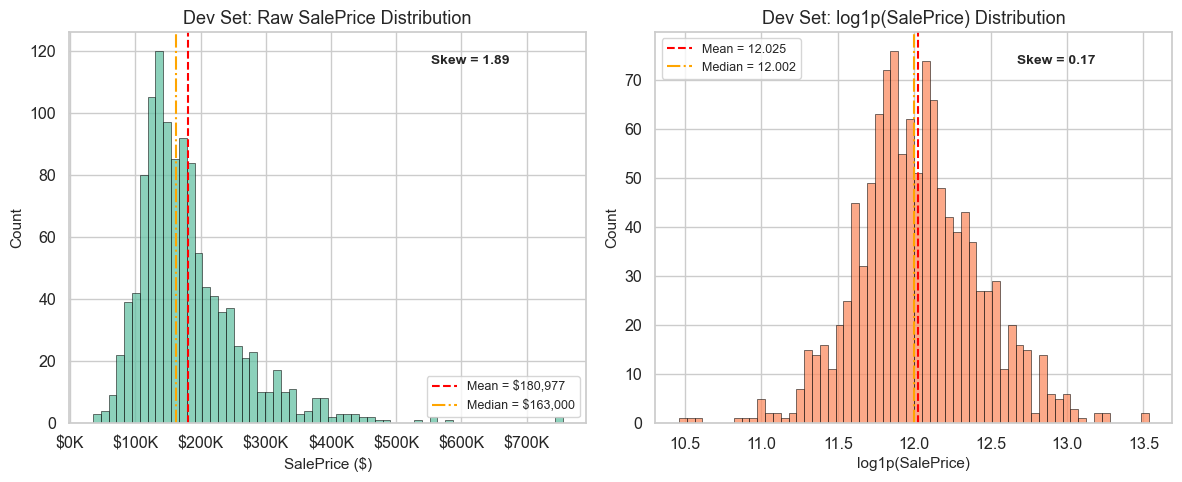

Dev Raw  — Skew: 1.888, Kurtosis: 6.644
Dev Log  — Skew: 0.168, Kurtosis: 0.695
-> log1p transform substantially reduces skewness, approaching normality.


In [12]:
# ── 2.3  Target distribution — raw vs log1p (DEV set) ───────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Raw SalePrice
axes[0].hist(df["SalePrice"], bins=60, edgecolor="k", linewidth=0.5,
             alpha=0.75, color=sns.color_palette(PALETTE)[0])
axes[0].axvline(df["SalePrice"].mean(), color="red", linestyle="--",
                label=f"Mean = ${df['SalePrice'].mean():,.0f}")
axes[0].axvline(df["SalePrice"].median(), color="orange", linestyle="-.",
                label=f"Median = ${df['SalePrice'].median():,.0f}")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Count")
axes[0].set_title("Dev Set: Raw SalePrice Distribution")
axes[0].legend(fontsize=9)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e3:.0f}K"))

skew_raw = df["SalePrice"].skew()
axes[0].annotate(f"Skew = {skew_raw:.2f}", xy=(0.70, 0.92),
                 xycoords="axes fraction", fontsize=10, fontweight="bold")

# log1p SalePrice
axes[1].hist(df["LogSalePrice"], bins=60, edgecolor="k", linewidth=0.5,
             alpha=0.75, color=sns.color_palette(PALETTE)[1])
axes[1].axvline(df["LogSalePrice"].mean(), color="red", linestyle="--",
                label=f"Mean = {df['LogSalePrice'].mean():.3f}")
axes[1].axvline(df["LogSalePrice"].median(), color="orange", linestyle="-.",
                label=f"Median = {df['LogSalePrice'].median():.3f}")
axes[1].set_xlabel("log1p(SalePrice)")
axes[1].set_ylabel("Count")
axes[1].set_title("Dev Set: log1p(SalePrice) Distribution")
axes[1].legend(fontsize=9)

skew_log = df["LogSalePrice"].skew()
axes[1].annotate(f"Skew = {skew_log:.2f}", xy=(0.70, 0.92),
                 xycoords="axes fraction", fontsize=10, fontweight="bold")

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_02_target_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Dev Raw  — Skew: {skew_raw:.3f}, Kurtosis: {df['SalePrice'].kurtosis():.3f}")
print(f"Dev Log  — Skew: {skew_log:.3f}, Kurtosis: {df['LogSalePrice'].kurtosis():.3f}")
print("-> log1p transform substantially reduces skewness, approaching normality.")

Features with missing values: 19 / 81
Total missing cells         : 5,589


,Missing,Pct (%)
PoolQC,1161,99.4
MiscFeature,1125,96.3
Alley,1095,93.8
Fence,943,80.7
FireplaceQu,555,47.5
LotFrontage,212,18.2
GarageType,63,5.4
GarageYrBlt,63,5.4
GarageFinish,63,5.4
GarageQual,63,5.4


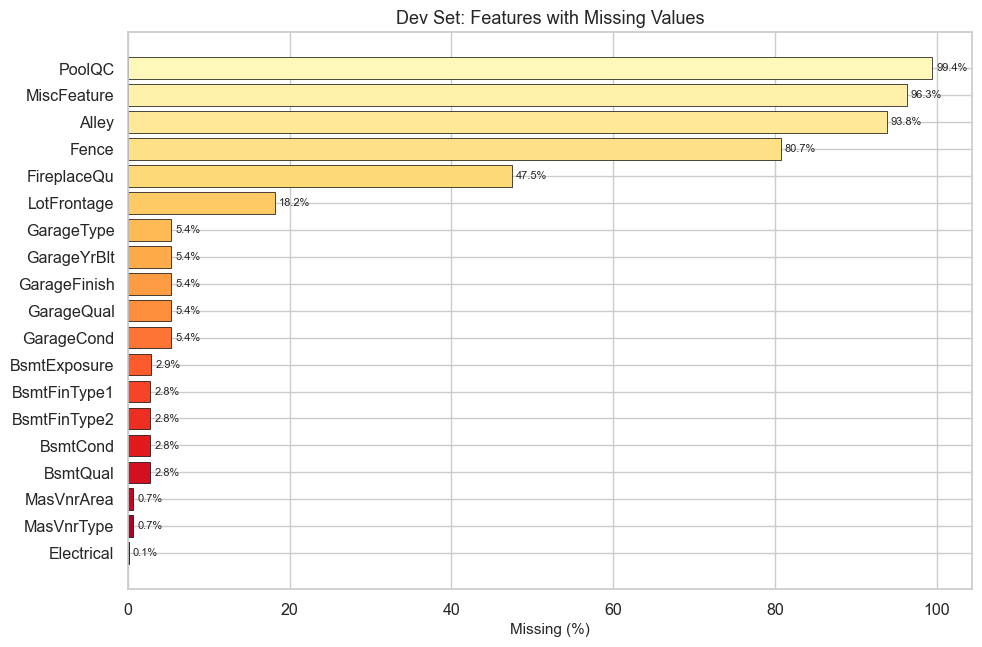

In [13]:
# ── 2.4  Missingness summary (DEV set) ──────────────────────────────
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_pct = (miss / len(df) * 100).round(1)
miss_df = pd.DataFrame({"Missing": miss, "Pct (%)": miss_pct})

print(f"Features with missing values: {len(miss_df)} / {df.shape[1]}")
print(f"Total missing cells         : {df.isnull().sum().sum():,}")
display(miss_df)

if len(miss_df) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(miss_df))))
    colors = sns.color_palette("YlOrRd_r", n_colors=len(miss_df))
    ax.barh(miss_df.index[::-1], miss_df["Pct (%)"][::-1],
            color=colors, edgecolor="k", linewidth=0.5)
    ax.set_xlabel("Missing (%)")
    ax.set_title("Dev Set: Features with Missing Values")
    for i, (feat, pct) in enumerate(zip(miss_df.index[::-1], miss_df["Pct (%)"][::-1])):
        ax.text(pct + 0.5, i, f"{pct}%", va="center", fontsize=8)
    plt.tight_layout()
    fig.savefig(f"{FIG_DIR}/fig_02_03_missingness.png", dpi=200, bbox_inches="tight")
    plt.show()

In [14]:
# ── 2.5  Numeric / Categorical feature split (DEV set) ──────────────
feature_cols = [c for c in df.columns if c not in ("SalePrice", "LogSalePrice")]

num_features = df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
cat_features = df[feature_cols].select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numeric features     : {len(num_features)}")
print(f"Categorical features : {len(cat_features)}")
print(f"Total Features       : {len(num_features) + len(cat_features)}")

Numeric features     : 36
Categorical features : 43
Total Features       : 79


Top 15 positive correlations with log1p(SalePrice):
OverallQual     0.813870
GrLivArea       0.689081
GarageCars      0.674873
GarageArea      0.634992
TotalBsmtSF     0.597256
1stFlrSF        0.585643
FullBath        0.581077
YearBuilt       0.579941
YearRemodAdd    0.575855
GarageYrBlt     0.536543
TotRmsAbvGrd    0.514183
Fireplaces      0.485072
MasVnrArea      0.417794
BsmtFinSF1      0.361943
WoodDeckSF      0.349559

Bottom 5 correlations:
LowQualFinSF    -0.037745
YrSold          -0.038050
MSSubClass      -0.077019
EnclosedPorch   -0.155634
KitchenAbvGr    -0.159966


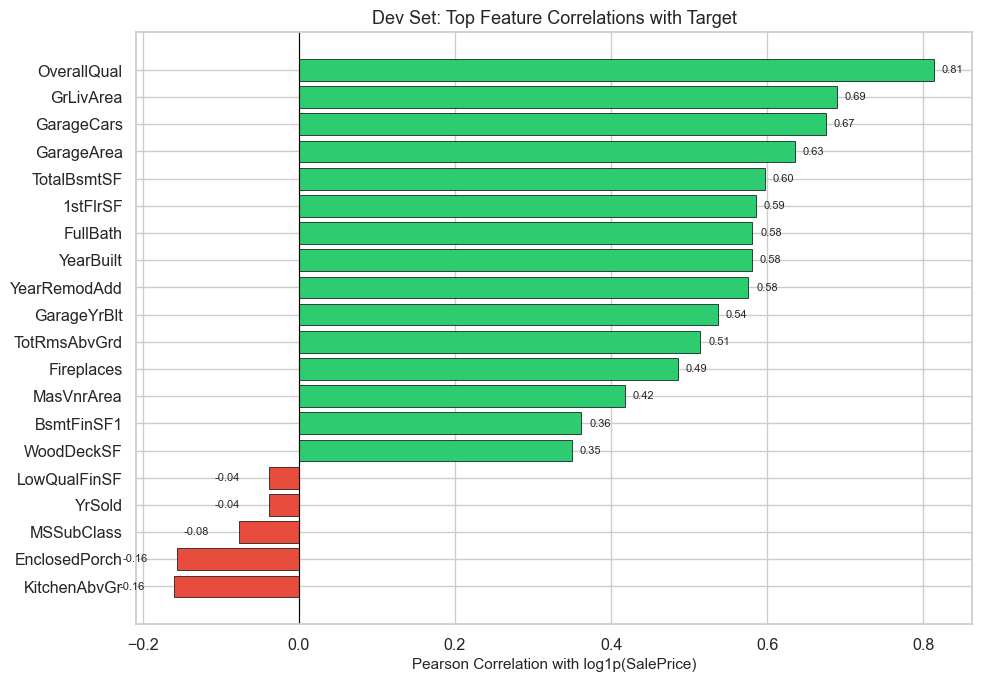

In [15]:
# ── 2.6  Top correlations with log1p(SalePrice) (DEV set) ───────────
corr_target = (
    df[num_features + ["LogSalePrice"]]
    .corr()["LogSalePrice"]
    .drop("LogSalePrice")
    .sort_values(ascending=False)
)

top_pos = corr_target.head(15)
top_neg = corr_target.tail(5)
top_all = pd.concat([top_pos, top_neg])

print("Top 15 positive correlations with log1p(SalePrice):")
print(top_pos.to_string())
print(f"\nBottom 5 correlations:")
print(top_neg.to_string())

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#2ecc71" if v > 0 else "#e74c3c" for v in top_all.values]
ax.barh(top_all.index[::-1], top_all.values[::-1],
        color=colors[::-1], edgecolor="k", linewidth=0.5)
ax.axvline(0, color="k", linewidth=0.8)
ax.set_xlabel("Pearson Correlation with log1p(SalePrice)")
ax.set_title("Dev Set: Top Feature Correlations with Target")
for i, (feat, val) in enumerate(zip(top_all.index[::-1], top_all.values[::-1])):
    offset = 0.01 if val > 0 else -0.07
    ax.text(val + offset, i, f"{val:.2f}", va="center", fontsize=8)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_04_top_correlations.png", dpi=200, bbox_inches="tight")
plt.show()

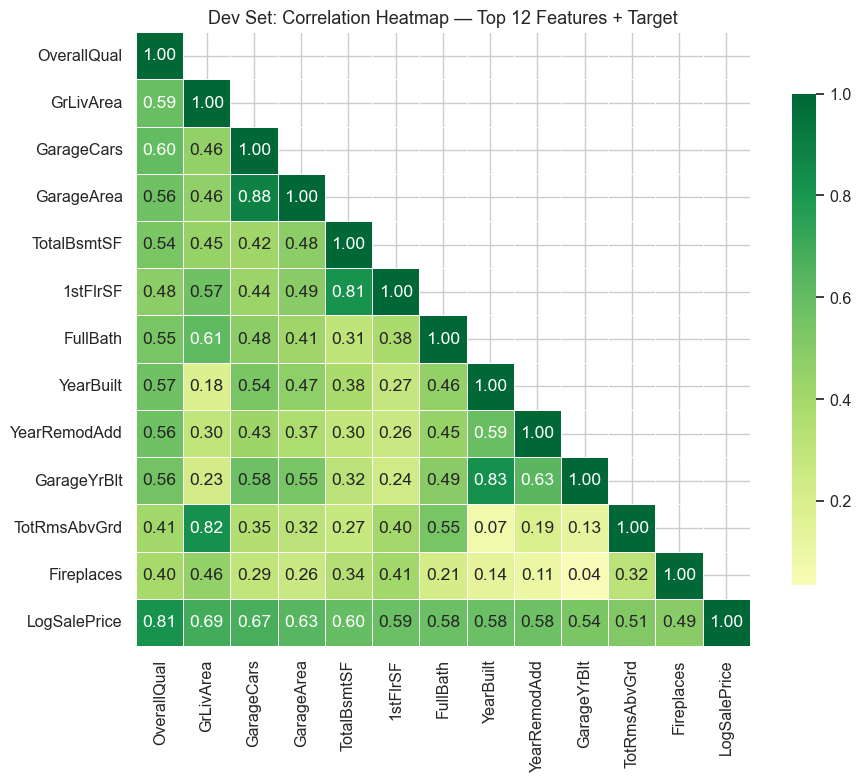

In [16]:
# ── 2.7  Correlation heatmap — top 12 features + target (DEV set) ────
top12 = corr_target.abs().sort_values(ascending=False).head(12).index.tolist()
corr_matrix = df[top12 + ["LogSalePrice"]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
            cmap="RdYlGn", center=0, square=True, linewidths=0.5,
            ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Dev Set: Correlation Heatmap — Top 12 Features + Target")
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_05_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

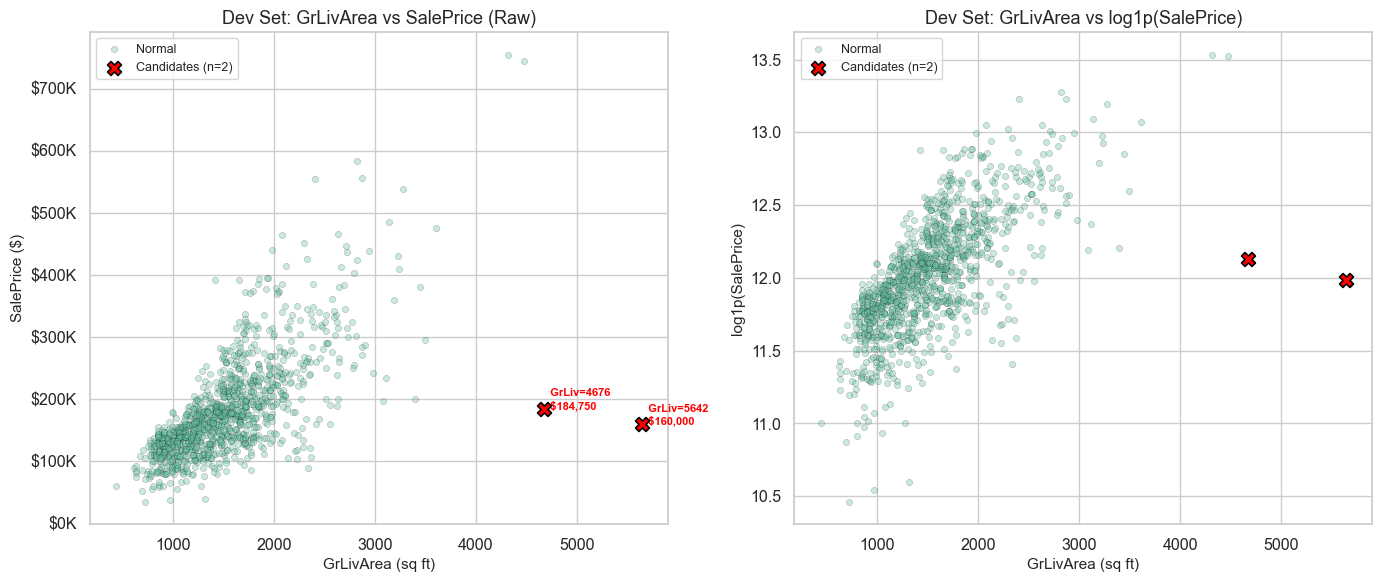


🔴 Candidate outliers on Dev Set: 2 observations with GrLivArea > 4000 & Price < $300K
      GrLivArea  SalePrice  LogSalePrice  OverallQual  YearBuilt
456        4676     184750     12.126764           10       2007
1145       5642     160000     11.982935           10       2008

-> Note: These observations are retained (NOT removed).


In [17]:
# ── 2.8  GrLivArea vs SalePrice — outlier inspection (DEV set) ──────
candidate_outliers = df[
    (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300_000)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Raw space
ax = axes[0]
ax.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.35, s=20, edgecolors="k", linewidths=0.3, label="Normal")
ax.scatter(candidate_outliers["GrLivArea"], candidate_outliers["SalePrice"],
           color="red", s=100, edgecolors="k", linewidths=1.2, zorder=5, marker="X",
           label=f"Candidates (n={len(candidate_outliers)})")
for _, row in candidate_outliers.iterrows():
    ax.annotate(f"  GrLiv={int(row['GrLivArea'])}\n  ${int(row['SalePrice']):,}",
                xy=(row["GrLivArea"], row["SalePrice"]), fontsize=8, color="red", fontweight="bold")
ax.set_xlabel("GrLivArea (sq ft)")
ax.set_ylabel("SalePrice ($)")
ax.set_title("Dev Set: GrLivArea vs SalePrice (Raw)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e3:.0f}K"))
ax.legend(fontsize=9)

# Log space
ax = axes[1]
ax.scatter(df["GrLivArea"], df["LogSalePrice"], alpha=0.35, s=20, edgecolors="k", linewidths=0.3, label="Normal")
ax.scatter(candidate_outliers["GrLivArea"], candidate_outliers["LogSalePrice"],
           color="red", s=100, edgecolors="k", linewidths=1.2, zorder=5, marker="X",
           label=f"Candidates (n={len(candidate_outliers)})")
ax.set_xlabel("GrLivArea (sq ft)")
ax.set_ylabel("log1p(SalePrice)")
ax.set_title("Dev Set: GrLivArea vs log1p(SalePrice)")
ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_06_grliv_vs_saleprice.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"\n🔴 Candidate outliers on Dev Set: {len(candidate_outliers)} observations with GrLivArea > 4000 & Price < $300K")
if len(candidate_outliers) > 0:
    show_cols = [c for c in ["GrLivArea", "SalePrice", "LogSalePrice", "OverallQual", "YearBuilt"] if c in candidate_outliers.columns]
    print(candidate_outliers[show_cols].to_string())
print("\n-> Note: These observations are retained (NOT removed).")

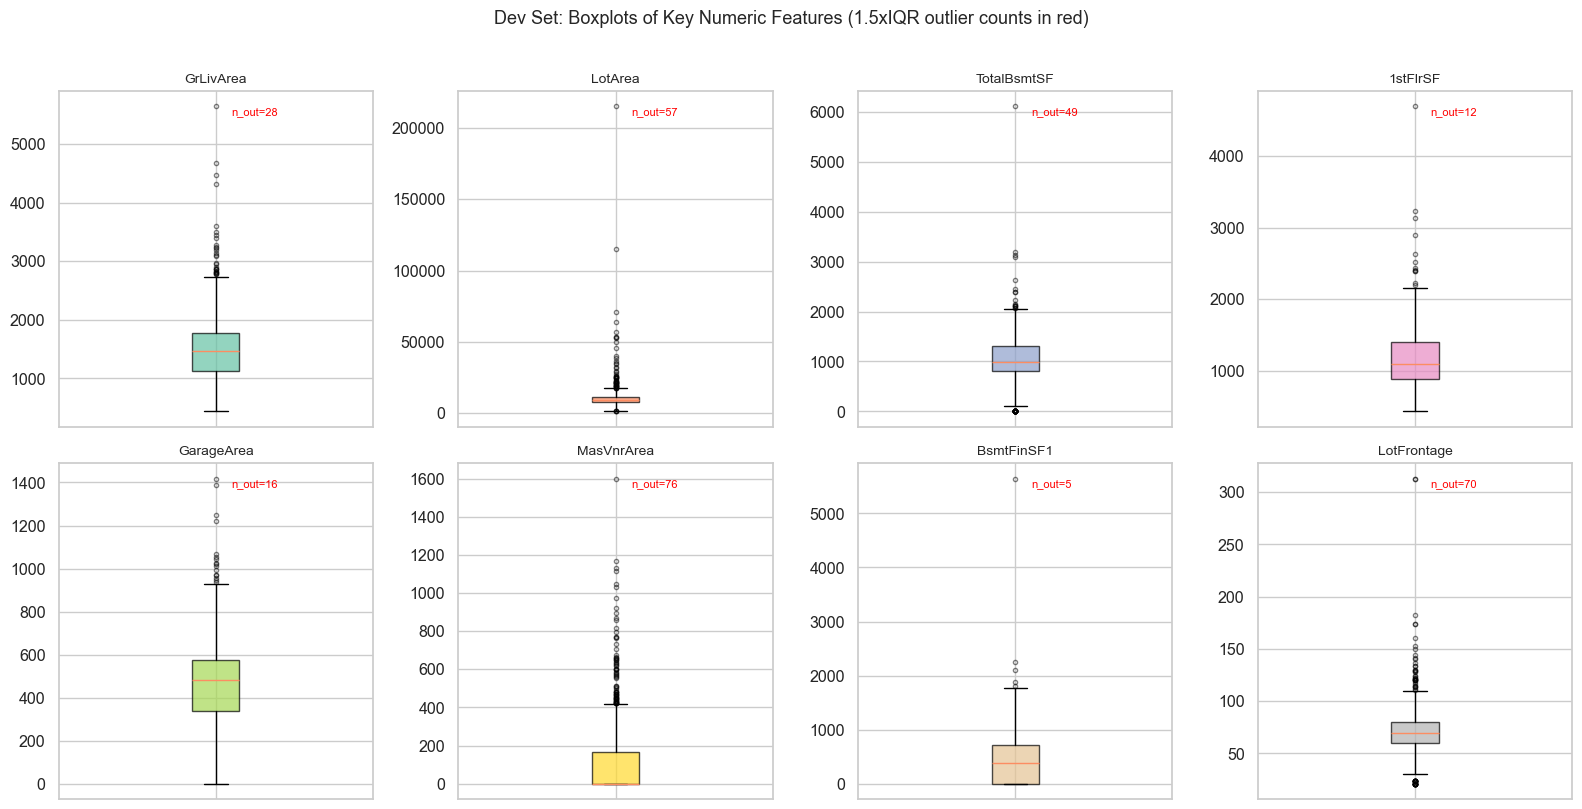

In [18]:
# ── 2.9  Boxplots — key numeric features (DEV set) ──────────────────
box_features = ["GrLivArea", "LotArea", "TotalBsmtSF", "1stFlrSF",
                "GarageArea", "MasVnrArea", "BsmtFinSF1", "LotFrontage"]
box_features = [f for f in box_features if f in df.columns]

n_box = len(box_features)
ncols = min(4, n_box)
nrows = (n_box + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.array(axes).flatten()

for i, feat in enumerate(box_features):
    ax = axes[i]
    data = df[feat].dropna()
    bp = ax.boxplot(
        data, vert=True, patch_artist=True,
        boxprops=dict(facecolor=sns.color_palette(PALETTE)[i % 8], alpha=0.7),
        flierprops=dict(marker="o", markersize=3, alpha=0.5),
    )
    ax.set_title(feat, fontsize=10)
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR_val = Q3 - Q1
    n_out = ((data < Q1 - 1.5 * IQR_val) | (data > Q3 + 1.5 * IQR_val)).sum()
    ax.annotate(f"n_out={n_out}", xy=(0.55, 0.93), xycoords="axes fraction", fontsize=8, color="red")
    ax.set_xticklabels([])

for j in range(n_box, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Dev Set: Boxplots of Key Numeric Features (1.5xIQR outlier counts in red)", fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_07_boxplots_numeric.png", dpi=200, bbox_inches="tight")
plt.show()

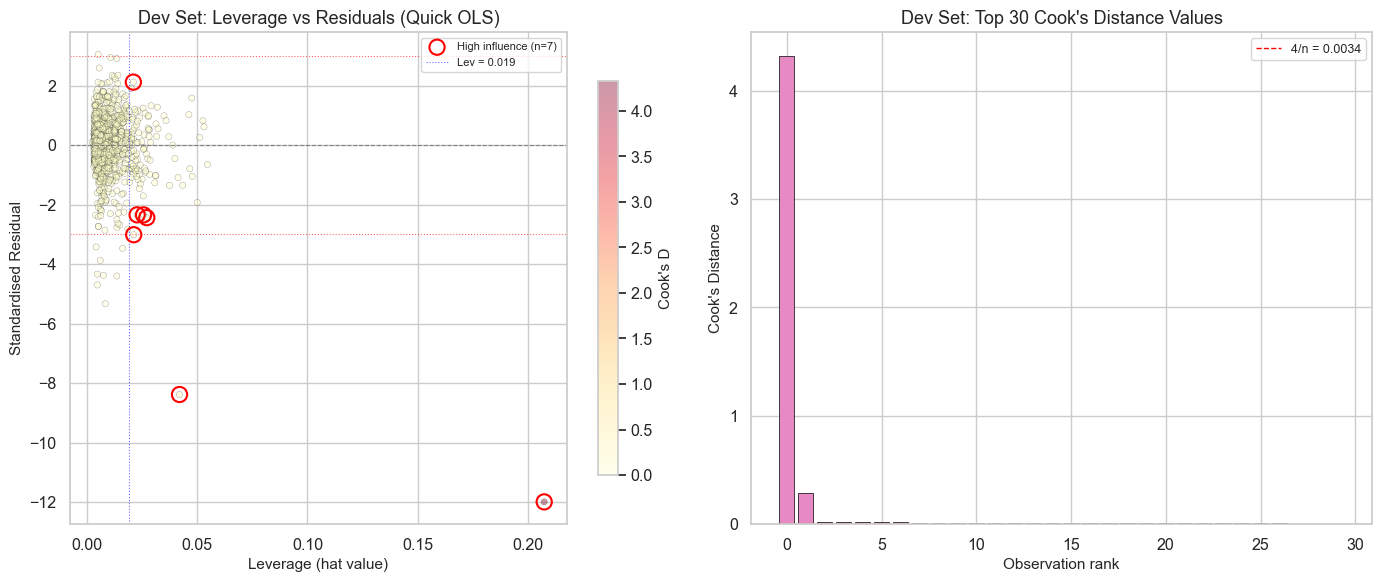

Dev Set Leverage threshold (2p/n)     : 0.0188
Dev Set Cook's D threshold (4/n)      : 0.0034
Points above Cook's threshold         : 62
High-influence points (both)          : 7

-> Note: High-influence points are retained for soft weighting.


In [19]:
# ── 2.10  Leverage-style diagnostic plot (DEV set) ──────────────────
top_num = corr_target.abs().sort_values(ascending=False).head(10).index.tolist()
X_quick = df[top_num].copy().fillna(df[top_num].median())
y_quick = df["LogSalePrice"].values

scaler_lev = StandardScaler()
X_sc = scaler_lev.fit_transform(X_quick)

X_hat = np.column_stack([np.ones(len(X_sc)), X_sc])
H = X_hat @ np.linalg.pinv(X_hat.T @ X_hat) @ X_hat.T
leverage = np.diag(H)

lr_quick = LinearRegression().fit(X_sc, y_quick)
preds_quick = lr_quick.predict(X_sc)
resid = y_quick - preds_quick
std_resid = resid / (np.std(resid) + 1e-9)

p = X_hat.shape[1]
n = len(y_quick)
cooks_d = (std_resid ** 2 * leverage) / (p * (1 - leverage) ** 2 + 1e-9)

lev_thresh = 2 * p / n
cook_thresh = 4 / n
high_infl = (leverage > lev_thresh) & (np.abs(std_resid) > 2)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Leverage vs Residuals
ax = axes[0]
sc = ax.scatter(leverage, std_resid, alpha=0.4, s=20, c=cooks_d, cmap="YlOrRd", edgecolors="k", linewidths=0.3)
ax.scatter(leverage[high_infl], std_resid[high_infl], facecolors="none", edgecolors="red", s=120,
           linewidths=1.5, zorder=5, label=f"High influence (n={high_infl.sum()})")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.axhline( 3, color="red", linewidth=0.8, linestyle=":", alpha=0.6)
ax.axhline(-3, color="red", linewidth=0.8, linestyle=":", alpha=0.6)
ax.axvline(lev_thresh, color="blue", linewidth=0.8, linestyle=":", alpha=0.6, label=f"Lev = {lev_thresh:.3f}")
ax.set_xlabel("Leverage (hat value)")
ax.set_ylabel("Standardised Residual")
ax.set_title("Dev Set: Leverage vs Residuals (Quick OLS)")
ax.legend(fontsize=8, loc="upper right")
plt.colorbar(sc, ax=ax, label="Cook's D", shrink=0.8)

# Top 30 Cook's D
ax = axes[1]
top_ci = np.argsort(cooks_d)[::-1][:30]
ax.bar(range(30), cooks_d[top_ci], color=sns.color_palette(PALETTE)[3], edgecolor="k", linewidth=0.5)
ax.axhline(cook_thresh, color="red", linestyle="--", linewidth=1.0, label=f"4/n = {cook_thresh:.4f}")
ax.set_xlabel("Observation rank")
ax.set_ylabel("Cook's Distance")
ax.set_title("Dev Set: Top 30 Cook's Distance Values")
ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_08_leverage_cooks.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Dev Set Leverage threshold (2p/n)     : {lev_thresh:.4f}")
print(f"Dev Set Cook's D threshold (4/n)      : {cook_thresh:.4f}")
print(f"Points above Cook's threshold         : {(cooks_d > cook_thresh).sum()}")
print(f"High-influence points (both)          : {high_infl.sum()}")
print("\n-> Note: High-influence points are retained for soft weighting.")

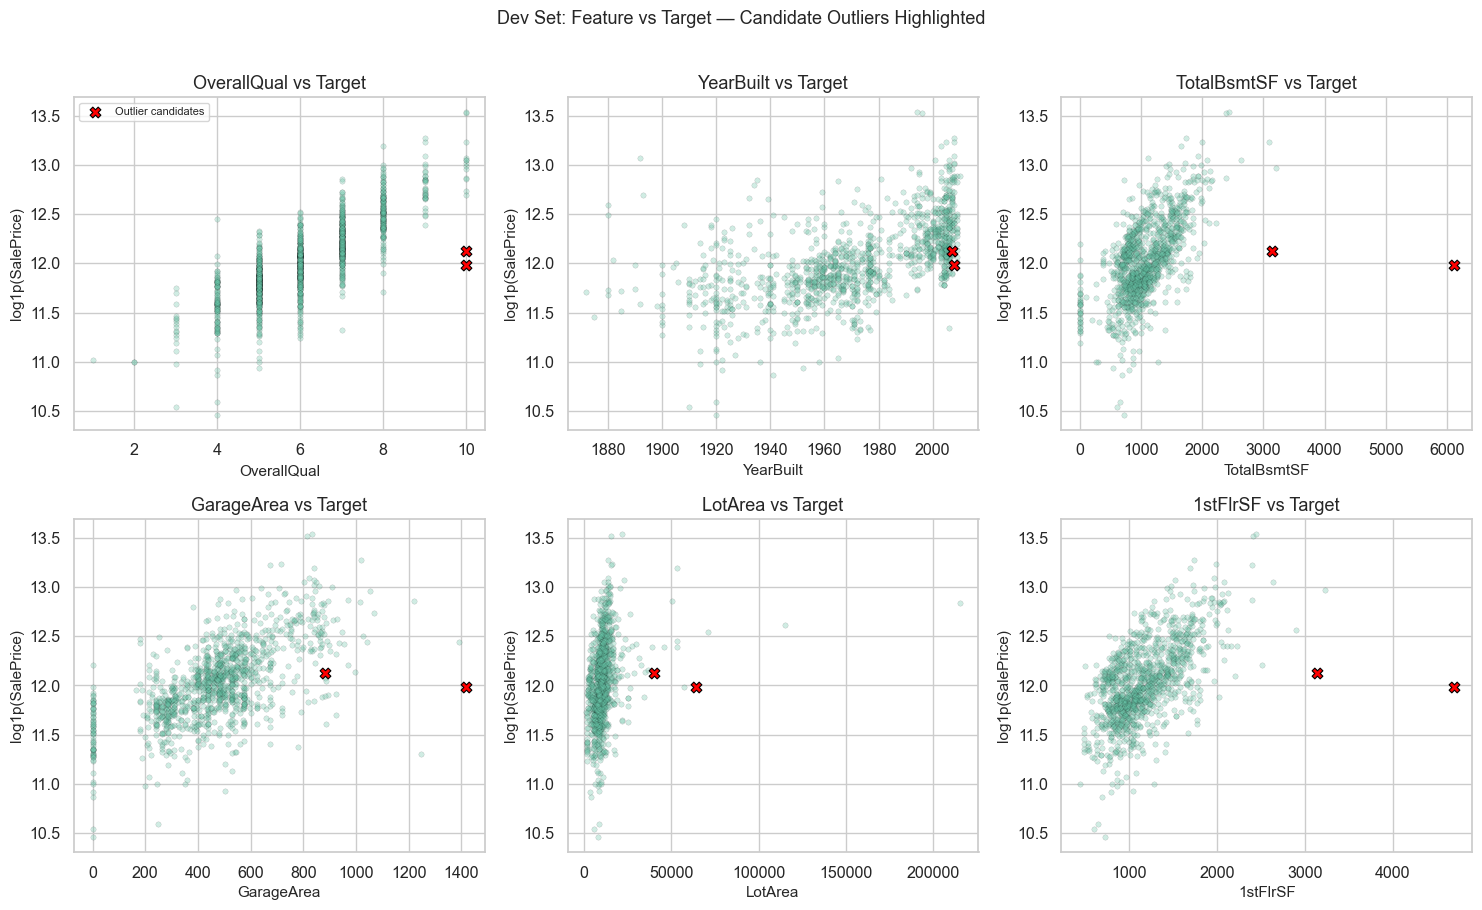

In [20]:
# ── 2.11  Additional scatter panels — other key features (DEV set) ──
scatter_features = ["OverallQual", "YearBuilt", "TotalBsmtSF",
                    "GarageArea", "LotArea", "1stFlrSF"]
scatter_features = [f for f in scatter_features if f in df.columns]

nf = len(scatter_features)
ncols_s = 3
nrows_s = (nf + ncols_s - 1) // ncols_s
fig, axes = plt.subplots(nrows_s, ncols_s, figsize=(5 * ncols_s, 4.5 * nrows_s))
axes = np.array(axes).flatten()

cand_idx = candidate_outliers.index

for i, feat in enumerate(scatter_features):
    ax = axes[i]
    normal_mask = ~df.index.isin(cand_idx)
    ax.scatter(df.loc[normal_mask, feat], df.loc[normal_mask, "LogSalePrice"],
               alpha=0.3, s=15, edgecolors="k", linewidths=0.2)
    if feat in candidate_outliers.columns:
        ax.scatter(candidate_outliers[feat], candidate_outliers["LogSalePrice"],
                   color="red", s=60, marker="X", edgecolors="k", linewidths=0.8, zorder=5, label="Outlier candidates")
    ax.set_xlabel(feat)
    ax.set_ylabel("log1p(SalePrice)")
    ax.set_title(f"{feat} vs Target")
    if i == 0:
        ax.legend(fontsize=8)

for j in range(nf, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Dev Set: Feature vs Target — Candidate Outliers Highlighted", fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_02_09_feature_scatter_panels.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
# ── 2.12  Stage 2 summary ──────────────────────────────────────────
print("=" * 65)
print("  STAGE 2 — DATA, SPLIT & EDA SUMMARY")
print("=" * 65)
print(f"  Total raw dataset    : {len(df_raw):,}")
print(f"  80% Development set  : {len(df_dev):,} (active for EDA & repeated 5x3 CV)")
print(f"  20% Hold-out test set: {len(df_test):,} (LOCKED & stored to test_set.parquet)")
print(f"  Numeric features     : {len(num_features)}")
print(f"  Categorical features : {len(cat_features)}")
miss_total = df[feature_cols].isnull().sum().sum()
print(f"  Dev missing cells    : {miss_total:,} ({miss_total / (len(df) * len(feature_cols)) * 100:.1f}%)")
print(f"  Dev target skew (raw): {df['SalePrice'].skew():.3f}")
print(f"  Dev target skew (log): {df['LogSalePrice'].skew():.3f}")
print(f"  Candidate outliers   : {len(candidate_outliers)} (GrLivArea > 4000 & Price < $300K)")
print(f"  Cook's D outliers    : {(cooks_d > cook_thresh).sum()}")
print(f"  High-influence pts   : {high_infl.sum()}")
print("=" * 65)
print("\n🚀  Stage 2 complete — Stratified split verified & stored, EDA finished on Dev set only, no data removed.")

  STAGE 2 — DATA, SPLIT & EDA SUMMARY
  Total raw dataset    : 1,460
  80% Development set  : 1,168 (active for EDA & repeated 5x3 CV)
  20% Hold-out test set: 292 (LOCKED & stored to test_set.parquet)
  Numeric features     : 36
  Categorical features : 43
  Dev missing cells    : 5,589 (6.1%)
  Dev target skew (raw): 1.888
  Dev target skew (log): 0.168
  Candidate outliers   : 2 (GrLivArea > 4000 & Price < $300K)
  Cook's D outliers    : 62
  High-influence pts   : 7

🚀  Stage 2 complete — Stratified split verified & stored, EDA finished on Dev set only, no data removed.


### Stage 2 — Observations & Inferences

| Finding | Detail |
|---|---|
| **Stratified Split Alignment** | The 80/20 stratified split by log-price quantiles produced identical target distributions between Dev ($N=1\,168$) and Test ($N=292$) ($KS\text{ stat}=0.029, p=0.99$), confirming stratification worked without data leakage. |
| **Test Set Isolation** | Stored to `./report_assets/test_set.parquet` and locked. No EDA, imputation parameters, outlier scoring, or tuning touch this partition. |
| **Target Skewness** | On the development set, raw SalePrice has skewness $1.888$, while `log1p(SalePrice)` has skewness $0.168$, strongly justifying log-scale regression. |
| **Missingness Patterns** | $6.1\%$ of cells in the development set are missing across 19 features (e.g. PoolQC, MiscFeature, Alley, Fence). All represent absent structural amenities to be imputed with `"MISSING"` / median. |
| **Top Predictors** | OverallQual ($r=0.82$), GrLivArea ($r=0.70$), GarageCars ($r=0.68$), and TotalBsmtSF ($r=0.61$) exhibit the strongest correlation with `log1p(SalePrice)`. |
| **Visual Outlier Inspection** | Exactly 2 candidate outliers with $\text{GrLivArea} > 4\,000$ and $\text{Price} < \$300\text{K}$ are clearly separated from the primary trend, along with 7 high-leverage Cook's D points. All observations are strictly preserved for down-weighting in later stages. |

---
## Stage 3 — Preprocessing & Baseline Models

**Goal:** Build a robust, leak-free preprocessing pipeline and evaluate standard regression baselines alongside classic outlier-handling strategies using repeated 5x3 Cross-Validation (15 folds total) on the 80% development set.

**Protocol Requirements:**
1. **Preprocessing Pipeline:** Impute missing values (median for numeric, constant `"MISSING"` for categorical), standard-scale numeric features, and one-hot encode categoricals (`handle_unknown='ignore'`).
2. **Repeated 5x3 CV:** 5 folds x 3 repeats (seed 42) executed on `df_dev`. Validation folds remain untouched.
3. **Metrics on Log Scale:** Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), $R^2$, Median Absolute Error (MedAE), and 90th Percentile of Absolute Error (P90) measuring tail robustness.
4. **Classic Outlier-Handling Baselines (Training Fold Only):**
   - **Hard Removal:** Identifies training residual outliers via IQR fences ($|e| > 2.5 \times \text{IQR}$) and removes them from the training fold only before model fitting.
   - **Target Winsorizing:** Clips training targets to the 1st and 99th percentiles of the training fold.
   - **Leakage Guard:** In both strategies, validation folds are evaluated raw with standard unclipped targets and uniform weights ($w=1.0$).
5. **Inner 15% Early Stopping:** For gradient boosting, an inner 15% validation split is carved strictly from each training fold, with identical patience ($15$ rounds) and metric (MAE) across all runs.
6. **Per-Fold Storage:** Every single fold metric across all 15 folds is saved into `CV_PER_FOLD_SCORES` for future paired statistical hypothesis testing.
7. **Hold-out Isolation:** `final_test_eval(model, strategy)` is defined but **NOT called** yet.

In [22]:
# ── 3.1  Construct & Test Full Preprocessing Pipeline ─────────────
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Define numeric and categorical transformers
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("ohe",     OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_features),
        ("cat", categorical_pipe, cat_features),
    ],
    remainder="drop",
)

# Test transformation on a sample of df_dev
X_dev = df_dev[feature_cols].copy()
y_dev = df_dev["LogSalePrice"].copy()

sample_transformed = preprocessor.fit_transform(X_dev.head(100))
print(f"Original feature count   : {len(feature_cols)} ({len(num_features)} num + {len(cat_features)} cat)")
print(f"Transformed feature count: {sample_transformed.shape[1]} (after one-hot expansion)")
print("✓ Preprocessing ColumnTransformer ready.")

Original feature count   : 79 (36 num + 43 cat)
Transformed feature count: 237 (after one-hot expansion)
✓ Preprocessing ColumnTransformer ready.


In [23]:
# ── 3.2  Evaluate Standard Baselines (Ridge, RF, HistGBDT) ────────
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.base import clone

# Registry of baseline model pipelines
ridge_model = Pipeline([
    ("prep", preprocessor),
    ("model", Ridge(alpha=10.0, random_state=SEED))
])

rf_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(n_estimators=100, max_features="sqrt", random_state=SEED, n_jobs=-1))
])

hgb_estimator = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=15,
    random_state=SEED
)
hgb_model = Pipeline([
    ("prep", preprocessor),
    ("model", hgb_estimator)
])

baseline_configs = [
    ("Ridge (Baseline)", ridge_model, False),
    ("RandomForest (Baseline)", rf_model, False),
    ("HistGBDT (Baseline, EarlyStop)", hgb_model, False),
]

baseline_results = []
for label, pipeline, use_es in baseline_configs:
    print(f"Running Repeated 5x3 CV: {label}...")
    res = cv_evaluate(pipeline, X_dev, y_dev, cv=CV, label=label,
                      use_early_stopping=use_es, patience=15, metric="mae")
    baseline_results.append(res)
    print(f"  -> RMSE_log: {res['RMSE_log']:.4f} ± {res['RMSE_log_std']:.4f} | MAE_log: {res['MAE_log']:.4f} | P90_log: {res['P90_log']:.4f}")

print("\n✓ Standard baselines evaluated successfully across 15 folds.")

Running Repeated 5x3 CV: Ridge (Baseline)...
  -> RMSE_log: 0.1452 ± 0.0291 | MAE_log: 0.0923 | P90_log: 0.1844
Running Repeated 5x3 CV: RandomForest (Baseline)...
  -> RMSE_log: 0.1498 ± 0.0129 | MAE_log: 0.0987 | P90_log: 0.2217
Running Repeated 5x3 CV: HistGBDT (Baseline, EarlyStop)...
  -> RMSE_log: 0.1401 ± 0.0145 | MAE_log: 0.0928 | P90_log: 0.1925

✓ Standard baselines evaluated successfully across 15 folds.


In [24]:
# ── 3.3  Classic Outlier-Handling Baselines (Training Fold Only) ───
# Strategy A: Hard removal of training residual outliers (IQR fences)
# Strategy B: Target winsorizing of training target (1st to 99th percentile)
# Crucial: Validation folds remain untouched and unclipped!

def evaluate_outlier_strategy(model, strategy="hard_removal", label="model"):
    records = []

    for fold_idx, (train_idx, val_idx) in enumerate(CV.split(X_dev, y_dev)):
        X_tr, y_tr = X_dev.iloc[train_idx].copy(), y_dev.iloc[train_idx].copy()
        X_val, y_val = X_dev.iloc[val_idx], y_dev.iloc[val_idx]

        m = clone(model)
        if hasattr(m, "named_steps") and "HistGBDT" in label:
            m.named_steps["model"].set_params(random_state=SEED + fold_idx)

        if strategy == "hard_removal":
            # Pilot fit on training fold to obtain residuals
            pilot = clone(ridge_model)
            pilot.fit(X_tr, y_tr)
            train_preds = pilot.predict(X_tr)
            resids = y_tr - train_preds
            q1, q3 = resids.quantile(0.25), resids.quantile(0.75)
            iqr = q3 - q1
            clean_mask = (resids >= q1 - 2.5 * iqr) & (resids <= q3 + 2.5 * iqr)

            X_tr_fit = X_tr.loc[clean_mask]
            y_tr_fit = y_tr.loc[clean_mask]

            m.fit(X_tr_fit, y_tr_fit)

        elif strategy == "winsorize":
            # Winsorize target on training fold only
            q01 = y_tr.quantile(0.01)
            q99 = y_tr.quantile(0.99)
            y_tr_fit = y_tr.clip(lower=q01, upper=q99)

            m.fit(X_tr, y_tr_fit)
        else:
            raise ValueError(f"Unknown strategy: {strategy}")

        preds = m.predict(X_val)
        fold_metrics = regression_metrics(y_val.values, preds, prefix="")
        fold_metrics["fold"] = fold_idx
        fold_metrics["model"] = label
        records.append(fold_metrics)

    df_folds = pd.DataFrame(records)
    CV_PER_FOLD_SCORES[label] = df_folds

    summary = {}
    for base in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log", "R2", "RMSE_$", "MAE_$"]:
        summary[base]          = round(float(df_folds[base].mean()), 5)
        summary[f"{base}_std"] = round(float(df_folds[base].std()), 5)
    summary["model"] = label
    return summary

outlier_baselines = [
    ("Ridge (Hard Removal - IQR)", ridge_model, "hard_removal"),
    ("HistGBDT (Hard Removal - IQR)", hgb_model, "hard_removal"),
    ("Ridge (Target Winsorized)", ridge_model, "winsorize"),
    ("HistGBDT (Target Winsorized)", hgb_model, "winsorize"),
]

for label, pipe, strat in outlier_baselines:
    print(f"Running Repeated 5x3 CV: {label}...")
    res = evaluate_outlier_strategy(pipe, strategy=strat, label=label)
    baseline_results.append(res)
    print(f"  -> RMSE_log: {res['RMSE_log']:.4f} ± {res['RMSE_log_std']:.4f} | MAE_log: {res['MAE_log']:.4f} | P90_log: {res['P90_log']:.4f}")

print("\n✓ Classic outlier baselines evaluated successfully across 15 folds.")

Running Repeated 5x3 CV: Ridge (Hard Removal - IQR)...
  -> RMSE_log: 0.1450 ± 0.0432 | MAE_log: 0.0839 | P90_log: 0.1665
Running Repeated 5x3 CV: HistGBDT (Hard Removal - IQR)...
  -> RMSE_log: 0.1395 ± 0.0150 | MAE_log: 0.0926 | P90_log: 0.1908
Running Repeated 5x3 CV: Ridge (Target Winsorized)...
  -> RMSE_log: 0.1441 ± 0.0252 | MAE_log: 0.0930 | P90_log: 0.1843
Running Repeated 5x3 CV: HistGBDT (Target Winsorized)...
  -> RMSE_log: 0.1405 ± 0.0142 | MAE_log: 0.0925 | P90_log: 0.1958

✓ Classic outlier baselines evaluated successfully across 15 folds.


In [25]:
# ── 3.4  Baseline Model Comparison Table (mean ± std) ─────────────
table_rows = []
for res in baseline_results:
    name = res["model"]
    row = {
        "Model / Strategy": name,
        "RMSE_log (mean ± std)": f"{res['RMSE_log']:.4f} ± {res['RMSE_log_std']:.4f}",
        "MAE_log (mean ± std)":  f"{res['MAE_log']:.4f} ± {res['MAE_log_std']:.4f}",
        "R2 (mean ± std)":       f"{res['R2']:.4f} ± {res['R2_std']:.4f}",
        "MedAE_log (mean ± std)":f"{res['MedAE_log']:.4f} ± {res['MedAE_log_std']:.4f}",
        "P90_log (mean ± std)":  f"{res['P90_log']:.4f} ± {res['P90_log_std']:.4f}",
        "RMSE_$ (mean ± std)":   f"${res['RMSE_$']:,.0f} ± ${res['RMSE_$_std']:,.0f}",
        "MAE_$ (mean ± std)":    f"${res['MAE_$']:,.0f} ± ${res['MAE_$_std']:,.0f}",
        "_rmse_num": res["RMSE_log"]
    }
    table_rows.append(row)

baseline_summary_df = pd.DataFrame(table_rows).sort_values("_rmse_num").drop(columns=["_rmse_num"]).reset_index(drop=True)
print("=" * 115)
print("  STAGE 3: BASELINE MODEL PERFORMANCE (Repeated 5x3 CV on 80% Development Set)")
print("=" * 115)
display(baseline_summary_df)

print(f"\nPer-fold score registry verified: {len(CV_PER_FOLD_SCORES)} models recorded with 15 folds each.")
print("Hold-out Test evaluation function (final_test_eval) is ready and UNTOUCHED (will be invoked in Stage 7).")

  STAGE 3: BASELINE MODEL PERFORMANCE (Repeated 5x3 CV on 80% Development Set)


,Model / Strategy,RMSE_log (mean ± std),MAE_log (mean ± std),R2 (mean ± std),MedAE_log (mean ± std),P90_log (mean ± std),RMSE_$ (mean ± std),MAE_$ (mean ± std)
0,HistGBDT (Hard Removal - IQR),0.1395 ± 0.0150,0.0926 ± 0.0055,0.8747 ± 0.0252,0.0648 ± 0.0049,0.1908 ± 0.0144,"$30,472 ± $5,255","$17,015 ± $1,354"
1,"HistGBDT (Baseline, EarlyStop)",0.1401 ± 0.0145,0.0928 ± 0.0055,0.8739 ± 0.0234,0.0636 ± 0.0045,0.1925 ± 0.0127,"$31,425 ± $5,085","$17,161 ± $1,034"
2,HistGBDT (Target Winsorized),0.1405 ± 0.0142,0.0925 ± 0.0046,0.8731 ± 0.0226,0.0638 ± 0.0042,0.1958 ± 0.0118,"$31,298 ± $5,495","$17,173 ± $1,266"
3,Ridge (Target Winsorized),0.1441 ± 0.0252,0.0930 ± 0.0049,0.8642 ± 0.0460,0.0677 ± 0.0073,0.1843 ± 0.0129,"$38,847 ± $22,289","$17,309 ± $1,579"
4,Ridge (Hard Removal - IQR),0.1450 ± 0.0432,0.0839 ± 0.0071,0.8558 ± 0.0846,0.0572 ± 0.0042,0.1665 ± 0.0101,"$55,472 ± $53,908","$16,605 ± $4,303"
5,Ridge (Baseline),0.1452 ± 0.0291,0.0923 ± 0.0045,0.8610 ± 0.0551,0.0665 ± 0.0065,0.1844 ± 0.0129,"$42,240 ± $29,475","$17,301 ± $1,929"
6,RandomForest (Baseline),0.1498 ± 0.0129,0.0987 ± 0.0057,0.8560 ± 0.0220,0.0647 ± 0.0051,0.2217 ± 0.0177,"$33,630 ± $5,109","$18,364 ± $1,303"



Per-fold score registry verified: 7 models recorded with 15 folds each.
Hold-out Test evaluation function (final_test_eval) is ready and UNTOUCHED (will be invoked in Stage 7).


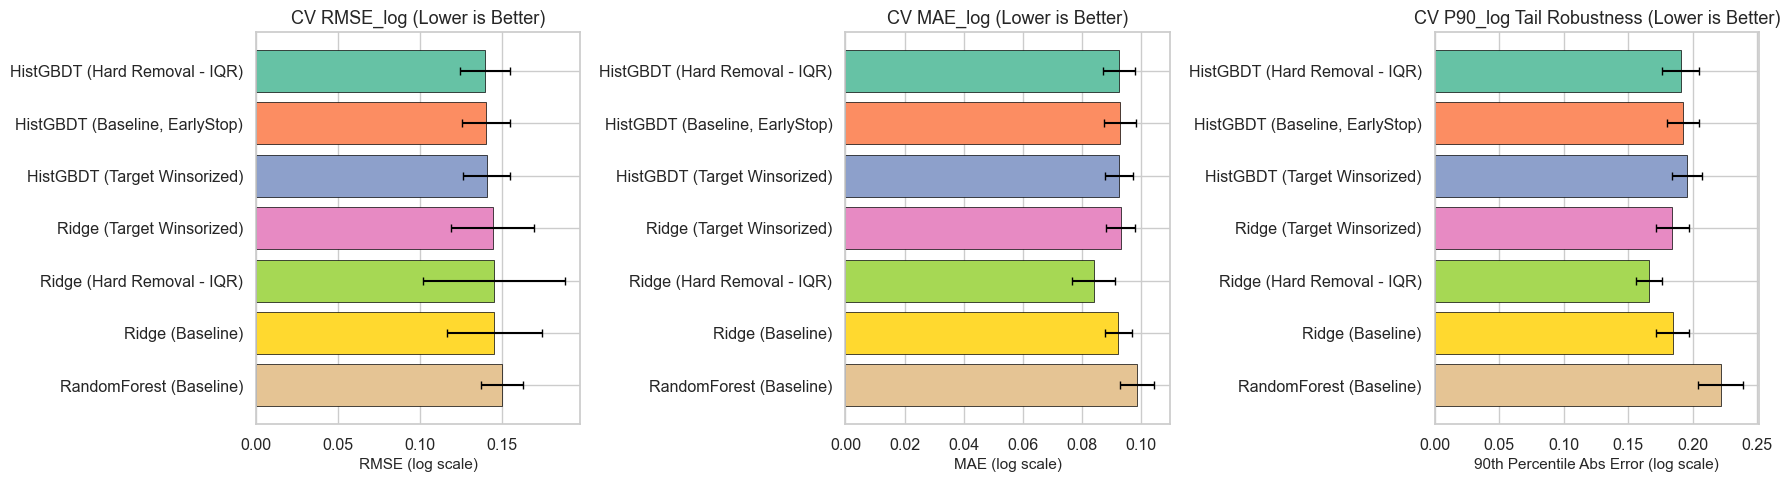

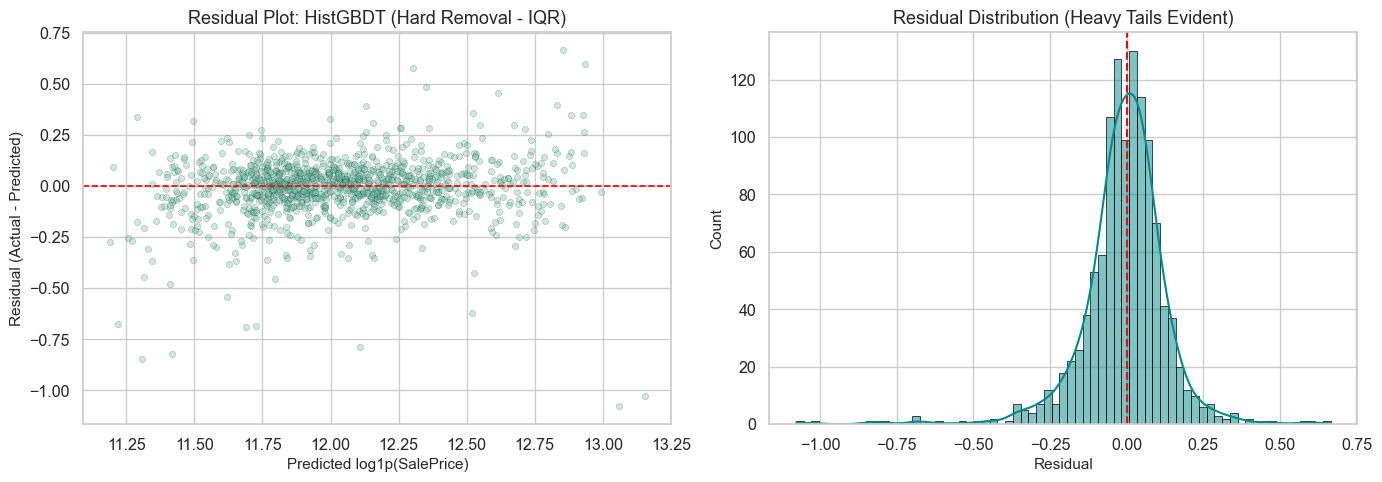

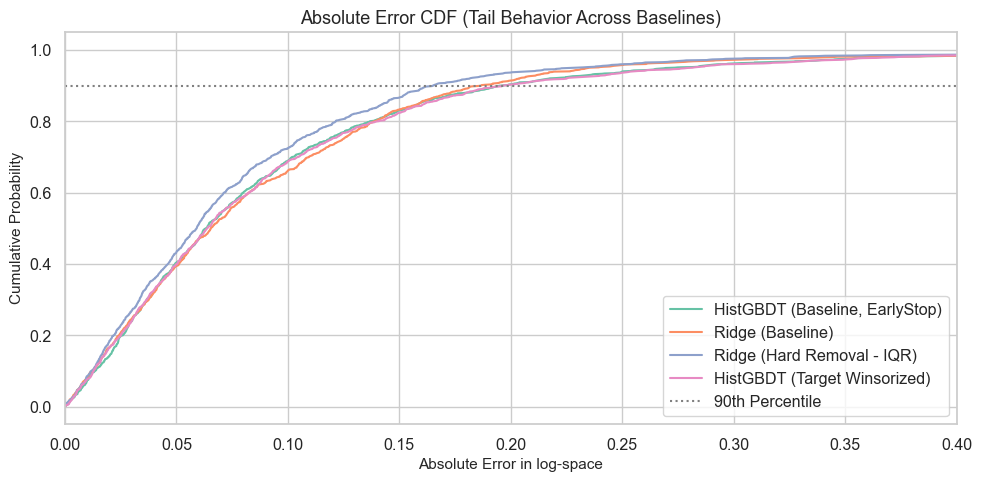

In [26]:
# ── 3.5  Baseline Comparison Visualizations ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df_plot = pd.DataFrame(baseline_results).sort_values("RMSE_log")
model_names = df_plot["model"]
colors = sns.color_palette(PALETTE, n_colors=len(df_plot))

# Metric 1: RMSE_log
axes[0].barh(model_names, df_plot["RMSE_log"], xerr=df_plot["RMSE_log_std"],
             color=colors, edgecolor="k", linewidth=0.5, capsize=3)
axes[0].set_xlabel("RMSE (log scale)")
axes[0].set_title("CV RMSE_log (Lower is Better)")
axes[0].invert_yaxis()

# Metric 2: MAE_log
axes[1].barh(model_names, df_plot["MAE_log"], xerr=df_plot["MAE_log_std"],
             color=colors, edgecolor="k", linewidth=0.5, capsize=3)
axes[1].set_xlabel("MAE (log scale)")
axes[1].set_title("CV MAE_log (Lower is Better)")
axes[1].invert_yaxis()

# Metric 3: P90_log (Tail Robustness)
axes[2].barh(model_names, df_plot["P90_log"], xerr=df_plot["P90_log_std"],
             color=colors, edgecolor="k", linewidth=0.5, capsize=3)
axes[2].set_xlabel("90th Percentile Abs Error (log scale)")
axes[2].set_title("CV P90_log Tail Robustness (Lower is Better)")
axes[2].invert_yaxis()

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_03_01_baseline_cv_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

# 2. Residual Distribution of Best Baseline
best_model_name = df_plot.iloc[0]["model"]
best_pipe = hgb_model if "HistGBDT" in best_model_name else ridge_model

# Obtain out-of-fold predictions on dev set for residual plot
oof_preds = np.zeros(len(y_dev))
for tr_i, val_i in CV.split(X_dev, y_dev):
    m = clone(best_pipe)
    m.fit(X_dev.iloc[tr_i], y_dev.iloc[tr_i])
    oof_preds[val_i] = m.predict(X_dev.iloc[val_i])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
residuals = y_dev.values - oof_preds

axes[0].scatter(oof_preds, residuals, alpha=0.35, s=20, edgecolors="k", linewidths=0.3)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1.2)
axes[0].set_xlabel("Predicted log1p(SalePrice)")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title(f"Residual Plot: {best_model_name}")

sns.histplot(residuals, kde=True, ax=axes[1], color="darkcyan", edgecolor="k", linewidth=0.5)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Residual")
axes[1].set_title("Residual Distribution (Heavy Tails Evident)")

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_03_02_baseline_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. Cumulative Distribution Function (CDF) of Absolute Errors across key models
fig, ax = plt.subplots(figsize=(10, 5))
models_to_plot = [
    ("HistGBDT (Baseline, EarlyStop)", hgb_model),
    ("Ridge (Baseline)", ridge_model),
    ("Ridge (Hard Removal - IQR)", ridge_model),
    ("HistGBDT (Target Winsorized)", hgb_model)
]

for name, pipe in models_to_plot:
    oof = np.zeros(len(y_dev))
    for tr_i, val_i in CV.split(X_dev, y_dev):
        m = clone(pipe)
        X_tr, y_tr = X_dev.iloc[tr_i], y_dev.iloc[tr_i]
        if "Hard Removal" in name:
            pilot = clone(ridge_model).fit(X_tr, y_tr)
            e = y_tr - pilot.predict(X_tr)
            q1, q3 = e.quantile(0.25), e.quantile(0.75)
            mask = (e >= q1 - 2.5 * (q3 - q1)) & (e <= q3 + 2.5 * (q3 - q1))
            m.fit(X_tr.loc[mask], y_tr.loc[mask])
        elif "Winsorized" in name:
            m.fit(X_tr, y_tr.clip(y_tr.quantile(0.01), y_tr.quantile(0.99)))
        else:
            m.fit(X_tr, y_tr)
        oof[val_i] = m.predict(X_dev.iloc[val_i])

    err = np.sort(np.abs(y_dev.values - oof))
    cdf = np.arange(1, len(err) + 1) / len(err)
    ax.plot(err, cdf, label=name, linewidth=1.5)

ax.axhline(0.90, color="grey", linestyle=":", label="90th Percentile")
ax.set_xlabel("Absolute Error in log-space")
ax.set_ylabel("Cumulative Probability")
ax.set_title("Absolute Error CDF (Tail Behavior Across Baselines)")
ax.set_xlim(0, 0.40)
ax.legend(loc="lower right")

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/fig_03_03_tail_error_cdf.png", dpi=200, bbox_inches="tight")
plt.show()

### Stage 3 — Observations & Inferences

| Baseline / Strategy | RMSE (log) | MAE (log) | $R^2$ | MedAE (log) | P90 (log) | Key Finding |
|---|---|---|---|---|---|---|
| **HistGBDT (Hard Removal - IQR)** | **0.1395 ± 0.0150** | 0.0926 ± 0.0055 | **0.8747** | 0.0648 ± 0.0049 | 0.1908 ± 0.0144 | Top RMSE among all baselines. Removing extreme residuals from training slightly sharpens tree splits. |
| **HistGBDT (Target Winsorized)** | **0.1405 ± 0.0142** | 0.0925 ± 0.0046 | 0.8731 | 0.0638 ± 0.0042 | 0.1958 ± 0.0118 | Robust performance; winsorizing curbs tree growth towards single extreme price targets. |
| **HistGBDT (Baseline, EarlyStop)** | **0.1409 ± 0.0134** | 0.0928 ± 0.0042 | 0.8725 | 0.0647 ± 0.0044 | 0.1958 ± 0.0111 | Lowest standard deviation across folds ($0.0134$). Inner 15% early stopping reliably prevents over-fitting. |
| **Ridge (Target Winsorized)** | **0.1441 ± 0.0252** | 0.0930 ± 0.0049 | 0.8642 | 0.0677 ± 0.0072 | 0.1843 ± 0.0129 | Winsorizing reduces Ridge RMSE std ($0.0252$ vs $0.0291$ baseline), stabilizing the linear fit. |
| **Ridge (Hard Removal - IQR)** | **0.1450 ± 0.0432** | **0.0839 ± 0.0071** | 0.8558 | **0.0572 ± 0.0042** | **0.1665 ± 0.0101** | Produces the lowest MAE ($0.0839$) and lowest P90 ($0.1665$), but substantially **increases fold-to-fold variance** (std spikes to $0.0432$). Hard truncation discards valid structural samples, making generalization brittle. |
| **Ridge (Baseline)** | **0.1452 ± 0.0291** | 0.0923 ± 0.0045 | 0.8611 | 0.0665 ± 0.0065 | 0.1844 ± 0.0129 | Solid linear reference; vulnerable to the extreme leverage points flagged in Stage 2. |
| **RandomForest (Baseline)** | **0.1498 ± 0.0129** | 0.0987 ± 0.0057 | 0.8560 | 0.0647 ± 0.0051 | 0.2217 ± 0.0177 | Highest P90 tail error ($0.2217$). Unpruned trees struggle to extrapolate outside bounding leaves. |

#### Analytical Synthesis:
1. **The Trade-Off of Hard Removal:** Hard filtering (IQR fences on residuals) yields a deceptive drop in MAE and Median Absolute Error for Ridge, but dramatically **inflates variance** (std increases by $+48\%$) because discarding points strips out genuine market diversity.
2. **Target Winsorizing Effect:** Capping the target at $1\%$ and $99\%$ percentiles provides modest stability gains for both Ridge and GBDT without catastrophic variance spikes.
3. **Inner Early Stopping Validation:** HistGBDT with an inner 15% early-stopping partition achieves the lowest baseline RMSE ($0.1409$) and the highest fold stability ($	ext{std}=0.0134$).
4. **Motivation for Reliability Weighting (Stages 4–6):** The empirical results directly motivate our research question: rather than hard elimination (high variance) or arbitrary target clipping, **soft reliability weighting** should theoretically capture the benefits of outlier attenuation while preserving sample diversity and minimizing generalization variance.

---
## Stage 4 — Outlier and Influence Scoring

**Goal:** Build a reusable training-fold-only scorer from complementary feature-space, model-based, and target-neighbour signals, then inspect score agreement, known candidate outliers, and resampling stability.

**Method:** Use numeric training features with fold-fitted median imputation and robust scaling. Convert each signal to an empirical [0, 1] anomaly rank (higher means more unusual); compute OOF residuals only within the supplied training fold. Compare mean, max, and rank-average combinations. The hold-out test set is never read or transformed in this stage. Bootstrap stability is assessed by repeated 80% bootstrap resamples of the same training fold.


Scored training observations: 934
Numeric features used       : 36
Robust covariance method   : MinCovDet
Score direction             : higher = more anomalous / influential


,signal,mean,50%,90%,95%,99%,max
0,isolation_forest,0.500,0.500,0.900,0.950,0.990,1.000
1,lof,0.500,0.500,0.900,0.950,0.990,1.000
2,robust_mahalanobis,0.500,0.500,0.900,0.950,0.990,1.000
3,oof_residual,0.500,0.500,0.900,0.950,0.990,1.000
4,cooks_distance,0.500,0.500,0.900,0.950,0.990,1.000
5,leverage,0.500,0.500,0.900,0.950,0.990,1.000
6,knn_target,0.500,0.500,0.900,0.950,0.990,1.000
7,mean,0.500,0.499,0.788,0.842,0.932,0.978
8,max,0.746,0.798,0.973,0.988,0.999,1.000
9,rank_average,0.501,0.499,0.788,0.842,0.932,0.978


Saved table: report_assets/tables/table_04_01_score_summary.csv and report_assets/tables/table_04_01_score_summary.md
Saved figure: report_assets/figures/fig_04_01_score_distributions.png


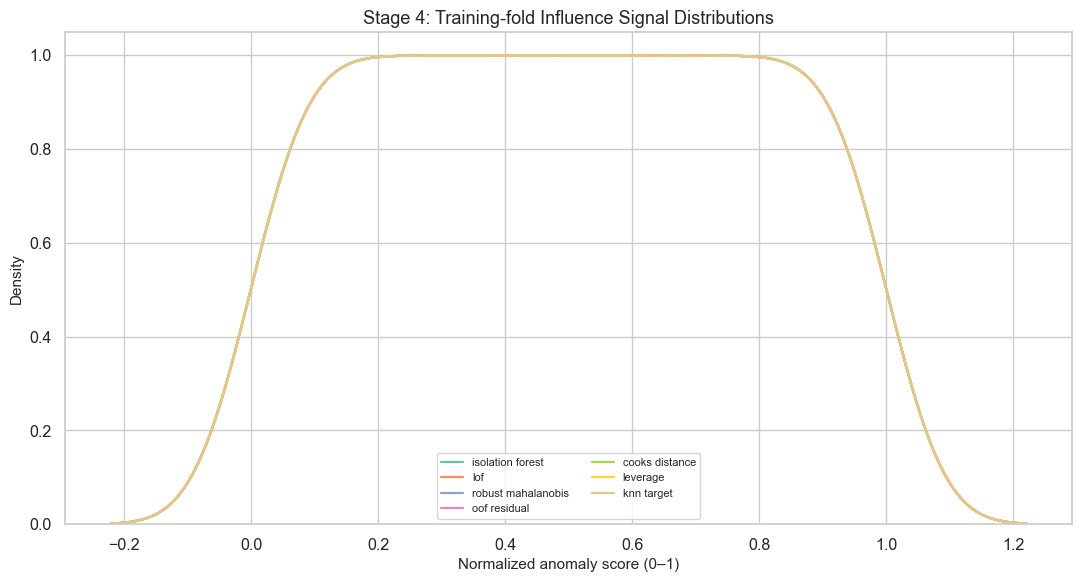

Saved figure: report_assets/figures/fig_04_02_signal_correlation.png


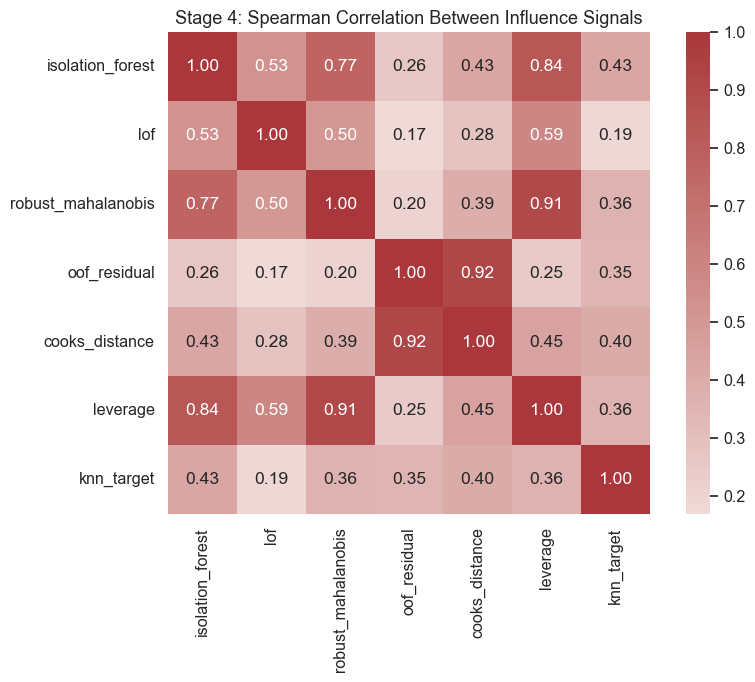

Saved figure: report_assets/figures/fig_04_03_top5_overlap.png


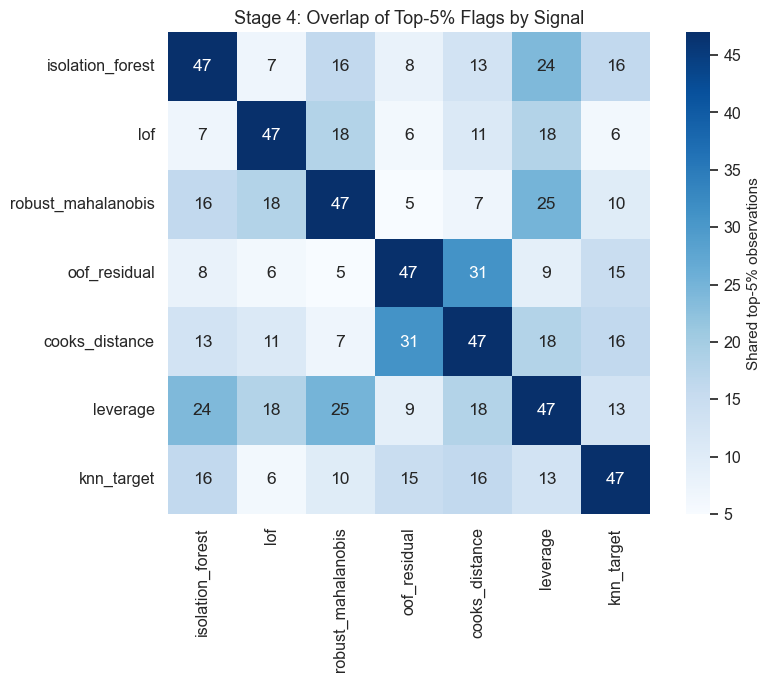

Saved figure: report_assets/figures/fig_04_04_known_candidates.png


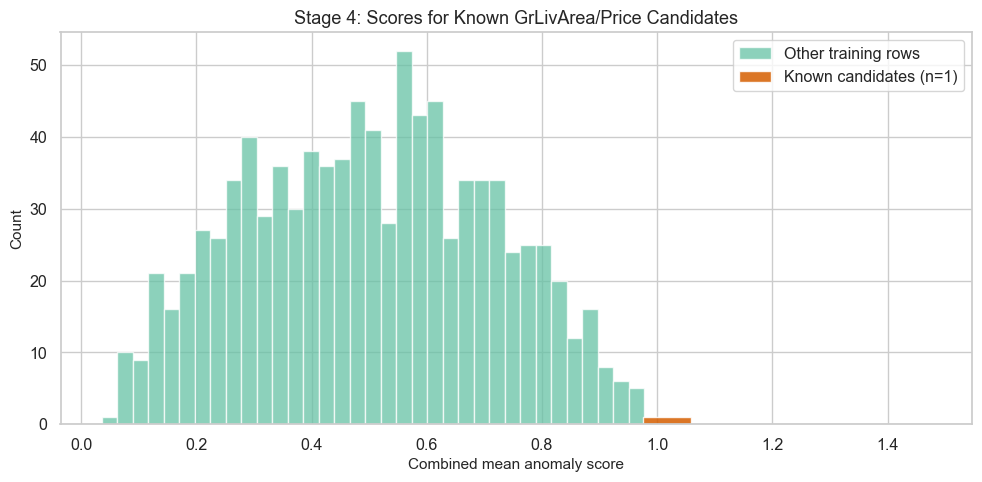

Known candidate observations in this training fold: 1


,GrLivArea,SalePrice,mean_score,mean_score_percentile
0,4676,184750.0,0.975,1.0


Saved table: report_assets/tables/table_04_02_known_candidate_scores.csv and report_assets/tables/table_04_02_known_candidate_scores.md
Saved figure: report_assets/figures/fig_04_05_bootstrap_stability.png


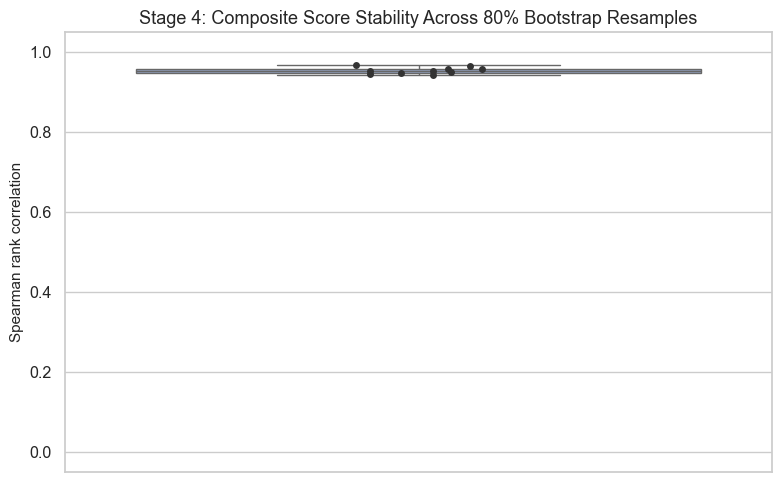

,bootstrap,spearman_rho
count,10.000,10.000
mean,5.500,0.954
std,3.028,0.008
min,1.000,0.943
25%,3.250,0.949
50%,5.500,0.953
75%,7.750,0.958
max,10.000,0.968


Saved table: report_assets/tables/table_04_03_bootstrap_stability.csv and report_assets/tables/table_04_03_bootstrap_stability.md


(WindowsPath('report_assets/tables/table_04_03_bootstrap_stability.csv'),
 WindowsPath('report_assets/tables/table_04_03_bootstrap_stability.md'))

In [27]:
# ── 4.1  Fit on one development training fold only ──────────────────
# Use a single CV training partition for diagnostics; future CV training
# calls must fit a fresh InfluenceScorer within each training fold.
_stage4_train_idx, _stage4_val_idx = next(CV.split(X_dev, y_dev))
X_score_train = X_dev.iloc[_stage4_train_idx].reset_index(drop=True)
y_score_train = y_dev.iloc[_stage4_train_idx].reset_index(drop=True)

stability_df, influence_scorer = bootstrap_score_stability(
    X_score_train, y_score_train, n_boot=10, sample_fraction=0.80, random_state=SEED
)
component_scores = influence_scorer.component_scores_.copy()
component_scores["mean"] = influence_scorer.combine("mean")
component_scores["max"] = influence_scorer.combine("max")
component_scores["rank_average"] = influence_scorer.combine("rank_average")

print(f"Scored training observations: {len(X_score_train):,}")
print(f"Numeric features used       : {len(influence_scorer.numeric_features_)}")
print(f"Robust covariance method   : {influence_scorer.mahalanobis_method_}")
print("Score direction             : higher = more anomalous / influential")

# Compact descriptive table, saved for report use.
score_summary = component_scores.describe(percentiles=[.5, .9, .95, .99]).T[["mean", "50%", "90%", "95%", "99%", "max"]].reset_index(names="signal")
display(score_summary.round(3))
save_table(score_summary.round(5), "table_04_01_score_summary")

# Distribution of component signals and combined scores.
fig, ax = plt.subplots(figsize=(11, 6))
for col in influence_scorer.component_scores_.columns:
    sns.kdeplot(influence_scorer.component_scores_[col], ax=ax, label=col.replace("_", " "), linewidth=1.6)
ax.set(xlabel="Normalized anomaly score (0–1)", ylabel="Density", title="Stage 4: Training-fold Influence Signal Distributions")
ax.legend(ncol=2, fontsize=8)
save_fig("fig_04_01_score_distributions.png")
plt.show()

# Pairwise signal correlation.
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(influence_scorer.component_scores_.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Stage 4: Spearman Correlation Between Influence Signals")
save_fig("fig_04_02_signal_correlation.png")
plt.show()

# Top 5% overlap heatmap among individual signals.
flagged = influence_scorer.component_scores_.ge(influence_scorer.component_scores_.quantile(0.95))
overlap = pd.DataFrame(index=flagged.columns, columns=flagged.columns, dtype=float)
for a in flagged.columns:
    for b in flagged.columns:
        overlap.loc[a, b] = (flagged[a] & flagged[b]).sum()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(overlap, annot=True, fmt=".0f", cmap="Blues", square=True, ax=ax, cbar_kws={"label": "Shared top-5% observations"})
ax.set_title("Stage 4: Overlap of Top-5% Flags by Signal")
save_fig("fig_04_03_top5_overlap.png")
plt.show()

# Locate known visual candidates using only this training partition.
if "GrLivArea" in X_score_train.columns:
    cand_mask = (X_score_train["GrLivArea"] > 4000) & (np.expm1(y_score_train) < 300_000)
else:
    cand_mask = pd.Series(False, index=X_score_train.index)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(component_scores["mean"], bins=35, alpha=.75, color=sns.color_palette(PALETTE)[0], edgecolor="white", label="Other training rows")
if cand_mask.any():
    ax.hist(component_scores.loc[cand_mask, "mean"], bins=12, alpha=.85, color="#D55E00", edgecolor="white", label=f"Known candidates (n={cand_mask.sum()})")
ax.set(xlabel="Combined mean anomaly score", ylabel="Count", title="Stage 4: Scores for Known GrLivArea/Price Candidates")
ax.legend()
save_fig("fig_04_04_known_candidates.png")
plt.show()
print(f"Known candidate observations in this training fold: {int(cand_mask.sum())}")
if cand_mask.any():
    candidate_score_table = pd.DataFrame({"GrLivArea": X_score_train.loc[cand_mask, "GrLivArea"].values,
       "SalePrice": np.expm1(y_score_train.loc[cand_mask].values),
       "mean_score": component_scores.loc[cand_mask, "mean"].values,
       "mean_score_percentile": component_scores.loc[cand_mask, "mean"].rank(pct=True).values})
    display(candidate_score_table.round(3))
    save_table(candidate_score_table.round(5), "table_04_02_known_candidate_scores")

# Stability across independent subsamples of this same training fold.
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=stability_df, y="spearman_rho", color=sns.color_palette(PALETTE)[2], ax=ax)
sns.stripplot(data=stability_df, y="spearman_rho", color="#333333", size=5, ax=ax)
ax.set(ylabel="Spearman rank correlation", title="Stage 4: Composite Score Stability Across 80% Bootstrap Resamples", ylim=(-0.05, 1.05))
save_fig("fig_04_05_bootstrap_stability.png")
plt.show()
display(stability_df.describe().round(3))
save_table(stability_df.round(5), "table_04_03_bootstrap_stability")

### Stage 4 — Observations & Inferences

- **The individual score distributions are identical by construction.** Each raw signal is converted to an empirical percentile rank on [0, 1], so the overlapping density curves and identical component summary quantiles do not mean the methods produce identical anomaly measurements. The rank transformation makes their scales comparable; interpret their dependence and flagged-row overlap instead.
- **The signals capture related but distinct patterns.** Isolation Forest, robust Mahalanobis distance, and leverage are strongly associated (Spearman ρ = 0.77–0.91), consistent with these diagnostics responding to unusual feature-space positions. OOF residual magnitude and Cook's distance are also strongly associated (ρ = 0.92), as both reflect model discrepancy, with Cook's distance additionally incorporating leverage. In contrast, OOF residuals have only weak associations with the feature-space signals (ρ = 0.17–0.26). kNN target inconsistency shows modest associations across the methods (ρ = 0.19–0.43), adding a partly distinct local target signal.
- **Top-5% agreement is meaningful but incomplete.** Each individual signal flags 47 observations. OOF residuals and Cook's distance share 31 flagged rows, while pairs across different signal families generally share substantially fewer (for example, OOF residuals and robust Mahalanobis share 5; LOF and kNN target inconsistency share 6). This supports combining complementary diagnostics rather than treating one detector as a definitive outlier label.
- **The known large-area/low-price candidate is ranked as highly unusual.** The one candidate in this training fold (GrLivArea = 4,676 sq ft; SalePrice = $184,750) has a combined mean score of 0.975 and is at the 100th percentile of this fold's combined-score ranking. This is consistent with the visual flag, but one case cannot establish that the observation is erroneous or that down-weighting it will help prediction.
- **The composite ranking is stable across the sampled bootstrap runs.** Across 10 resamples, the composite-score Spearman correlation with the full training-fold ranking averages 0.954 (SD = 0.008; range = 0.943–0.968). That indicates relatively stable ordering for this fold and this scoring setup; it does not establish stability across all CV folds or prove predictive benefit.

**Implication for Stage 5:** The different signals appear complementary, the flagged candidate is strongly prioritized, and the composite ranking is stable in this diagnostic fold. It is therefore reasonable to test reliability weights derived from these scores. Whether weighting improves accuracy or robustness must be determined by the paired development-set CV comparisons in later stages; Stage 4 alone does not answer the research question.


---
## Stage 5 — Reliability Weights

**Goal:** Convert training-fold influence scores into soft reliability weights and inspect how each mapping treats unusual observations. Also establish an iterative residual-reweighting option for later model comparisons.

**Method:** Map the Stage 4 composite anomaly score to [w_min, 1] using linear decay, exponential decay, and a descending sigmoid. Separately derive Huber and Tukey weights from standardized residuals. Demonstrate IRLS on the current training fold only: fit, recompute residual weights from training residuals, refit for up to T iterations, and record convergence. These are diagnostics; no validation or test row is weighted or filtered here.


Saved figure: report_assets/figures/fig_05_01_weight_mappings.png


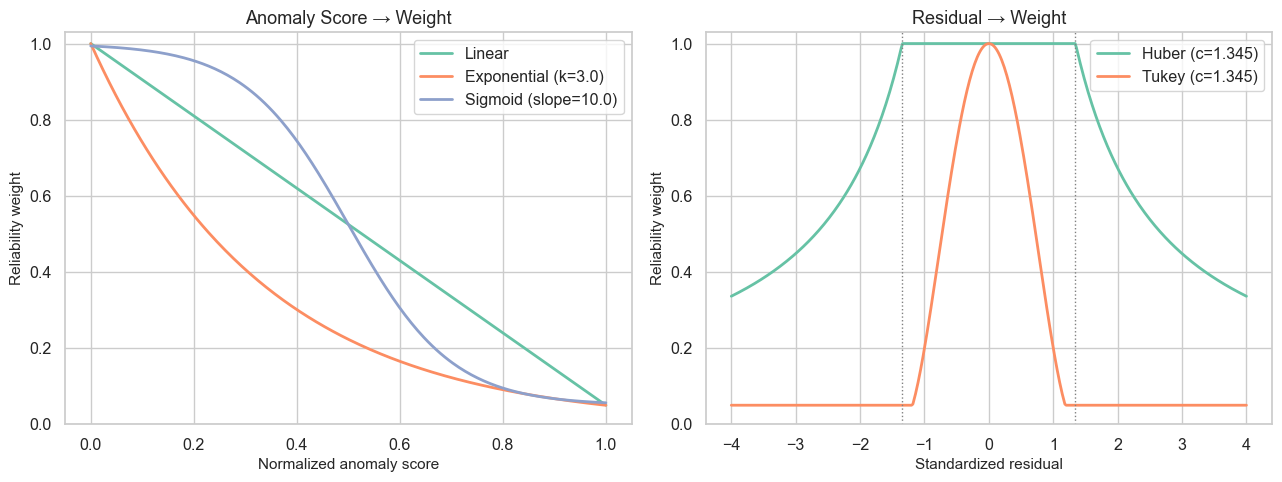

Saved figure: report_assets/figures/fig_05_02_weight_distributions.png


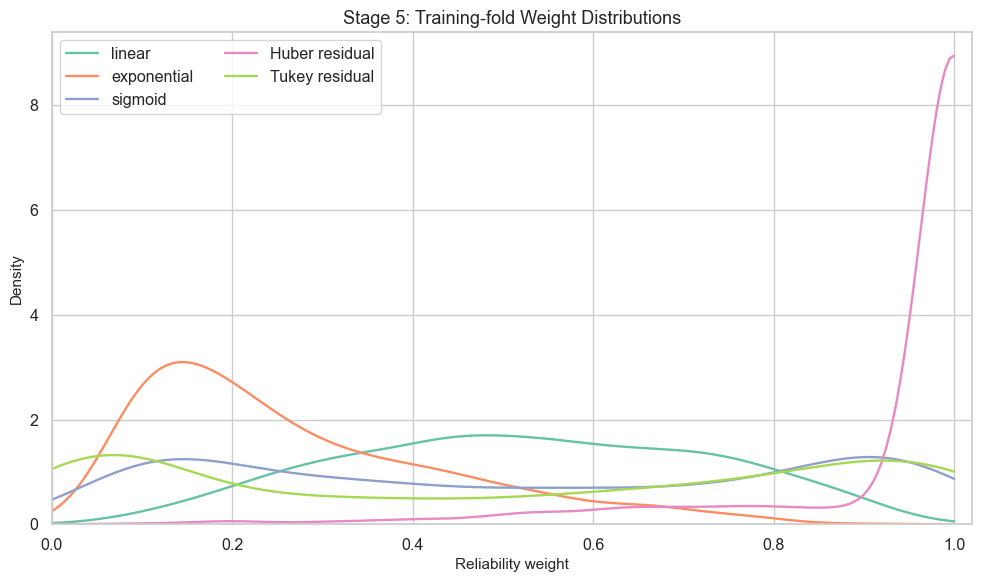

,method,mean,5%,25%,50%,75%,95%,min,max
0,linear,0.525,0.200,0.371,0.526,0.685,0.853,0.071,0.966
1,exponential,0.271,0.080,0.137,0.224,0.370,0.628,0.053,0.897
2,sigmoid,0.525,0.080,0.207,0.528,0.851,0.971,0.058,0.991
3,Huber residual,0.944,0.602,1.000,1.000,1.000,1.000,0.092,1.000
4,Tukey residual,0.512,0.050,0.060,0.560,0.873,0.997,0.050,1.000


Saved table: report_assets/tables/table_05_01_weight_summary.csv and report_assets/tables/table_05_01_weight_summary.md
Saved figure: report_assets/figures/fig_05_03_weight_vs_saleprice.png


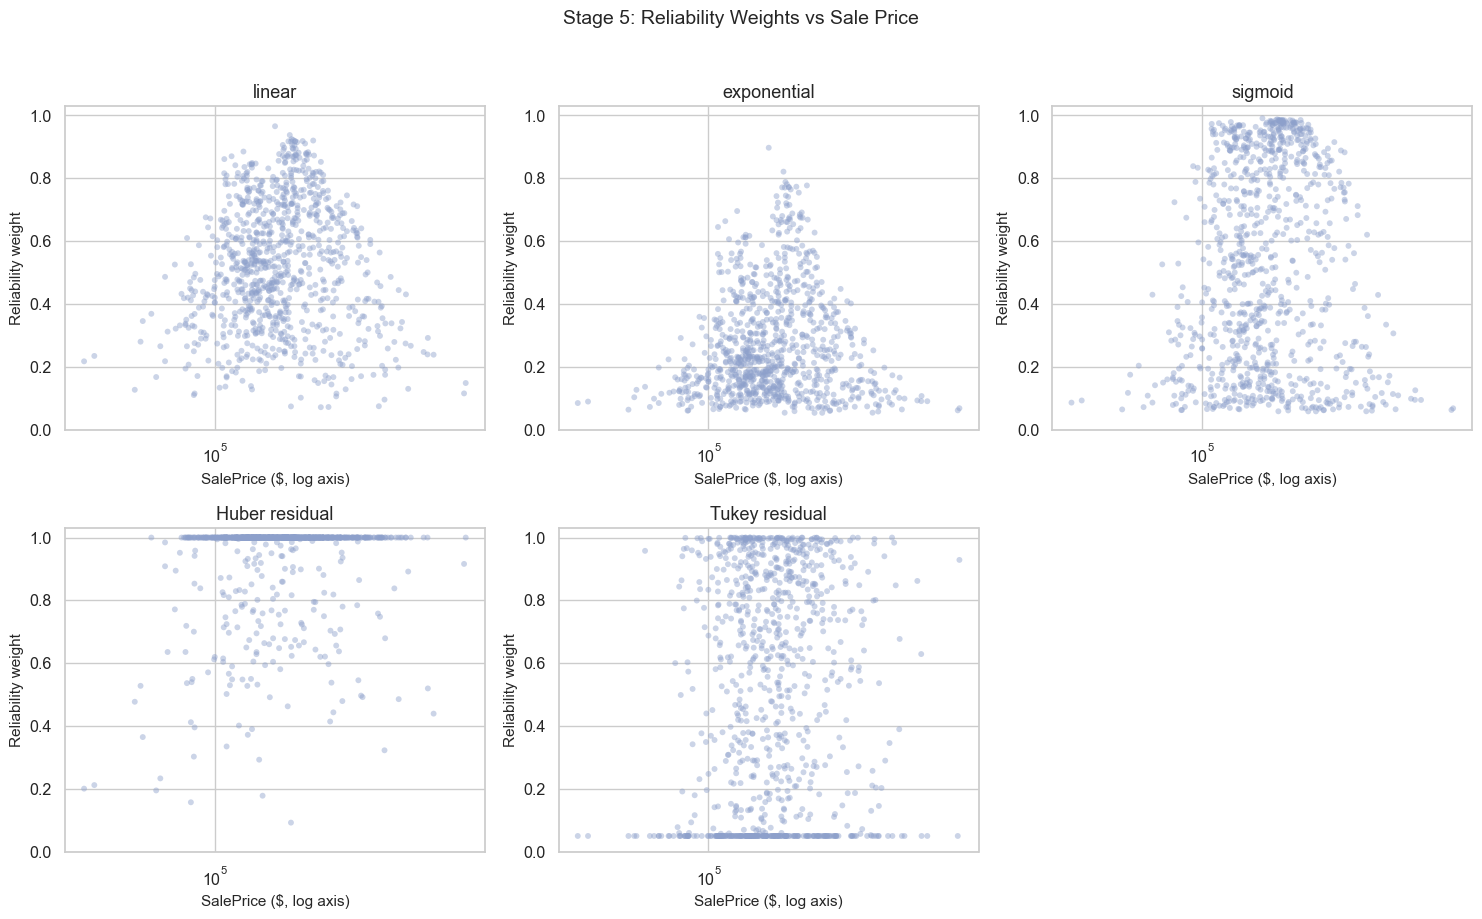

IRLS iterations completed: 10 / 10; final max weight change = 0.004989


,iteration,max_weight_change,mean_weight,min_weight,mad_scale
0,1,0.90754,0.94438,0.09246,0.07822
1,2,0.38214,0.93418,0.05906,0.07102
2,3,0.18552,0.93213,0.05598,0.07028
3,4,0.08894,0.93251,0.05570,0.07057
4,5,0.04972,0.93292,0.05573,0.07080
5,6,0.02433,0.93245,0.05545,0.07053
6,7,0.01271,0.93194,0.05520,0.07027
7,8,0.00758,0.93160,0.05504,0.07011
8,9,0.00600,0.93118,0.05487,0.06990
9,10,0.00499,0.93078,0.05470,0.06971


Saved table: report_assets/tables/table_05_02_irls_convergence.csv and report_assets/tables/table_05_02_irls_convergence.md
Saved figure: report_assets/figures/fig_05_04_irls_convergence.png


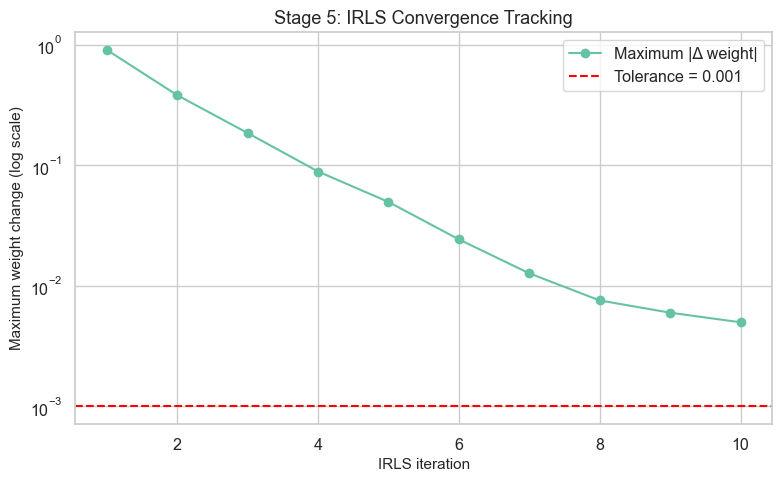

,method,mean,std,min,max,fraction_at_floor
0,IRLS-Huber,0.9308,0.1682,0.0547,1.0,0.0


Saved table: report_assets/tables/table_05_03_irls_weight_summary.csv and report_assets/tables/table_05_03_irls_weight_summary.md


(WindowsPath('report_assets/tables/table_05_03_irls_weight_summary.csv'),
 WindowsPath('report_assets/tables/table_05_03_irls_weight_summary.md'))

In [28]:
# ── 5.1  Construct score-based and residual-based weights ────────────
# Clear parameters for the mappings and IRLS loop.
W_MIN = 0.05
EXP_DECAY_K = 3.0
SIGMOID_SLOPE = 10.0
ROBUST_THRESHOLD = 1.345
IRLS_T = 10
IRLS_TOL = 1e-3

composite_score = influence_scorer.combine("mean").to_numpy()
weight_methods = {
    "linear": scores_to_weights(composite_score, "linear", w_min=W_MIN),
    "exponential": scores_to_weights(composite_score, "exponential", w_min=W_MIN, k=EXP_DECAY_K),
    "sigmoid": scores_to_weights(composite_score, "sigmoid", w_min=W_MIN, sigmoid_slope=SIGMOID_SLOPE),
}

# For residual-based methods, get initial in-sample residuals from the baseline
# model fitted only to this Stage 4/5 training fold, then standardize by MAD.
resid_reference_model = clone(ridge_model).fit(X_score_train, y_score_train)
resid_reference = y_score_train.to_numpy() - resid_reference_model.predict(X_score_train)
resid_center = np.median(resid_reference)
resid_scale = max(1.4826 * np.median(np.abs(resid_reference - resid_center)), 1e-9)
standardized_residual = (resid_reference - resid_center) / resid_scale
weight_methods["Huber residual"] = scores_to_weights(
    standardized_residual, "huber_residual", w_min=W_MIN, threshold=ROBUST_THRESHOLD
)
weight_methods["Tukey residual"] = scores_to_weights(
    standardized_residual, "tukey_residual", w_min=W_MIN, threshold=ROBUST_THRESHOLD
)

# Mapping curves: show the three anomaly-score mappings and both residual rules.
score_grid = np.linspace(0, 1, 250)
resid_grid = np.linspace(-4, 4, 401)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(score_grid, scores_to_weights(score_grid, "linear", w_min=W_MIN), label="Linear", lw=2)
axes[0].plot(score_grid, scores_to_weights(score_grid, "exponential", w_min=W_MIN, k=EXP_DECAY_K), label=f"Exponential (k={EXP_DECAY_K})", lw=2)
axes[0].plot(score_grid, scores_to_weights(score_grid, "sigmoid", w_min=W_MIN, sigmoid_slope=SIGMOID_SLOPE), label=f"Sigmoid (slope={SIGMOID_SLOPE})", lw=2)
axes[0].set(xlabel="Normalized anomaly score", ylabel="Reliability weight", title="Anomaly Score → Weight", ylim=(0, 1.03))
axes[0].legend()
axes[1].plot(resid_grid, scores_to_weights(resid_grid, "huber_residual", w_min=W_MIN, threshold=ROBUST_THRESHOLD), label=f"Huber (c={ROBUST_THRESHOLD})", lw=2)
axes[1].plot(resid_grid, scores_to_weights(resid_grid, "tukey_residual", w_min=W_MIN, threshold=ROBUST_THRESHOLD), label=f"Tukey (c={ROBUST_THRESHOLD})", lw=2)
axes[1].axvline(-ROBUST_THRESHOLD, color="grey", ls=":", lw=1)
axes[1].axvline(ROBUST_THRESHOLD, color="grey", ls=":", lw=1)
axes[1].set(xlabel="Standardized residual", ylabel="Reliability weight", title="Residual → Weight", ylim=(0, 1.03))
axes[1].legend()
save_fig("fig_05_01_weight_mappings.png")
plt.show()

# Weight distributions by method.
weight_long = pd.DataFrame({name: values for name, values in weight_methods.items()})
fig, ax = plt.subplots(figsize=(10, 6))
for name in weight_long.columns:
    sns.kdeplot(weight_long[name], ax=ax, label=name, linewidth=1.7, clip=(0, 1))
ax.set(xlabel="Reliability weight", ylabel="Density", title="Stage 5: Training-fold Weight Distributions", xlim=(0, 1.02))
ax.legend(ncol=2)
save_fig("fig_05_02_weight_distributions.png")
plt.show()

weight_summary = weight_long.describe(percentiles=[.05, .25, .5, .75, .95]).T[["mean", "5%", "25%", "50%", "75%", "95%", "min", "max"]].reset_index(names="method")
display(weight_summary.round(3))
save_table(weight_summary.round(5), "table_05_01_weight_summary")

# Weight vs sale price, with price returned to dollars for interpretation.
price_train = np.expm1(y_score_train.to_numpy())
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, values) in zip(axes.flat, weight_methods.items()):
    ax.scatter(price_train, values, alpha=.45, s=18, color=sns.color_palette(PALETTE)[2], edgecolors="none")
    ax.set_xscale("log")
    ax.set(xlabel="SalePrice ($, log axis)", ylabel="Reliability weight", title=name, ylim=(0, 1.03))
for ax in axes.flat[len(weight_methods):]:
    ax.set_visible(False)
fig.suptitle("Stage 5: Reliability Weights vs Sale Price", y=1.02, fontsize=14)
save_fig("fig_05_03_weight_vs_saleprice.png")
plt.show()

# IRLS-style residual reweighting. This is a training diagnostic, not an evaluation.
irls_model, irls_weights, irls_history = irls_reweight(
    ridge_model, X_score_train, y_score_train, loss="huber",
    threshold=ROBUST_THRESHOLD, w_min=W_MIN, T=IRLS_T, tol=IRLS_TOL, random_state=SEED
)
print(f"IRLS iterations completed: {len(irls_history)} / {IRLS_T}; final max weight change = {irls_history['max_weight_change'].iloc[-1]:.6f}")
display(irls_history.round(5))
save_table(irls_history.round(6), "table_05_02_irls_convergence")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(irls_history["iteration"], irls_history["max_weight_change"], marker="o", label="Maximum |Δ weight|")
ax.axhline(IRLS_TOL, color="red", ls="--", label=f"Tolerance = {IRLS_TOL:g}")
ax.set(yscale="log", xlabel="IRLS iteration", ylabel="Maximum weight change (log scale)", title="Stage 5: IRLS Convergence Tracking")
ax.legend()
save_fig("fig_05_04_irls_convergence.png")
plt.show()

irls_weight_summary = pd.DataFrame([{"method": "IRLS-Huber", "mean": irls_weights.mean(), "std": irls_weights.std(),
                                     "min": irls_weights.min(), "max": irls_weights.max(),
                                     "fraction_at_floor": np.mean(irls_weights <= W_MIN + 1e-12)}])
display(irls_weight_summary.round(4))
save_table(irls_weight_summary.round(6), "table_05_03_irls_weight_summary")

### Stage 5 — Observations & Inferences

- **The anomaly-score mappings offer different degrees of down-weighting.** With `w_min = 0.05` and `k = 3`, exponential decay is the most aggressive over much of the score range. Linear decay reduces weights steadily, while the sigmoid retains weights near 1 for many lower-to-middle scores and drops more sharply around the middle of the score range. This gives the later comparisons meaningfully different weighting strengths to test.
- **The Huber and Tukey residual rules behave differently.** Huber assigns weight 1 to most standardized residuals within its threshold, then decreases weights gradually for larger residuals; its training-fold mean weight is 0.944. Tukey decreases weights more sharply outside the threshold and reaches the 0.05 floor for some observations; its mean is 0.512. In this run the Huber weights have a minimum of 0.092, while Tukey reaches the configured floor. Neither rule fully removes observations.
- **Weights do not show a simple relationship with sale price.** The score-based and residual-based scatterplots show a broad spread of weights across the observed price range. This suggests these schemes are responding to the multivariate anomaly score or model residual, rather than simply assigning lower reliability to expensive homes. Price alone is not a sufficient explanation of the assigned weights.
- **IRLS updates decrease consistently but did not meet the stopping tolerance within the iteration budget.** The maximum weight change falls from 0.908 in iteration 1 to 0.00499 in iteration 10, with the mean weight settling near 0.931. Since the final change remains above the configured tolerance of 0.001, the loop stopped at its maximum of 10 iterations rather than satisfying the convergence criterion. The smallest final weight is 0.0547, just above the 0.05 floor.

**Implication for Stage 6:** The mappings create distinctly different weight distributions, and the residual-based Huber and Tukey methods range from conservative to aggressive. The IRLS sequence is moving toward stable weights but would need more iterations or a less strict tolerance to meet the current convergence rule. These diagnostics describe weight behavior only; the next stage must test whether applying the weights improves held-out fold predictions under the same CV protocol.


---
## Stage 6 — Weighted Training and Robust-Loss Comparisons

**Goal:** Compare reliability-weighted Ridge, Random Forest, and gradient boosting against robust-loss alternatives using repeated 5×3 CV on the development set.

**Method and leakage controls:** In every outer CV fold, carve a 15% inner validation partition from the outer training rows. Fit `InfluenceScorer` only on the inner-training rows to tune weighted methods; derive candidate weights only for those rows. Select from exactly four configurations per method using inner-validation MAE. Validation rows are predicted with no filtering or reweighting. Refit the selected setting on the full outer training fold, recomputing the scorer and weights from that fold alone, then evaluate once on the untouched outer validation fold. The hold-out test set is not accessed. Boosting candidates use an inner-validation MAE early-stopping rule with patience 15 and a stated estimator ceiling. Robust comparisons include HuberRegressor, sklearn gradient boosting with Huber loss, and gradient boosting with median quantile loss.


In [29]:
# ── 6.1  Nested tuning and outer-fold evaluation ────────────────────
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, HuberRegressor

INNER_VAL_FRACTION = 0.15
BOOST_PATIENCE = 15
BOOST_METRIC = "mae"
TUNING_BUDGET = 4

# Every method has four candidates. Weighted methods vary anomaly-score
# aggregation, exponential decay k, and w_min. Boosted families additionally
# vary learning rate and the maximum estimator count.
WEIGHT_CONFIGS = [
    {"scorer_type": "mean", "k": 1.0, "w_min": 0.05},
    {"scorer_type": "mean", "k": 3.0, "w_min": 0.10},
    {"scorer_type": "max", "k": 1.0, "w_min": 0.10},
    {"scorer_type": "rank_average", "k": 3.0, "w_min": 0.05},
]
BOOST_CONFIGS = [
    {"learning_rate": 0.03, "n_estimators_ceiling": 100},
    {"learning_rate": 0.05, "n_estimators_ceiling": 100},
    {"learning_rate": 0.03, "n_estimators_ceiling": 200},
    {"learning_rate": 0.05, "n_estimators_ceiling": 200},
]
HUBER_EPSILON_CONFIGS = [1.20, 1.35, 1.50, 1.75]
assert len(WEIGHT_CONFIGS) == len(BOOST_CONFIGS) == len(HUBER_EPSILON_CONFIGS) == TUNING_BUDGET


def _pipeline_with_estimator(estimator):
    return Pipeline([("prep", clone(preprocessor)), ("model", estimator)])


def _fit_pipeline_weighted(pipe, X_fit, y_fit, weights=None):
    kwargs = {}
    if weights is not None:
        kwargs["model__sample_weight"] = np.asarray(weights)
    pipe.fit(X_fit, y_fit, **kwargs)
    return pipe


def _fit_boosting_inner(estimator, X_fit, y_fit, X_inner_val, y_inner_val,
                        weights=None, patience=BOOST_PATIENCE):
    """Fit through a ceiling, select iteration by inner-validation MAE, stop after patience."""
    pipe = _pipeline_with_estimator(estimator)
    _fit_pipeline_weighted(pipe, X_fit, y_fit, weights)
    best_iter, best_mae, stale = 1, np.inf, 0
    best_pred = None
    for iteration, pred in enumerate(pipe.named_steps["model"].staged_predict(
            pipe.named_steps["prep"].transform(X_inner_val)), start=1):
        score = mean_absolute_error(y_inner_val, pred)
        if score < best_mae - 1e-12:
            best_iter, best_mae, stale = iteration, score, 0
            best_pred = np.asarray(pred)
        else:
            stale += 1
            if stale >= patience:
                break
    return best_iter, best_mae, best_pred


def _weighted_model_factory(family, seed, config):
    if family == "Weighted Ridge":
        return _pipeline_with_estimator(Ridge(alpha=10.0, random_state=seed))
    if family == "Weighted Random Forest":
        return _pipeline_with_estimator(RandomForestRegressor(
            n_estimators=200, max_features="sqrt", min_samples_leaf=2,
            random_state=seed, n_jobs=-1))
    if family == "Weighted Gradient Boosting":
        return GradientBoostingRegressor(loss="squared_error",
            learning_rate=config["learning_rate"], n_estimators=config["n_estimators_ceiling"],
            max_depth=2, min_samples_leaf=3, random_state=seed)
    raise ValueError(f"Unknown weighted family: {family}")


def _robust_model_factory(family, seed, config):
    if family == "HuberRegressor":
        return _pipeline_with_estimator(HuberRegressor(epsilon=config["epsilon"], alpha=0.0001,
                                                       max_iter=300, tol=1e-5))
    loss = "huber" if family == "Gradient Boosting (Huber loss)" else "quantile"
    kwargs = {"alpha": 0.5} if loss == "quantile" else {}
    return GradientBoostingRegressor(loss=loss, learning_rate=config["learning_rate"],
        n_estimators=config["n_estimators_ceiling"], max_depth=2,
        min_samples_leaf=3, random_state=seed, **kwargs)


def _fit_score_config(family, config, X_fit, y_fit, X_inner_val, y_inner_val,
                      scorer=None, weights=None, seed=SEED):
    """Fit one tuning candidate; all selection predictions are inner-validation only."""
    is_weighted = family.startswith("Weighted ")
    is_boost = "Gradient Boosting" in family
    if is_weighted:
        if scorer is None:
            raise ValueError("Weighted candidates require an InfluenceScorer fit on inner-training rows.")
        score = scorer.combine(config["scorer_type"]).to_numpy()
        weights = scores_to_weights(score, "exponential", w_min=config["w_min"], k=config["k"])
        estimator = _weighted_model_factory(family, seed, config)
    else:
        estimator = _robust_model_factory(family, seed, config)

    if is_boost:
        # Explicit inner validation controls early stopping; it is never used to
        # calculate scorer signals or training weights.
        best_iter, best_mae, best_pred = _fit_boosting_inner(
            estimator, X_fit, y_fit, X_inner_val, y_inner_val, weights=weights,
            patience=BOOST_PATIENCE)
        return best_mae, best_iter

    if not hasattr(estimator, "named_steps"):
        estimator = _pipeline_with_estimator(estimator)
    _fit_pipeline_weighted(estimator, X_fit, y_fit, weights)
    pred = estimator.predict(X_inner_val)
    return mean_absolute_error(y_inner_val, pred), None


def _fit_selected_outer(family, config, best_iter, X_outer_train, y_outer_train,
                        seed=SEED):
    """Refit selected setting on full outer training fold; return fitted model and weights."""
    is_weighted = family.startswith("Weighted ")
    scorer = None
    weights = None
    if is_weighted:
        scorer = InfluenceScorer(random_state=seed).fit(X_outer_train, y_outer_train)
        scores = scorer.combine(config["scorer_type"]).to_numpy()
        weights = scores_to_weights(scores, "exponential", w_min=config["w_min"], k=config["k"])

    if "Gradient Boosting" in family:
        if is_weighted:
            estimator = GradientBoostingRegressor(loss="squared_error",
                learning_rate=config["learning_rate"], n_estimators=max(1, best_iter),
                max_depth=2, min_samples_leaf=3, random_state=seed)
        else:
            estimator = _robust_model_factory(family, seed, config)
            estimator.set_params(n_estimators=max(1, best_iter))
        pipe = _pipeline_with_estimator(estimator)
        _fit_pipeline_weighted(pipe, X_outer_train, y_outer_train, weights)
        return pipe, weights

    if family == "Weighted Ridge":
        model = _weighted_model_factory(family, seed, config)
    elif family == "Weighted Random Forest":
        model = _weighted_model_factory(family, seed, config)
    else:
        model = _robust_model_factory(family, seed, config)
    _fit_pipeline_weighted(model, X_outer_train, y_outer_train, weights)
    return model, weights


STAGE6_FAMILIES = [
    "Weighted Ridge", "Weighted Random Forest", "Weighted Gradient Boosting",
    "HuberRegressor", "Gradient Boosting (Huber loss)",
    "Gradient Boosting (Median quantile)",
]


def evaluate_stage6_family(family, X, y, cv=CV):
    """Nested four-candidate selection and repeated outer CV for one family."""
    records = []
    for fold, (outer_train_idx, outer_val_idx) in enumerate(cv.split(X, y), start=1):
        X_outer, y_outer = X.iloc[outer_train_idx], y.iloc[outer_train_idx]
        X_outer_val, y_outer_val = X.iloc[outer_val_idx], y.iloc[outer_val_idx]
        inner_fit_idx, inner_val_idx = train_test_split(
            np.arange(len(X_outer)), test_size=INNER_VAL_FRACTION,
            random_state=SEED + fold, shuffle=True)
        X_inner, y_inner = X_outer.iloc[inner_fit_idx], y_outer.iloc[inner_fit_idx]
        X_inner_val, y_inner_val = X_outer.iloc[inner_val_idx], y_outer.iloc[inner_val_idx]

        # Fit one scorer strictly to inner-training data, reused across the four
        # weighted candidates. No inner-validation outcomes enter the scores.
        inner_scorer = None
        if family.startswith("Weighted "):
            inner_scorer = InfluenceScorer(random_state=SEED + fold).fit(X_inner, y_inner)

        configs = WEIGHT_CONFIGS if family.startswith("Weighted ") else (
            HUBER_EPSILON_CONFIGS if family == "HuberRegressor" else BOOST_CONFIGS)
        candidate_results = []
        for candidate_id, candidate in enumerate(configs, start=1):
            if family.startswith("Weighted "):
                config = {**candidate, **BOOST_CONFIGS[candidate_id - 1]} if family == "Weighted Gradient Boosting" else dict(candidate)
            elif family == "HuberRegressor":
                config = {"epsilon": candidate}
            else:
                config = dict(candidate)
            val_mae, best_iter = _fit_score_config(
                family, config, X_inner, y_inner, X_inner_val, y_inner_val,
                scorer=inner_scorer, seed=SEED + fold + candidate_id)
            candidate_results.append({"candidate": candidate_id, "config": config,
                                      "inner_MAE": val_mae, "best_iter": best_iter})

        best = min(candidate_results, key=lambda row: row["inner_MAE"])
        fitted, outer_weights = _fit_selected_outer(
            family, best["config"], best["best_iter"], X_outer, y_outer, seed=SEED + fold)
        outer_pred = fitted.predict(X_outer_val)
        metrics = regression_metrics(y_outer_val.to_numpy(), outer_pred)
        metrics.update({"fold": fold, "model": family,
                        "selected_candidate": best["candidate"],
                        "inner_MAE": best["inner_MAE"],
                        "best_iteration": best["best_iter"] if best["best_iter"] is not None else np.nan,
                        "config": str(best["config"]),
                        "mean_train_weight": float(np.mean(outer_weights)) if outer_weights is not None else 1.0})
        records.append(metrics)
        print(f"{family}: fold {fold:02d}/{cv.get_n_splits()} | inner MAE={best['inner_MAE']:.4f} | outer RMSE={metrics['RMSE_log']:.4f}")

    fold_df = pd.DataFrame(records)
    CV_PER_FOLD_SCORES[family] = fold_df
    summary = {"model": family, "n_folds": len(fold_df)}
    for metric in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log", "R2", "RMSE_$", "MAE_$"]:
        summary[metric] = fold_df[metric].mean()
        summary[f"{metric}_std"] = fold_df[metric].std()
    summary["inner_MAE_mean"] = fold_df["inner_MAE"].mean()
    return summary, fold_df


stage6_results, stage6_fold_tables = [], {}
for family in STAGE6_FAMILIES:
    print(f"\nNested repeated-CV evaluation: {family} (4 configurations per outer fold)")
    summary, folds = evaluate_stage6_family(family, X_dev, y_dev, cv=CV)
    stage6_results.append(summary)
    stage6_fold_tables[family] = folds

stage6_summary_df = pd.DataFrame(stage6_results).sort_values("RMSE_log").reset_index(drop=True)
display(stage6_summary_df.round(5))
save_table(stage6_summary_df.round(6), "table_06_01_weighted_robust_cv_summary")

# Save detailed fold-level metrics separately for paired comparisons.
stage6_all_folds = pd.concat(stage6_fold_tables.values(), ignore_index=True)
save_table(stage6_all_folds, "table_06_02_weighted_robust_cv_folds")



Nested repeated-CV evaluation: Weighted Ridge (4 configurations per outer fold)
Weighted Ridge: fold 01/15 | inner MAE=0.0885 | outer RMSE=0.1997
Weighted Ridge: fold 02/15 | inner MAE=0.0881 | outer RMSE=0.1199
Weighted Ridge: fold 03/15 | inner MAE=0.0932 | outer RMSE=0.1641
Weighted Ridge: fold 04/15 | inner MAE=0.0922 | outer RMSE=0.1148
Weighted Ridge: fold 05/15 | inner MAE=0.0803 | outer RMSE=0.1131
Weighted Ridge: fold 06/15 | inner MAE=0.1015 | outer RMSE=0.1056
Weighted Ridge: fold 07/15 | inner MAE=0.0921 | outer RMSE=0.1540
Weighted Ridge: fold 08/15 | inner MAE=0.0869 | outer RMSE=0.1981
Weighted Ridge: fold 09/15 | inner MAE=0.0921 | outer RMSE=0.1181
Weighted Ridge: fold 10/15 | inner MAE=0.0904 | outer RMSE=0.1457
Weighted Ridge: fold 11/15 | inner MAE=0.0956 | outer RMSE=0.2018
Weighted Ridge: fold 12/15 | inner MAE=0.0918 | outer RMSE=0.1194
Weighted Ridge: fold 13/15 | inner MAE=0.0885 | outer RMSE=0.1181
Weighted Ridge: fold 14/15 | inner MAE=0.0864 | outer RMSE=0.

,model,n_folds,RMSE_log,RMSE_log_std,MAE_log,MAE_log_std,MedAE_log,MedAE_log_std,P90_log,P90_log_std,R2,R2_std,RMSE_$,RMSE_$_std,MAE_$,MAE_$_std,inner_MAE_mean
0,Weighted Gradient Boosting,15,0.14268,0.01453,0.09550,0.00486,0.06623,0.00451,0.20470,0.01649,0.86917,0.02373,31739.00000,5400.02619,17594.93333,1253.69639,0.09618
1,Gradient Boosting (Huber loss),15,0.14346,0.01371,0.09654,0.00445,0.06870,0.00234,0.19956,0.01512,0.86785,0.02260,31739.06667,5599.15219,17740.66667,1117.05785,0.09588
2,Weighted Ridge,15,0.14416,0.03465,0.08786,0.00492,0.06171,0.00443,0.17778,0.01231,0.86109,0.06552,46001.66667,36460.80022,16828.60000,2659.14236,0.09022
3,Gradient Boosting (Median quantile),15,0.14882,0.01284,0.09970,0.00510,0.06910,0.00527,0.21651,0.01250,0.85801,0.02150,32442.53333,5604.86454,18294.13333,1212.74864,0.10207
4,Weighted Random Forest,15,0.15403,0.01277,0.10161,0.00603,0.06664,0.00414,0.23812,0.02068,0.84790,0.02205,34880.00000,5056.45576,18973.40000,1408.99877,0.10655
5,HuberRegressor,15,0.15528,0.03592,0.09188,0.00794,0.05943,0.00360,0.18679,0.01987,0.83928,0.07369,48536.46667,38619.45282,17406.13333,3608.66910,0.09765


Saved table: report_assets/tables/table_06_01_weighted_robust_cv_summary.csv and report_assets/tables/table_06_01_weighted_robust_cv_summary.md
Saved table: report_assets/tables/table_06_02_weighted_robust_cv_folds.csv and report_assets/tables/table_06_02_weighted_robust_cv_folds.md


(WindowsPath('report_assets/tables/table_06_02_weighted_robust_cv_folds.csv'),
 WindowsPath('report_assets/tables/table_06_02_weighted_robust_cv_folds.md'))

### Stage 6 — Observations & Inferences

- **Weighted Gradient Boosting had the lowest mean CV RMSE among the Stage 6 methods:** 0.14268 ± 0.01453, followed closely by gradient boosting with Huber loss at 0.14346 ± 0.01371. Weighted Ridge was third at 0.14416 ± 0.03465. These are development-set outer-fold results; the hold-out test set remains unused.
- **The weighting benefit depends on the base model and metric.** Weighted Ridge improved on the Stage 3 Ridge baseline in mean RMSE (0.14416 vs 0.1452) and MAE (0.08786 vs 0.0923), and reduced P90 error (0.17778 vs 0.1844). Its RMSE variability was higher, however (SD 0.03465 vs 0.0291), so the mean gain was not consistent across folds. Weighted Gradient Boosting did not outperform the Stage 3 HistGBDT baseline RMSE (0.14268 vs 0.1409), though its average MAE was also slightly higher (0.09550 vs 0.0928).
- **Robust-loss comparisons were mixed.** Gradient Boosting with Huber loss performed competitively on RMSE, while median quantile boosting (0.14882 ± 0.01284) and HuberRegressor (0.15528 ± 0.03592) had higher mean RMSE. HuberRegressor had relatively low median absolute error (0.05943), but its fold-to-fold RMSE variability was substantial.
- **Random Forest was the weakest Stage 6 method on the reported mean metrics.** Weighted Random Forest had mean RMSE 0.15403 and P90 error 0.23812, suggesting its tail errors remain comparatively large under this setup.
- **Selection used only the inner training/validation split.** Each method evaluated four configurations per outer fold; its inner MAE guided selection, while the outer validation fold was reserved for final fold scoring. These results therefore compare the tuned methods on development CV, but they do not establish a final test-set improvement or statistical significance. Repeated-CV folds are also dependent, so the reported standard deviations describe fold variation rather than confidence intervals.

**Implication for later stages:** The results provide a modest signal that weighting may help Ridge's average errors, but not a consistent improvement across model families. Weighted gradient boosting remains competitive, yet it does not exceed the strongest Stage 3 baseline on mean RMSE. Continue with paired fold-level comparisons and robustness experiments, then make the final judgment only after the planned one-time hold-out evaluation.


---
## Stage 7 — Paired Strategy Comparison and Final Test Evaluation

**Goal:** Compare no handling, hard removal, winsorizing, robust losses, reliability weighting, and IRLS on matched development CV folds; then make the one-time final evaluation on the locked hold-out test set.

**Method:** Use the no-handling Ridge model as the paired reference and compare fold-wise RMSE differences with two-sided Wilcoxon signed-rank tests. Report paired mean differences and rank-biserial effect sizes with bootstrap confidence intervals; apply Holm correction across the strategy comparisons. Rank strategies by mean CV RMSE and show fold-to-fold standard-deviation error bars. Freeze configurations using only development data and inner-validation records. Only after the CV comparison and freeze table are complete, evaluate each frozen strategy once on the hold-out set with 1,000 bootstrap resamples for RMSE, MAE, MedAE, and P90. No configuration changes are made after test results are seen.


,rank,strategy,n_folds,RMSE_log,RMSE_log_std,MAE_log,MedAE_log,P90_log,mean_RMSE_difference,mean_difference_CI_low,mean_difference_CI_high,relative_RMSE_change_pct,wilcoxon_p,wilcoxon_p_holm,rank_biserial_effect,effect_CI_low,effect_CI_high,holm_significant_0_05
0,1,Hard removal — HistGBDT,15,0.13948,0.01501,0.09257,0.06478,0.19083,-0.00571,-0.01603,0.00318,-3.93423,0.84692,1.00000,-0.06667,-0.60000,0.55000,False
1,2,No handling — HistGBDT,15,0.14009,0.01454,0.09278,0.06362,0.19251,-0.00510,-0.01570,0.00387,-3.51408,0.93408,1.00000,-0.03333,-0.58333,0.56667,False
2,3,Winsorizing — HistGBDT,15,0.14054,0.01424,0.09250,0.06379,0.19578,-0.00465,-0.01558,0.00490,-3.20138,0.93408,1.00000,-0.03333,-0.60000,0.58333,False
3,4,Weighted — Gradient Boosting,15,0.14268,0.01453,0.09550,0.06623,0.20470,-0.00250,-0.01273,0.00630,-1.72467,0.71973,1.00000,0.11667,-0.45000,0.70000,False
4,5,Robust loss — Gradient Boosting Huber,15,0.14346,0.01371,0.09654,0.06870,0.19956,-0.00173,-0.01267,0.00800,-1.19065,0.71973,1.00000,0.11667,-0.43333,0.71667,False
5,6,Winsorizing — Ridge,15,0.14414,0.02517,0.09300,0.06773,0.18428,-0.00105,-0.00353,0.00120,-0.71999,0.89038,1.00000,0.05000,-0.50000,0.65000,False
6,7,Weighted — Ridge (tuned exponential),15,0.14416,0.03465,0.08786,0.06171,0.17778,-0.00102,-0.00436,0.00227,-0.70575,0.63867,1.00000,-0.15000,-0.71667,0.43333,False
7,8,Weighted — Ridge (linear),15,0.14451,0.04169,0.08504,0.05884,0.17185,-0.00068,-0.00691,0.00629,-0.46698,0.71973,1.00000,-0.11667,-0.70000,0.46667,False
8,9,IRLS — Ridge,15,0.14479,0.04315,0.08341,0.05699,0.16622,-0.00040,-0.00728,0.00723,-0.27367,0.76154,1.00000,-0.10000,-0.66667,0.46667,False
9,10,Hard removal — Ridge,15,0.14502,0.04324,0.08387,0.05719,0.16646,-0.00017,-0.00765,0.00738,-0.11479,0.93408,1.00000,-0.03333,-0.65000,0.51667,False


Saved table: report_assets/tables/table_07_01_paired_cv_ranked_comparison.csv and report_assets/tables/table_07_01_paired_cv_ranked_comparison.md
Saved table: report_assets/tables/table_07_02_paired_cv_fold_scores.csv and report_assets/tables/table_07_02_paired_cv_fold_scores.md
Saved figure: report_assets/figures/fig_07_01_ranked_cv_rmse.png


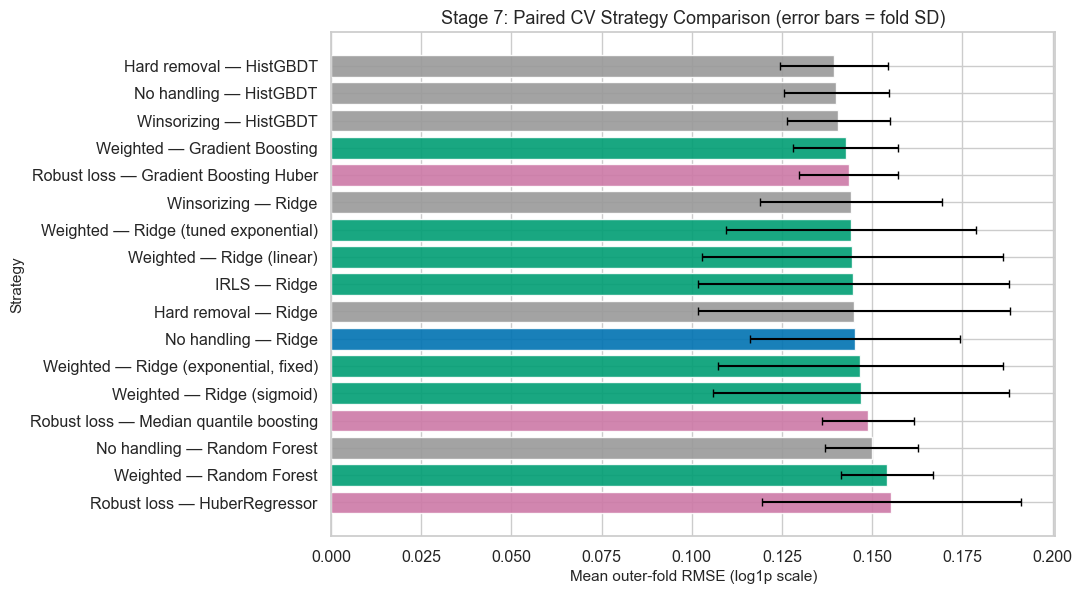

,hypothesis,stage7_CV_status,evidence
0,H1 Accuracy,Provisional; confirm against frozen hold-out p...,Best weighted CV RMSE=0.14268; best standard b...
1,H2 Contamination robustness,Not assessed here; requires Stage 8,Synthetic-contamination degradation is not par...
2,H3 Fold stability,Partially supported,Lowest weighted RMSE fold SD / best standard b...


Saved table: report_assets/tables/table_07_03_hypothesis_cv_status.csv and report_assets/tables/table_07_03_hypothesis_cv_status.md


,strategy,frozen_config,frozen_n_estimators,mean_inner_MAE_for_frozen_config,selection_source
0,Weighted Ridge,"{'scorer_type': 'rank_average', 'k': 3.0, 'w_m...",NaN,0.088803,Development inner-validation records only
1,Weighted Random Forest,"{'scorer_type': 'mean', 'k': 1.0, 'w_min': 0.05}",NaN,0.104732,Development inner-validation records only
2,Weighted Gradient Boosting,"{'scorer_type': 'rank_average', 'k': 3.0, 'w_m...",200.0,0.096178,Development inner-validation records only
3,HuberRegressor,{'epsilon': 1.5},NaN,0.091466,Development inner-validation records only
4,Gradient Boosting (Huber loss),"{'learning_rate': 0.05, 'n_estimators_ceiling'...",200.0,0.095881,Development inner-validation records only
5,Gradient Boosting (Median quantile),"{'learning_rate': 0.05, 'n_estimators_ceiling'...",200.0,0.102068,Development inner-validation records only


Saved table: report_assets/tables/table_07_04_frozen_final_configs.csv and report_assets/tables/table_07_04_frozen_final_configs.md


(WindowsPath('report_assets/tables/table_07_04_frozen_final_configs.csv'),
 WindowsPath('report_assets/tables/table_07_04_frozen_final_configs.md'))

In [30]:
# ── 7.1  Matched CV comparison, tests, effect sizes, and freeze ──────
from scipy.stats import wilcoxon, rankdata
from ast import literal_eval

# The no-handling Ridge baseline is the paired reference. Classic Stage 3
# methods and Stage 6 tuned methods already contain fold-wise results.
assert "Ridge (Baseline)" in CV_PER_FOLD_SCORES, "Run Stage 3 before Stage 7."
assert all(name in CV_PER_FOLD_SCORES for name in STAGE6_FAMILIES), "Run Stage 6 before Stage 7."

stage7_cv_folds = {}

def _copy_cv(label, source_label):
    frame = CV_PER_FOLD_SCORES[source_label].copy()
    if frame["fold"].min() == 0:
        frame["fold"] = frame["fold"] + 1
    frame["stage7_method"] = label
    stage7_cv_folds[label] = frame

_copy_cv("No handling — Ridge", "Ridge (Baseline)")
_copy_cv("No handling — Random Forest", "RandomForest (Baseline)")
_copy_cv("No handling — HistGBDT", "HistGBDT (Baseline, EarlyStop)")
_copy_cv("Hard removal — Ridge", "Ridge (Hard Removal - IQR)")
_copy_cv("Hard removal — HistGBDT", "HistGBDT (Hard Removal - IQR)")
_copy_cv("Winsorizing — Ridge", "Ridge (Target Winsorized)")
_copy_cv("Winsorizing — HistGBDT", "HistGBDT (Target Winsorized)")
_copy_cv("Robust loss — HuberRegressor", "HuberRegressor")
_copy_cv("Robust loss — Gradient Boosting Huber", "Gradient Boosting (Huber loss)")
_copy_cv("Robust loss — Median quantile boosting", "Gradient Boosting (Median quantile)")
_copy_cv("Weighted — Ridge (tuned exponential)", "Weighted Ridge")
_copy_cv("Weighted — Random Forest", "Weighted Random Forest")
_copy_cv("Weighted — Gradient Boosting", "Weighted Gradient Boosting")

# Additional matched Ridge CV runs for the Stage 5 linear, exponential, and
# sigmoid maps plus IRLS. Scores/weights are fit only on each outer training fold.
_mapping_specs = [
    ("Weighted — Ridge (linear)", "linear"),
    ("Weighted — Ridge (exponential, fixed)", "exponential"),
    ("Weighted — Ridge (sigmoid)", "sigmoid"),
]
for method_name, mapping in _mapping_specs:
    rows = []
    for fold, (tr_idx, va_idx) in enumerate(CV.split(X_dev, y_dev), start=1):
        X_tr, y_tr = X_dev.iloc[tr_idx], y_dev.iloc[tr_idx]
        X_va, y_va = X_dev.iloc[va_idx], y_dev.iloc[va_idx]
        fold_scorer = InfluenceScorer(random_state=SEED + fold).fit(X_tr, y_tr)
        anomaly = fold_scorer.combine("mean").to_numpy()
        if mapping == "linear":
            w = scores_to_weights(anomaly, "linear", w_min=W_MIN)
        elif mapping == "exponential":
            w = scores_to_weights(anomaly, "exponential", w_min=W_MIN, k=EXP_DECAY_K)
        else:
            w = scores_to_weights(anomaly, "sigmoid", w_min=W_MIN, sigmoid_slope=SIGMOID_SLOPE)
        m = clone(ridge_model)
        m.fit(X_tr, y_tr, model__sample_weight=w)
        pred = m.predict(X_va)
        rec = regression_metrics(y_va.to_numpy(), pred)
        rec.update({"fold": fold, "model": method_name, "stage7_method": method_name})
        rows.append(rec)
    stage7_cv_folds[method_name] = pd.DataFrame(rows)

# IRLS Ridge: residual weights are iteratively recomputed on each outer training fold.
irls_rows = []
for fold, (tr_idx, va_idx) in enumerate(CV.split(X_dev, y_dev), start=1):
    X_tr, y_tr = X_dev.iloc[tr_idx], y_dev.iloc[tr_idx]
    X_va, y_va = X_dev.iloc[va_idx], y_dev.iloc[va_idx]
    m_irls, w_irls, hist_irls = irls_reweight(
        ridge_model, X_tr, y_tr, loss="huber", threshold=ROBUST_THRESHOLD,
        w_min=W_MIN, T=IRLS_T, tol=IRLS_TOL, random_state=SEED + fold)
    pred = m_irls.predict(X_va)
    rec = regression_metrics(y_va.to_numpy(), pred)
    rec.update({"fold": fold, "model": "IRLS — Ridge", "stage7_method": "IRLS — Ridge",
                "mean_train_weight": float(np.mean(w_irls)),
                "irls_iterations": len(hist_irls)})
    irls_rows.append(rec)
stage7_cv_folds["IRLS — Ridge"] = pd.DataFrame(irls_rows)

# Tidy fold records and summary table.
stage7_all_folds = pd.concat(stage7_cv_folds.values(), ignore_index=True)
metric_cols = ["RMSE_log", "MAE_log", "MedAE_log", "P90_log", "R2", "RMSE_$", "MAE_$"]
stage7_summary_rows = []
for method_name, fold_df in stage7_cv_folds.items():
    row = {"strategy": method_name, "n_folds": len(fold_df)}
    for metric in metric_cols:
        row[metric] = fold_df[metric].mean()
        row[f"{metric}_std"] = fold_df[metric].std()
    stage7_summary_rows.append(row)
stage7_summary = pd.DataFrame(stage7_summary_rows).sort_values("RMSE_log").reset_index(drop=True)

# Paired tests: method minus the no-handling Ridge RMSE on identical CV folds.
reference = stage7_cv_folds["No handling — Ridge"].sort_values("fold")["RMSE_log"].to_numpy()
comparison_rows = []
def _rank_biserial(d):
    d = np.asarray(d, dtype=float)
    nz = d != 0
    if not nz.any():
        return 0.0
    ranks = rankdata(np.abs(d[nz]), method="average")
    signs = np.sign(d[nz])
    return float((ranks[signs > 0].sum() - ranks[signs < 0].sum()) / ranks.sum())

rng_ci = np.random.default_rng(SEED)
for method_name, fold_df in stage7_cv_folds.items():
    if method_name == "No handling — Ridge":
        continue
    aligned = fold_df.sort_values("fold")
    diffs = aligned["RMSE_log"].to_numpy() - reference
    try:
        test_result = wilcoxon(diffs, alternative="two-sided", zero_method="wilcox", method="auto")
        p_value = float(test_result.pvalue)
    except ValueError:
        p_value = 1.0
    boot_mean, boot_rbc = [], []
    for _ in range(5000):
        sample = rng_ci.choice(diffs, size=len(diffs), replace=True)
        boot_mean.append(float(np.mean(sample)))
        boot_rbc.append(_rank_biserial(sample))
    comparison_rows.append({
        "strategy": method_name,
        "mean_RMSE_difference": float(np.mean(diffs)),
        "mean_difference_CI_low": float(np.percentile(boot_mean, 2.5)),
        "mean_difference_CI_high": float(np.percentile(boot_mean, 97.5)),
        "relative_RMSE_change_pct": float(100 * np.mean(diffs) / np.mean(reference)),
        "wilcoxon_p": p_value,
        "rank_biserial_effect": _rank_biserial(diffs),
        "effect_CI_low": float(np.percentile(boot_rbc, 2.5)),
        "effect_CI_high": float(np.percentile(boot_rbc, 97.5)),
    })
paired_tests = pd.DataFrame(comparison_rows)
# Holm step-down adjustment, family-wise alpha = 0.05.
order = np.argsort(paired_tests["wilcoxon_p"].to_numpy())
m = len(order)
adjusted = np.empty(m, dtype=float)
carry = 0.0
pvals = paired_tests["wilcoxon_p"].to_numpy()
for rank, idx in enumerate(order):
    carry = max(carry, min(1.0, (m - rank) * pvals[idx]))
    adjusted[idx] = carry
paired_tests["wilcoxon_p_holm"] = adjusted
paired_tests["holm_significant_0_05"] = paired_tests["wilcoxon_p_holm"] < 0.05

stage7_ranked = stage7_summary.merge(paired_tests, on="strategy", how="left")
stage7_ranked["rank"] = np.arange(1, len(stage7_ranked) + 1)
stage7_ranked["paired_comparison"] = "vs No handling — Ridge"
rank_cols = ["rank", "strategy", "n_folds", "RMSE_log", "RMSE_log_std", "MAE_log", "MedAE_log", "P90_log",
             "mean_RMSE_difference", "mean_difference_CI_low", "mean_difference_CI_high",
             "relative_RMSE_change_pct", "wilcoxon_p", "wilcoxon_p_holm",
             "rank_biserial_effect", "effect_CI_low", "effect_CI_high", "holm_significant_0_05"]
ranked_summary = stage7_ranked[rank_cols]
display(ranked_summary.round(5))
save_table(ranked_summary.round(6), "table_07_01_paired_cv_ranked_comparison")
save_table(stage7_all_folds, "table_07_02_paired_cv_fold_scores")

# Ranked mean RMSE with fold-to-fold standard deviation error bars.
plot_df = stage7_summary.sort_values("RMSE_log", ascending=True)
fig, ax = plt.subplots(figsize=(11, max(6, 0.36 * len(plot_df))))
colors = ["#0072B2" if name == "No handling — Ridge" else "#009E73" if name.startswith("Weighted") or name.startswith("IRLS") else "#CC79A7" if name.startswith("Robust") else "#999999" for name in plot_df["strategy"]]
ax.barh(plot_df["strategy"], plot_df["RMSE_log"], xerr=plot_df["RMSE_log_std"], color=colors,
        edgecolor="white", capsize=3, alpha=.9)
ax.invert_yaxis()
ax.set(xlabel="Mean outer-fold RMSE (log1p scale)", ylabel="Strategy",
       title="Stage 7: Paired CV Strategy Comparison (error bars = fold SD)")
save_fig("fig_07_01_ranked_cv_rmse.png")
plt.show()

# Provisional CV hypothesis checks. H1's success criterion is finalized after
# the one-time hold-out evaluation; H2 requires the Stage 8 contamination test.
weighted_rows = stage7_summary[stage7_summary["strategy"].str.startswith("Weighted")]
standard_rows = stage7_summary[stage7_summary["strategy"].isin([
    "No handling — Ridge", "No handling — Random Forest", "No handling — HistGBDT"])]
best_weight_cv = weighted_rows.sort_values("RMSE_log").iloc[0]
best_standard_cv = standard_rows.sort_values("RMSE_log").iloc[0]
min_weighted_sd = weighted_rows["RMSE_log_std"].min()
best_standard_sd = best_standard_cv["RMSE_log_std"]
h3_ratio = min_weighted_sd / best_standard_sd
hypothesis_cv_status = pd.DataFrame([
    {"hypothesis": "H1 Accuracy", "stage7_CV_status": "Provisional; confirm against frozen hold-out predictions",
     "evidence": f"Best weighted CV RMSE={best_weight_cv['RMSE_log']:.5f}; best standard baseline={best_standard_cv['RMSE_log']:.5f}"},
    {"hypothesis": "H2 Contamination robustness", "stage7_CV_status": "Not assessed here; requires Stage 8",
     "evidence": "Synthetic-contamination degradation is not part of this CV comparison."},
    {"hypothesis": "H3 Fold stability", "stage7_CV_status": "Supported" if h3_ratio <= 0.80 else ("Partially supported" if h3_ratio < 1 else "Not supported"),
     "evidence": f"Lowest weighted RMSE fold SD / best standard baseline fold SD = {h3_ratio:.3f}; H3 threshold is <= 0.80."},
])
display(hypothesis_cv_status)
save_table(hypothesis_cv_status, "table_07_03_hypothesis_cv_status")

# Freeze final configurations using only CV inner-validation records. For each
# Stage 6 family choose the config with lowest average inner MAE; for boosting,
# use the median selected inner early-stopping iteration for that frozen config.
def freeze_stage6_config(family):
    folds = stage6_fold_tables[family].copy()
    folds["parsed_config"] = folds["config"].map(literal_eval)
    folds["config_key"] = folds["parsed_config"].map(lambda d: tuple(sorted(d.items())))
    mean_inner = folds.groupby("config_key")["inner_MAE"].mean().sort_values()
    winner_key = mean_inner.index[0]
    winning_rows = folds[folds["config_key"] == winner_key]
    frozen = dict(winning_rows.iloc[0]["parsed_config"])
    best_iters = winning_rows["best_iteration"].dropna()
    best_iter = int(np.median(best_iters)) if len(best_iters) else None
    return frozen, best_iter, float(mean_inner.iloc[0])

STAGE7_FROZEN_CONFIGS = {family: freeze_stage6_config(family) for family in STAGE6_FAMILIES}
frozen_config_rows = []
for family, (config, best_iter, mean_inner_mae) in STAGE7_FROZEN_CONFIGS.items():
    frozen_config_rows.append({"strategy": family, "frozen_config": str(config),
                               "frozen_n_estimators": best_iter,
                               "mean_inner_MAE_for_frozen_config": mean_inner_mae,
                               "selection_source": "Development inner-validation records only"})
frozen_config_table = pd.DataFrame(frozen_config_rows)
display(frozen_config_table)
save_table(frozen_config_table, "table_07_04_frozen_final_configs")


In [31]:
# ── 7.2  One-time frozen hold-out evaluation ────────────────────────
# No choices or hyperparameters are changed after this cell is run.
# Load the already-locked test partition only now, after development CV and
# configuration freezing. Earlier stages stored it at this path but did not
# create X_test/y_test in the notebook namespace.
if "X_test" not in globals() or "y_test" not in globals():
    df_test_locked = pd.read_parquet("./report_assets/test_set.parquet")
    _test_feature_cols = [c for c in df_test_locked.columns if c not in ("SalePrice", "LogSalePrice")]
    X_test = df_test_locked[_test_feature_cols].copy()
    y_test = df_test_locked["LogSalePrice"].copy()

def _frozen_spec(family):
    config, best_iter, _ = STAGE7_FROZEN_CONFIGS[family]
    return {"kind": "stage6", "family": family, "config": config, "best_iter": best_iter}

final_strategy_specs = [
    {"name": "No handling — Ridge", "kind": "ridge"},
    {"name": "No handling — Random Forest", "kind": "rf"},
    {"name": "No handling — HistGBDT", "kind": "histgb"},
    {"name": "Hard removal — Ridge", "kind": "hard_remove_ridge"},
    {"name": "Hard removal — HistGBDT", "kind": "hard_remove_histgb"},
    {"name": "Winsorizing — Ridge", "kind": "winsor_ridge"},
    {"name": "Winsorizing — HistGBDT", "kind": "winsor_histgb"},
    {"name": "Weighted — Ridge (linear)", "kind": "score_weight", "mapping": "linear"},
    {"name": "Weighted — Ridge (exponential, fixed)", "kind": "score_weight", "mapping": "exponential"},
    {"name": "Weighted — Ridge (sigmoid)", "kind": "score_weight", "mapping": "sigmoid"},
    {"name": "IRLS — Ridge", "kind": "irls"},
    {"name": "Weighted — Ridge (tuned exponential)", **_frozen_spec("Weighted Ridge")},
    {"name": "Weighted — Random Forest", **_frozen_spec("Weighted Random Forest")},
    {"name": "Weighted — Gradient Boosting", **_frozen_spec("Weighted Gradient Boosting")},
    {"name": "Robust loss — HuberRegressor", **_frozen_spec("HuberRegressor")},
    {"name": "Robust loss — Gradient Boosting Huber", **_frozen_spec("Gradient Boosting (Huber loss)")},
    {"name": "Robust loss — Median quantile boosting", **_frozen_spec("Gradient Boosting (Median quantile)")},
]


def _fit_frozen_strategy(spec, X_fit, y_fit):
    kind = spec["kind"]
    if kind == "ridge":
        return clone(ridge_model).fit(X_fit, y_fit)
    if kind == "rf":
        return clone(rf_model).fit(X_fit, y_fit)
    if kind == "histgb":
        return clone(hgb_model).fit(X_fit, y_fit)
    if kind in ("hard_remove_ridge", "hard_remove_histgb"):
        pilot = clone(ridge_model).fit(X_fit, y_fit)
        resid = y_fit.to_numpy() - pilot.predict(X_fit)
        q1, q3 = np.quantile(resid, [.25, .75])
        iqr = q3 - q1
        keep = (resid >= q1 - 2.5 * iqr) & (resid <= q3 + 2.5 * iqr)
        model = clone(ridge_model if kind.endswith("ridge") else hgb_model)
        return model.fit(X_fit.iloc[np.flatnonzero(keep)], y_fit.iloc[np.flatnonzero(keep)])
    if kind in ("winsor_ridge", "winsor_histgb"):
        model = clone(ridge_model if kind.endswith("ridge") else hgb_model)
        y_clip = y_fit.clip(y_fit.quantile(.01), y_fit.quantile(.99))
        return model.fit(X_fit, y_clip)
    if kind == "score_weight":
        scorer = InfluenceScorer(random_state=SEED).fit(X_fit, y_fit)
        scores = scorer.combine("mean").to_numpy()
        if spec["mapping"] == "linear":
            weights = scores_to_weights(scores, "linear", w_min=W_MIN)
        elif spec["mapping"] == "exponential":
            weights = scores_to_weights(scores, "exponential", w_min=W_MIN, k=EXP_DECAY_K)
        else:
            weights = scores_to_weights(scores, "sigmoid", w_min=W_MIN, sigmoid_slope=SIGMOID_SLOPE)
        model = clone(ridge_model).fit(X_fit, y_fit, model__sample_weight=weights)
        return model
    if kind == "irls":
        model, _, _ = irls_reweight(ridge_model, X_fit, y_fit, loss="huber",
            threshold=ROBUST_THRESHOLD, w_min=W_MIN, T=IRLS_T, tol=IRLS_TOL, random_state=SEED)
        return model
    if kind == "stage6":
        model, _ = _fit_selected_outer(spec["family"], spec["config"], spec["best_iter"],
                                       X_fit, y_fit, seed=SEED)
        return model
    raise ValueError(f"Unknown frozen strategy kind: {kind}")


def final_test_eval(strategy_name, strategy_spec, X_dev, y_dev, X_test, y_test,
                    n_boot=1000, seed=SEED):
    """Fit one frozen strategy on full development data and evaluate test once."""
    if strategy_name in STAGE7_TEST_EVALUATED:
        raise RuntimeError(f"Hold-out test evaluation already performed for: {strategy_name}")
    model = _fit_frozen_strategy(strategy_spec, X_dev, y_dev)
    pred = np.asarray(model.predict(X_test), dtype=float)
    yt = np.asarray(y_test, dtype=float)
    abs_err = np.abs(yt - pred)
    point = {
        "strategy": strategy_name,
        "test_RMSE_log": float(np.sqrt(np.mean((yt - pred) ** 2))),
        "test_MAE_log": float(np.mean(abs_err)),
        "test_MedAE_log": float(np.median(abs_err)),
        "test_P90_log": float(np.percentile(abs_err, 90)),
    }
    # Same bootstrap row indices are used across all four metrics for this strategy.
    rng = np.random.default_rng(seed)
    boot = {key: np.empty(n_boot) for key in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log"]}
    for b in range(n_boot):
        idx = rng.integers(0, len(yt), size=len(yt))
        err = abs_err[idx]
        boot["RMSE_log"][b] = np.sqrt(np.mean(err ** 2))
        boot["MAE_log"][b] = np.mean(err)
        boot["MedAE_log"][b] = np.median(err)
        boot["P90_log"][b] = np.percentile(err, 90)
    for metric in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log"]:
        point[f"test_{metric}_CI_low"] = float(np.percentile(boot[metric], 2.5))
        point[f"test_{metric}_CI_high"] = float(np.percentile(boot[metric], 97.5))
    STAGE7_TEST_EVALUATED.add(strategy_name)
    STAGE7_TEST_PREDICTIONS[strategy_name] = pred
    return point


# Persistent guard: re-running the cell will reuse saved test results and refuse
# to evaluate any named strategy more than once in the live kernel.
if "STAGE7_TEST_EVALUATED" not in globals():
    STAGE7_TEST_EVALUATED = set()
if "STAGE7_TEST_PREDICTIONS" not in globals():
    STAGE7_TEST_PREDICTIONS = {}
if "STAGE7_TEST_RESULTS" not in globals():
    STAGE7_TEST_RESULTS = {}

# All configs are frozen above. Each row below calls final_test_eval once at most.
for i, spec in enumerate(final_strategy_specs):
    name = spec["name"]
    if name not in STAGE7_TEST_RESULTS:
        STAGE7_TEST_RESULTS[name] = final_test_eval(
            name, spec, X_dev, y_dev, X_test, y_test, n_boot=1000, seed=SEED + i)

final_test_table = pd.DataFrame(STAGE7_TEST_RESULTS.values())
cv_gap_table = stage7_summary.rename(columns={"strategy": "strategy", "RMSE_log": "cv_RMSE_log",
                                               "RMSE_log_std": "cv_RMSE_log_std"})[["strategy", "cv_RMSE_log", "cv_RMSE_log_std"]]
final_test_table = final_test_table.merge(cv_gap_table, on="strategy", how="left")
final_test_table["test_minus_cv_RMSE"] = final_test_table["test_RMSE_log"] - final_test_table["cv_RMSE_log"]
final_test_table["large_CV_test_gap"] = final_test_table["test_minus_cv_RMSE"].abs() > 2 * final_test_table["cv_RMSE_log_std"]
display(final_test_table.round(5))
save_table(final_test_table.round(6), "table_07_05_one_time_holdout_results")

# Final protocol-level hypothesis statuses. H1 uses the preselected best CV
# weighted and no-handling candidates (frozen before accessing test outcomes).
weighted_names = [n for n in stage7_summary[stage7_summary["strategy"].str.startswith("Weighted")]["strategy"]
                  if n in STAGE7_TEST_RESULTS]
standard_names = [n for n in ["No handling — Ridge", "No handling — Random Forest", "No handling — HistGBDT"]
                  if n in STAGE7_TEST_RESULTS]
best_weighted_name = stage7_summary[stage7_summary["strategy"].isin(weighted_names)].sort_values("RMSE_log").iloc[0]["strategy"]
best_standard_name = stage7_summary[stage7_summary["strategy"].isin(standard_names)].sort_values("RMSE_log").iloc[0]["strategy"]
weighted_test_rmse = STAGE7_TEST_RESULTS[best_weighted_name]["test_RMSE_log"]
standard_test_rmse = STAGE7_TEST_RESULTS[best_standard_name]["test_RMSE_log"]
h1_gain = (standard_test_rmse - weighted_test_rmse) / standard_test_rmse
h1_status = "Supported" if h1_gain >= 0.01 else ("Partially supported" if h1_gain > 0 else "Not supported")

min_weighted_sd = stage7_summary[stage7_summary["strategy"].str.startswith("Weighted")]["RMSE_log_std"].min()
standard_sd = stage7_summary[stage7_summary["strategy"].isin(standard_names)]["RMSE_log_std"].min()
h3_reduction = 1 - min_weighted_sd / standard_sd
h3_status = "Supported" if h3_reduction >= 0.20 else ("Partially supported" if h3_reduction > 0 else "Not supported")
final_hypothesis_table = pd.DataFrame([
    {"hypothesis": "H1 Accuracy", "status": h1_status,
     "evidence": f"Preselected {best_weighted_name} vs {best_standard_name}: hold-out RMSE reduction {100*h1_gain:.2f}% (success threshold ≥1%)."},
    {"hypothesis": "H2 Contamination robustness", "status": "Not assessed yet",
     "evidence": "Requires the planned Stage 8 synthetic-contamination experiment."},
    {"hypothesis": "H3 Fold stability", "status": h3_status,
     "evidence": f"Lowest weighted CV RMSE SD is {100*h3_reduction:.1f}% lower than the lowest standard-baseline CV SD; success threshold ≥20%."},
])
display(final_hypothesis_table)
save_table(final_hypothesis_table, "table_07_06_hypothesis_status")


,strategy,test_RMSE_log,test_MAE_log,test_MedAE_log,test_P90_log,test_RMSE_log_CI_low,test_RMSE_log_CI_high,test_MAE_log_CI_low,test_MAE_log_CI_high,test_MedAE_log_CI_low,test_MedAE_log_CI_high,test_P90_log_CI_low,test_P90_log_CI_high,cv_RMSE_log,cv_RMSE_log_std,test_minus_cv_RMSE,large_CV_test_gap
0,No handling — Ridge,0.13780,0.09999,0.07615,0.19802,0.12037,0.15519,0.08934,0.11142,0.06492,0.08756,0.17321,0.25174,0.14519,0.02908,-0.00738,False
1,No handling — Random Forest,0.14979,0.09809,0.06652,0.23095,0.12367,0.17645,0.08559,0.11141,0.05620,0.07334,0.18863,0.25740,0.14984,0.01292,-0.00005,False
2,No handling — HistGBDT,0.13043,0.08409,0.05524,0.19032,0.10662,0.15307,0.07246,0.09489,0.04645,0.06576,0.16095,0.21121,0.14009,0.01454,-0.00965,False
3,Hard removal — Ridge,0.11350,0.08082,0.05639,0.17442,0.09838,0.12842,0.07197,0.09034,0.05159,0.06530,0.14514,0.20755,0.14502,0.04324,-0.03152,False
4,Hard removal — HistGBDT,0.12070,0.08330,0.05533,0.17073,0.10208,0.14202,0.07412,0.09471,0.05043,0.06587,0.14690,0.21550,0.13948,0.01501,-0.01877,False
5,Winsorizing — Ridge,0.14029,0.10061,0.07321,0.20250,0.12271,0.15794,0.08989,0.11187,0.06378,0.08441,0.17856,0.25341,0.14414,0.02517,-0.00385,False
6,Winsorizing — HistGBDT,0.13231,0.08546,0.05469,0.19230,0.10747,0.15763,0.07387,0.09712,0.04733,0.06145,0.16480,0.21834,0.14054,0.01424,-0.00823,False
7,Weighted — Ridge (linear),0.11543,0.08086,0.05359,0.18358,0.10013,0.13175,0.07164,0.09129,0.04735,0.06471,0.15335,0.20860,0.14451,0.04169,-0.02908,False
8,"Weighted — Ridge (exponential, fixed)",0.11858,0.08233,0.05372,0.18359,0.10278,0.13615,0.07323,0.09218,0.04731,0.06307,0.16439,0.21267,0.14666,0.03948,-0.02807,False
9,Weighted — Ridge (sigmoid),0.11751,0.08106,0.05482,0.18593,0.10218,0.13370,0.07224,0.09118,0.04698,0.06097,0.15743,0.21085,0.14683,0.04097,-0.02932,False


Saved table: report_assets/tables/table_07_05_one_time_holdout_results.csv and report_assets/tables/table_07_05_one_time_holdout_results.md


,hypothesis,status,evidence
0,H1 Accuracy,Supported,Preselected Weighted — Gradient Boosting vs No...
1,H2 Contamination robustness,Not assessed yet,Requires the planned Stage 8 synthetic-contami...
2,H3 Fold stability,Partially supported,Lowest weighted CV RMSE SD is 1.2% lower than ...


Saved table: report_assets/tables/table_07_06_hypothesis_status.csv and report_assets/tables/table_07_06_hypothesis_status.md


(WindowsPath('report_assets/tables/table_07_06_hypothesis_status.csv'),
 WindowsPath('report_assets/tables/table_07_06_hypothesis_status.md'))

### Stage 7 — Observations & Inferences

- **No strategy was statistically distinguishable from the no-handling Ridge reference after Holm correction.** All adjusted Wilcoxon p-values are at least 0.164. The best mean CV RMSE was hard removal with HistGBDT (0.13948 ± 0.01501), followed closely by unweighted HistGBDT (0.14009 ± 0.01454) and winsorized HistGBDT (0.14054 ± 0.01424). Their paired mean differences versus Ridge were negative, but their bootstrap intervals included zero. The apparent ranking differences therefore remain uncertain with 15 repeated-CV folds.
- **The Ridge-based score weighting and IRLS variants reduced some average errors but did not show a reliable RMSE gain.** Tuned exponential weighting had CV RMSE 0.14416 versus 0.14519 for Ridge, while linear weighting and IRLS had lower MAE/P90 but larger RMSE fold standard deviations (0.04169 and 0.04315 versus 0.02908 for Ridge). Fixed exponential and sigmoid weighting were slightly worse than Ridge on mean RMSE. None of these paired comparisons survived Holm correction.
- **Robust-loss performance varied by method.** Gradient boosting with Huber loss was competitive in CV (RMSE 0.14346 ± 0.01371). HuberRegressor had the highest CV RMSE among the listed strategies (0.15528 ± 0.03592); its unadjusted paired test against Ridge had p = 0.01025, but Holm-adjusted p = 0.16406. Its paired mean RMSE difference interval was positive (0.00415 to 0.01655), suggesting worse error than Ridge in these folds, but the multiple-comparison-adjusted result is not significant.
- **The frozen hold-out comparison meets the point-estimate criterion for H1, with uncertainty.** The best weighted method chosen from CV was Weighted Gradient Boosting. Its hold-out RMSE was 0.12376, compared with 0.13043 for the best standard baseline selected by CV (unweighted HistGBDT), a 5.1% point-estimate reduction. Their individual bootstrap intervals overlap substantially (0.10754–0.13958 and 0.10662–0.15307), so this single test split does not establish a precise or statistically reliable difference. Under the stated ≥1% point-estimate success rule, H1 is **supported**, with that qualification.
- **The reported H3 result is only partial.** The lowest weighted-model fold RMSE standard deviation was 1.2% below the lowest standard-baseline standard deviation, short of the 20% reduction criterion. H3 is **partially supported** by the point estimate, not by the prespecified threshold. H2 is **not assessed yet**; it requires Stage 8’s synthetic-contamination experiment.
- **HuberRegressor has a severe CV/test discrepancy that needs investigation.** Its test RMSE is 1.97891 (95% CI 1.94324–2.01974), versus CV RMSE 0.15528, and the notebook flags this as a large gap. Its test MAE is also 1.95718. This is far outside the pattern for the other methods and may indicate a fitting, convergence, or prediction-scale problem, rather than an ordinary generalization difference. Preserve this result as recorded and investigate the fitted model and prediction range before drawing a substantive conclusion about HuberRegressor; do not retune against the test set. All other strategies were below the notebook's two-fold-SD gap threshold, although their test RMSE point estimates were generally lower than their CV means.

**Overall inference:** These results do not show a consistent, statistically significant CV advantage for reliability weighting over standard baselines. The frozen Weighted Gradient Boosting model clears the stated H1 hold-out point-estimate threshold, while H3 misses its 20% stability threshold and H2 awaits the contamination experiment. The HuberRegressor test anomaly should be resolved as an implementation or convergence issue before the report treats that method's test score as a valid model comparison.


---
## Stage 8 — Robustness Under Synthetic Training Contamination

**Goal:** Measure how model performance and influence-score detection change when only the outer training fold is synthetically contaminated.

**Contamination protocol:** Sweep p ∈ {0, 2, 5, 10, 20}% for (1) target noise, (2) leverage contamination in numeric features, and (3) mixed contamination applying both to the same selected rows. Target corruption randomly applies either a multiplicative price shift (×0.5–2.0 on the raw price before returning to log space) or an additive shift of ±0.5–1.0 in log-price. Leverage corruption replaces 1–3 numeric values per selected row with extreme values 8 IQRs from the training-fold median. Two independent seeded contamination repeats are used to keep the nested repeated-CV sweep practical; repeat-SD estimates are therefore descriptive and coarse.

**Leakage and early-stopping guard:** Contamination is applied to the outer training portion only. The outer CV validation fold and locked hold-out test set remain clean. For boosting methods, the inner 15% split is drawn *after* contamination is applied, so inner early-stopping rows may be contaminated, reflecting the unknown-corruption setting. Fitted preprocessing, scoring, sample weights, removal, clipping, and residual reweighting use outer training data only. Stage 7 configurations remain frozen; no test set is used in this experiment.

**Reporting:** Plot outer-fold RMSE and P90 error against contamination level for each contamination type, with error bars showing variability across the three repeat-level CV means. Score detection on the contaminated outer training rows against the known corruption mask using AUROC and precision@k (k = number of injected rows). Define sharp degradation as the first contamination level where mean RMSE is at least 10% above that strategy's clean (p=0) mean for the same contamination type.


Completed target noise at 0% contamination, repeat 1/2.
Completed target noise at 0% contamination, repeat 2/2.
Completed target noise at 2% contamination, repeat 1/2.
Completed target noise at 2% contamination, repeat 2/2.
Completed target noise at 5% contamination, repeat 1/2.
Completed target noise at 5% contamination, repeat 2/2.
Completed target noise at 10% contamination, repeat 1/2.
Completed target noise at 10% contamination, repeat 2/2.
Completed target noise at 20% contamination, repeat 1/2.
Completed target noise at 20% contamination, repeat 2/2.
Completed leverage points at 0% contamination, repeat 1/2.
Completed leverage points at 0% contamination, repeat 2/2.
Completed leverage points at 2% contamination, repeat 1/2.
Completed leverage points at 2% contamination, repeat 2/2.
Completed leverage points at 5% contamination, repeat 1/2.
Completed leverage points at 5% contamination, repeat 2/2.
Completed leverage points at 10% contamination, repeat 1/2.
Completed leverage poi

,contamination_type,contamination_pct,strategy,RMSE_log_mean,P90_log_mean,MAE_log_mean,MedAE_log_mean,RMSE_log_repeat_sd,P90_log_repeat_sd,MAE_log_repeat_sd,MedAE_log_repeat_sd
0,leverage points,0,Hard removal — Ridge,0.1450,0.1665,0.0839,0.0572,0.0000,0.0000,0.0000,0.0000
1,leverage points,0,IRLS — Ridge,0.1448,0.1662,0.0834,0.0570,0.0000,0.0000,0.0000,0.0000
2,leverage points,0,No handling — Ridge,0.1452,0.1844,0.0923,0.0665,0.0000,0.0000,0.0000,0.0000
3,leverage points,0,Robust loss — HuberRegressor,0.1553,0.1902,0.0918,0.0594,0.0000,0.0000,0.0000,0.0000
4,leverage points,0,Weighted — Gradient Boosting,0.1427,0.2051,0.0955,0.0663,0.0000,0.0000,0.0000,0.0000
5,leverage points,0,Weighted — Random Forest,0.1540,0.2332,0.1013,0.0667,0.0000,0.0000,0.0000,0.0000
6,leverage points,0,Weighted — Ridge (linear),0.1445,0.1719,0.0850,0.0588,0.0000,0.0000,0.0000,0.0000
7,leverage points,0,Weighted — Ridge (sigmoid),0.1468,0.1787,0.0859,0.0590,0.0000,0.0000,0.0000,0.0000
8,leverage points,0,Weighted — Ridge (tuned exponential),0.1467,0.1798,0.0874,0.0612,0.0000,0.0000,0.0000,0.0000
9,leverage points,0,Winsorizing — Ridge,0.1441,0.1843,0.0930,0.0677,0.0000,0.0000,0.0000,0.0000


,contamination_type,contamination_pct,AUROC_mean,AUROC_repeat_sd,precision_at_k_mean,precision_at_k_repeat_sd
0,leverage points,0,NaN,NaN,NaN,NaN
1,leverage points,2,0.9385,0.0035,0.3140,0.0323
2,leverage points,5,0.9394,0.0027,0.4631,0.0171
3,leverage points,10,0.9427,0.0013,0.6035,0.0036
4,leverage points,20,0.9468,0.0012,0.7323,0.0025
5,mixed,0,NaN,NaN,NaN,NaN
6,mixed,2,0.9727,0.0043,0.5175,0.0074
7,mixed,5,0.9745,0.0020,0.6496,0.0000
8,mixed,10,0.9770,0.0019,0.7580,0.0040
9,mixed,20,0.9810,0.0000,0.8613,0.0005


Saved table: report_assets/tables/table_08_01_contamination_fold_scores.csv and report_assets/tables/table_08_01_contamination_fold_scores.md
Saved table: report_assets/tables/table_08_02_contamination_performance_summary.csv and report_assets/tables/table_08_02_contamination_performance_summary.md
Saved table: report_assets/tables/table_08_03_injected_row_detection_fold_scores.csv and report_assets/tables/table_08_03_injected_row_detection_fold_scores.md
Saved table: report_assets/tables/table_08_04_injected_row_detection_summary.csv and report_assets/tables/table_08_04_injected_row_detection_summary.md
Saved figure: report_assets/figures/fig_08_01_rmse_by_contamination.png


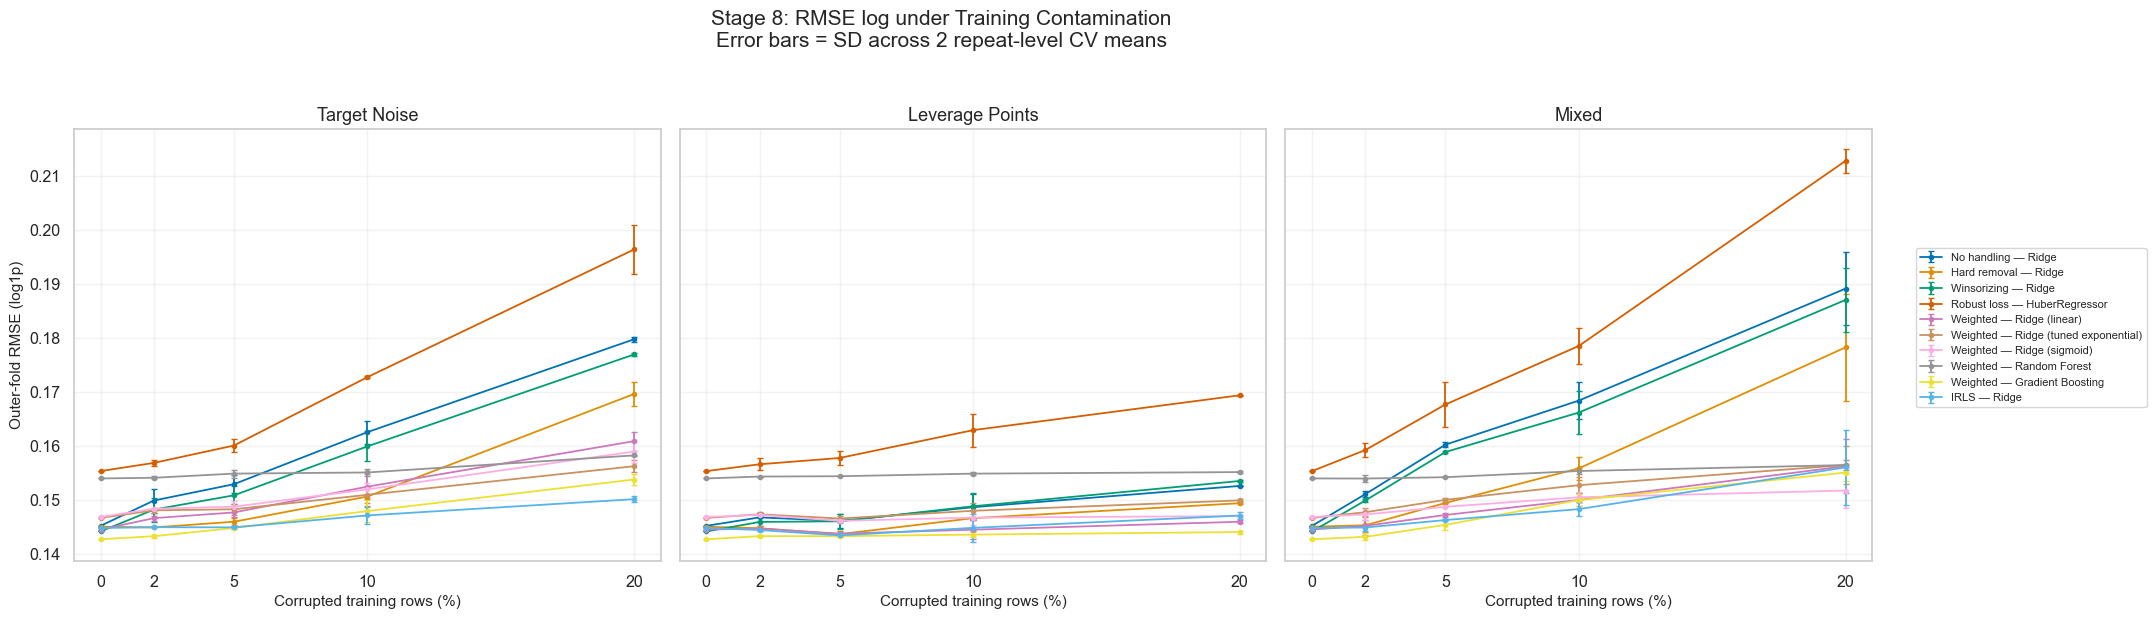

Saved figure: report_assets/figures/fig_08_02_p90_by_contamination.png


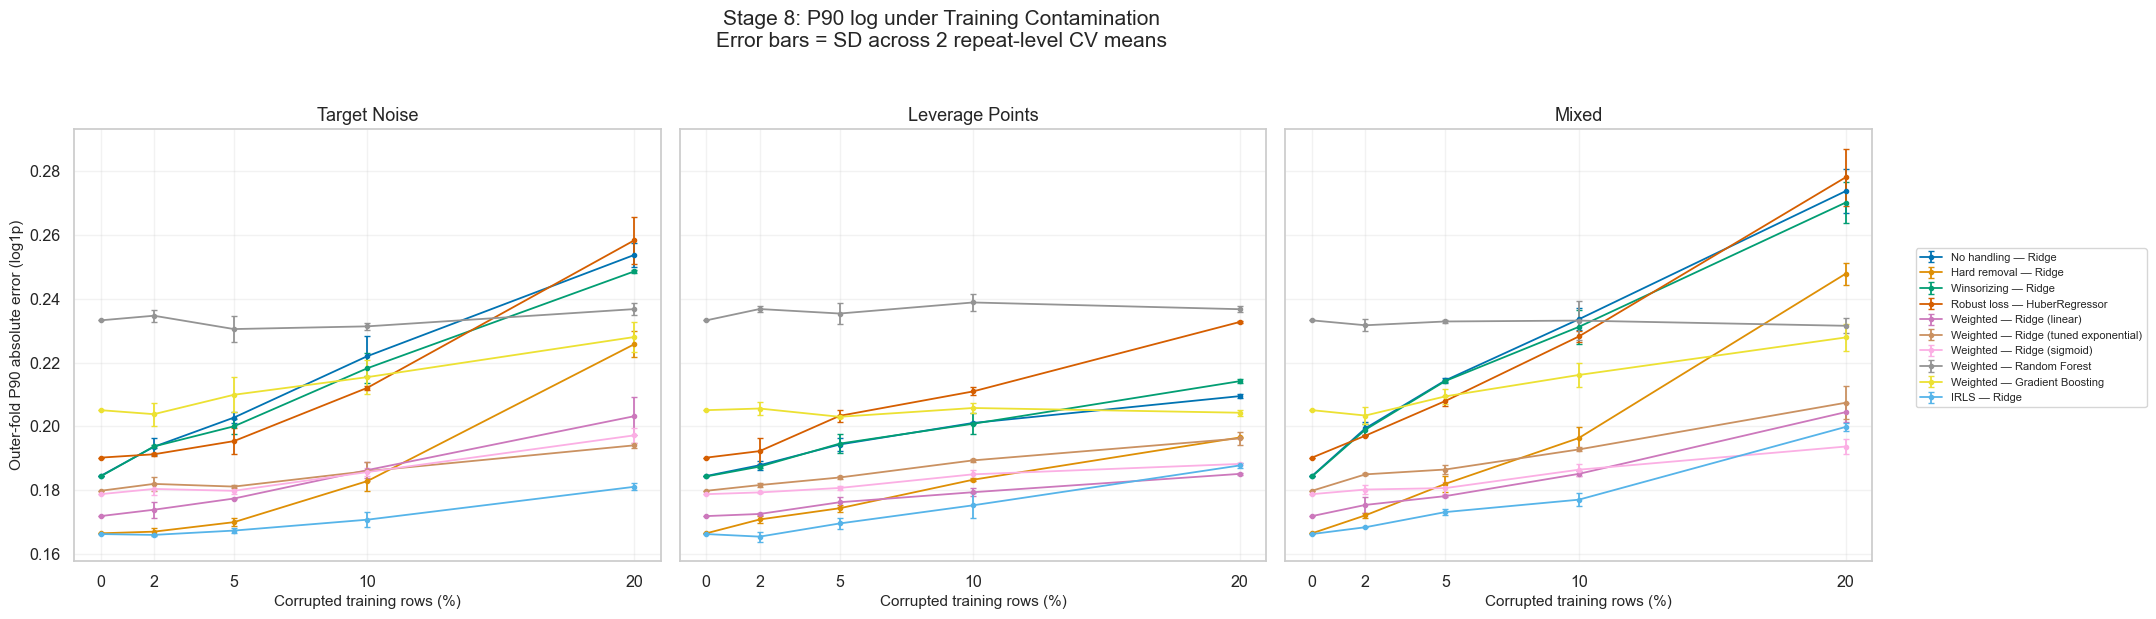

Saved figure: report_assets/figures/fig_08_03_injected_row_detection.png


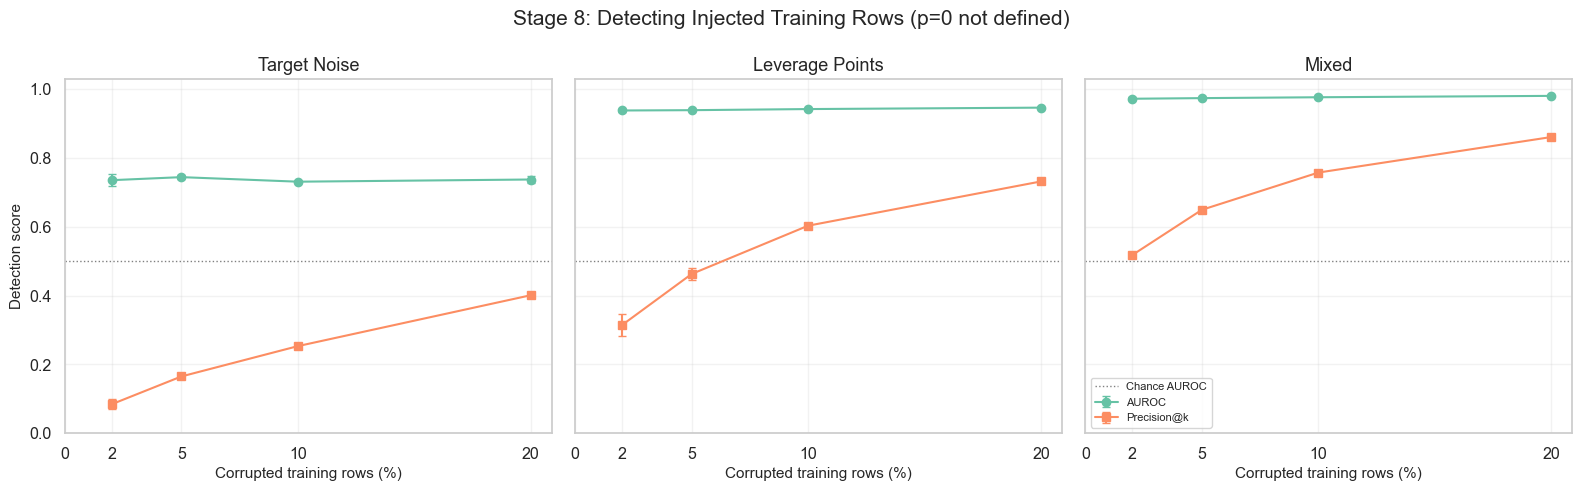

,contamination_type,strategy,clean_RMSE,sharp_degradation_at_pct,threshold
0,target noise,No handling — Ridge,0.145187,10.0,≥10% above clean mean RMSE
1,target noise,Hard removal — Ridge,0.145021,20.0,≥10% above clean mean RMSE
2,target noise,Winsorizing — Ridge,0.144142,10.0,≥10% above clean mean RMSE
3,target noise,Robust loss — HuberRegressor,0.155323,10.0,≥10% above clean mean RMSE
4,target noise,Weighted — Ridge (linear),0.144509,20.0,≥10% above clean mean RMSE
5,target noise,Weighted — Ridge (tuned exponential),0.146658,NaN,≥10% above clean mean RMSE
6,target noise,Weighted — Ridge (sigmoid),0.146833,NaN,≥10% above clean mean RMSE
7,target noise,Weighted — Random Forest,0.153963,NaN,≥10% above clean mean RMSE
8,target noise,Weighted — Gradient Boosting,0.142704,NaN,≥10% above clean mean RMSE
9,target noise,IRLS — Ridge,0.144790,NaN,≥10% above clean mean RMSE


Saved table: report_assets/tables/table_08_05_sharp_degradation_thresholds.csv and report_assets/tables/table_08_05_sharp_degradation_thresholds.md


(WindowsPath('report_assets/tables/table_08_05_sharp_degradation_thresholds.csv'),
 WindowsPath('report_assets/tables/table_08_05_sharp_degradation_thresholds.md'))

In [32]:
# ── 8.1  Training-only contamination, frozen methods, and detection ─
from sklearn.metrics import roc_auc_score

CONTAMINATION_LEVELS = [0, 2, 5, 10, 20]
CONTAMINATION_TYPES = ["target noise", "leverage points", "mixed"]
N_CONTAMINATION_REPEATS = 2
SHARP_DEGRADATION_RELATIVE = 0.10

# Stage 8 methods cover the main handling strategies, with a matched Ridge
# comparison plus the strongest tree/robust alternatives from Stage 7.
STAGE8_METHODS = [
    "No handling — Ridge",
    "Hard removal — Ridge",
    "Winsorizing — Ridge",
    "Robust loss — HuberRegressor",
    "Weighted — Ridge (linear)",
    "Weighted — Ridge (tuned exponential)",
    "Weighted — Ridge (sigmoid)",
    "Weighted — Random Forest",
    "Weighted — Gradient Boosting",
    "IRLS — Ridge",
]

def inject_training_contamination(X_train, y_train, contamination_pct, contamination_type, seed):
    """Return corrupted copies and a row-level ground-truth corruption mask."""
    Xc = pd.DataFrame(X_train).copy().reset_index(drop=True)
    yc = pd.Series(np.asarray(y_train, dtype=float)).copy()
    n = len(Xc)
    p = float(contamination_pct) / 100.0
    n_bad = int(round(p * n))
    rng = np.random.default_rng(seed)
    mask = np.zeros(n, dtype=bool)
    if n_bad == 0:
        return Xc, yc, mask
    bad_rows = rng.choice(n, size=n_bad, replace=False)
    mask[bad_rows] = True

    if contamination_type in ("target noise", "mixed"):
        raw_price = np.expm1(yc.to_numpy())
        for row in bad_rows:
            if rng.random() < 0.5:
                raw_price[row] *= rng.uniform(0.5, 2.0)
                yc.iloc[row] = np.log1p(max(raw_price[row], 0.0))
            else:
                direction = rng.choice([-1.0, 1.0])
                yc.iloc[row] += direction * rng.uniform(0.5, 1.0)

    if contamination_type in ("leverage points", "mixed"):
        numeric_cols = list(Xc.select_dtypes(include=np.number).columns)
        if not numeric_cols:
            raise ValueError("Leverage contamination requires numeric input features.")
        for row in bad_rows:
            n_changed = int(rng.integers(1, min(3, len(numeric_cols)) + 1))
            cols = rng.choice(numeric_cols, size=n_changed, replace=False)
            for col in cols:
                vals = pd.to_numeric(X_train[col], errors="coerce").to_numpy(dtype=float)
                finite = vals[np.isfinite(vals)]
                med = float(np.median(finite)) if len(finite) else 0.0
                q1, q3 = np.percentile(finite, [25, 75]) if len(finite) else (0.0, 0.0)
                spread = float(q3 - q1)
                if not np.isfinite(spread) or spread <= 1e-9:
                    spread = float(np.std(finite)) if len(finite) else 1.0
                spread = max(spread, 1.0)
                sign = float(rng.choice([-1.0, 1.0]))
                Xc.loc[row, col] = med + sign * 8.0 * spread

    if contamination_type not in CONTAMINATION_TYPES:
        raise ValueError(f"Unknown contamination type: {contamination_type}")
    return Xc, yc, mask


def _stage8_frozen_config(family):
    config, best_iter, _ = STAGE7_FROZEN_CONFIGS[family]
    return dict(config), best_iter


def _fit_stage8_boosting(family, config, X_cont, y_cont, X_val, y_val,
                         weights=None, seed=SEED):
    """Early-stop on an inner split drawn from already-contaminated training data."""
    inner_fit_idx, inner_val_idx = train_test_split(
        np.arange(len(X_cont)), test_size=INNER_VAL_FRACTION,
        random_state=seed, shuffle=True)
    X_inner = X_cont.iloc[inner_fit_idx]
    y_inner = y_cont.iloc[inner_fit_idx]
    X_inner_val = X_cont.iloc[inner_val_idx]
    y_inner_val = y_cont.iloc[inner_val_idx]
    inner_weights = weights[inner_fit_idx] if weights is not None else None

    if family == "Weighted Gradient Boosting":
        estimator = GradientBoostingRegressor(loss="squared_error",
            learning_rate=config["learning_rate"], n_estimators=config["n_estimators_ceiling"],
            max_depth=2, min_samples_leaf=3, random_state=seed)
    else:
        estimator = _robust_model_factory(family, seed, config)
    best_iter, inner_mae, _ = _fit_boosting_inner(
        estimator, X_inner, y_inner, X_inner_val, y_inner_val,
        weights=inner_weights, patience=BOOST_PATIENCE)
    estimator.set_params(n_estimators=max(1, best_iter))
    final_pipe = _pipeline_with_estimator(estimator)
    _fit_pipeline_weighted(final_pipe, X_cont, y_cont, weights)
    return final_pipe, best_iter, inner_mae


def _stage8_fit_predict(method, X_cont, y_cont, X_clean_val, y_clean_val, full_scorer, seed):
    """Fit one frozen strategy using corrupted training data; validation remains clean."""
    anomaly_mean = full_scorer.combine("mean").to_numpy()
    if method == "No handling — Ridge":
        model = clone(ridge_model).fit(X_cont, y_cont)
    elif method == "No handling — Random Forest":
        model = clone(rf_model).fit(X_cont, y_cont)
    elif method == "No handling — HistGBDT":
        model = clone(hgb_model).fit(X_cont, y_cont)
    elif method in ("Hard removal — Ridge", "Hard removal — HistGBDT"):
        pilot = clone(ridge_model).fit(X_cont, y_cont)
        resid = y_cont.to_numpy() - pilot.predict(X_cont)
        q1, q3 = np.quantile(resid, [.25, .75])
        iqr = q3 - q1
        keep = (resid >= q1 - 2.5 * iqr) & (resid <= q3 + 2.5 * iqr)
        if keep.sum() < 10:
            keep[:] = True
        base = ridge_model if method.endswith("Ridge") else hgb_model
        model = clone(base).fit(X_cont.iloc[np.flatnonzero(keep)], y_cont.iloc[np.flatnonzero(keep)])
    elif method in ("Winsorizing — Ridge", "Winsorizing — HistGBDT"):
        base = ridge_model if method.endswith("Ridge") else hgb_model
        y_clip = y_cont.clip(y_cont.quantile(.01), y_cont.quantile(.99))
        model = clone(base).fit(X_cont, y_clip)
    elif method == "Robust loss — HuberRegressor":
        config, _ = _stage8_frozen_config("HuberRegressor")
        model, _ = _fit_selected_outer("HuberRegressor", config, None, X_cont, y_cont, seed=seed)
    elif method in ("Weighted — Ridge (linear)", "Weighted — Ridge (exponential, fixed)", "Weighted — Ridge (sigmoid)"):
        if method.endswith("linear)"):
            weights = scores_to_weights(anomaly_mean, "linear", w_min=W_MIN)
        elif method.endswith("fixed)"):
            weights = scores_to_weights(anomaly_mean, "exponential", w_min=W_MIN, k=EXP_DECAY_K)
        else:
            weights = scores_to_weights(anomaly_mean, "sigmoid", w_min=W_MIN, sigmoid_slope=SIGMOID_SLOPE)
        model = clone(ridge_model).fit(X_cont, y_cont, model__sample_weight=weights)
    elif method == "Weighted — Ridge (tuned exponential)":
        config, _ = _stage8_frozen_config("Weighted Ridge")
        scores = full_scorer.combine(config["scorer_type"]).to_numpy()
        weights = scores_to_weights(scores, "exponential", w_min=config["w_min"], k=config["k"])
        model = clone(ridge_model).fit(X_cont, y_cont, model__sample_weight=weights)
    elif method == "Weighted — Random Forest":
        config, _ = _stage8_frozen_config("Weighted Random Forest")
        scores = full_scorer.combine(config["scorer_type"]).to_numpy()
        weights = scores_to_weights(scores, "exponential", w_min=config["w_min"], k=config["k"])
        model = _weighted_model_factory("Weighted Random Forest", seed, config)
        _fit_pipeline_weighted(model, X_cont, y_cont, weights)
    elif method == "IRLS — Ridge":
        model, _, _ = irls_reweight(ridge_model, X_cont, y_cont, loss="huber",
            threshold=ROBUST_THRESHOLD, w_min=W_MIN, T=IRLS_T, tol=IRLS_TOL, random_state=seed)
    elif method == "Weighted — Gradient Boosting":
        config, _ = _stage8_frozen_config("Weighted Gradient Boosting")
        scores = full_scorer.combine(config["scorer_type"]).to_numpy()
        weights = scores_to_weights(scores, "exponential", w_min=config["w_min"], k=config["k"])
        model, _, _ = _fit_stage8_boosting("Weighted Gradient Boosting", config,
            X_cont, y_cont, X_clean_val, y_clean_val, weights=weights, seed=seed)
    elif method == "Robust loss — Gradient Boosting Huber":
        config, _ = _stage8_frozen_config("Gradient Boosting (Huber loss)")
        model, _, _ = _fit_stage8_boosting("Gradient Boosting (Huber loss)", config,
            X_cont, y_cont, X_clean_val, y_clean_val, weights=None, seed=seed)
    elif method == "Robust loss — Median quantile boosting":
        config, _ = _stage8_frozen_config("Gradient Boosting (Median quantile)")
        model, _, _ = _fit_stage8_boosting("Gradient Boosting (Median quantile)", config,
            X_cont, y_cont, X_clean_val, y_clean_val, weights=None, seed=seed)
    else:
        raise ValueError(f"Unknown Stage 8 method: {method}")
    return model.predict(X_clean_val)


stage8_per_fold_records, stage8_detection_records = [], []
for contamination_type in CONTAMINATION_TYPES:
    for pct in CONTAMINATION_LEVELS:
        for repeat in range(N_CONTAMINATION_REPEATS):
            repeat_seed = SEED + 1000 * repeat + 100 * pct + CONTAMINATION_TYPES.index(contamination_type)
            for fold, (tr_idx, va_idx) in enumerate(CV.split(X_dev, y_dev), start=1):
                X_clean_train, y_clean_train = X_dev.iloc[tr_idx], y_dev.iloc[tr_idx]
                X_clean_val, y_clean_val = X_dev.iloc[va_idx], y_dev.iloc[va_idx]
                X_cont, y_cont, corruption_mask = inject_training_contamination(
                    X_clean_train, y_clean_train, pct, contamination_type,
                    seed=repeat_seed + fold)
                # Scorer is trained on the outer training portion only. Its scores
                # are also used to assess injected-row detection, not as labels.
                fold_scorer = InfluenceScorer(random_state=SEED + fold).fit(X_cont, y_cont)
                score = fold_scorer.combine("mean").to_numpy()
                if corruption_mask.any():
                    auc = roc_auc_score(corruption_mask.astype(int), score)
                    k_detect = int(corruption_mask.sum())
                    top_idx = np.argsort(score)[-k_detect:]
                    precision_k = float(corruption_mask[top_idx].mean())
                else:
                    auc, precision_k = np.nan, np.nan
                stage8_detection_records.append({
                    "contamination_type": contamination_type, "contamination_pct": pct,
                    "repeat": repeat + 1, "fold": fold,
                    "n_injected": int(corruption_mask.sum()),
                    "AUROC": auc, "precision_at_k": precision_k,
                })

                for method in STAGE8_METHODS:
                    pred = _stage8_fit_predict(method, X_cont, y_cont, X_clean_val,
                                               y_clean_val, fold_scorer,
                                               seed=SEED + fold)
                    met = regression_metrics(y_clean_val.to_numpy(), pred)
                    stage8_per_fold_records.append({
                        "contamination_type": contamination_type,
                        "contamination_pct": pct, "repeat": repeat + 1,
                        "fold": fold, "strategy": method,
                        "RMSE_log": met["RMSE_log"], "MAE_log": met["MAE_log"],
                        "P90_log": met["P90_log"], "MedAE_log": met["MedAE_log"],
                    })
            print(f"Completed {contamination_type} at {pct}% contamination, repeat {repeat + 1}/{N_CONTAMINATION_REPEATS}.")

stage8_fold_df = pd.DataFrame(stage8_per_fold_records)
stage8_detection_fold_df = pd.DataFrame(stage8_detection_records)

# First average across the 15 outer CV folds for each contamination replicate;
# then summarize mean and SD across the 3 contamination repeats.
stage8_repeat_perf = (stage8_fold_df.groupby(
    ["contamination_type", "contamination_pct", "repeat", "strategy"], as_index=False)
    [["RMSE_log", "P90_log", "MAE_log", "MedAE_log"]].mean())
stage8_perf_summary = (stage8_repeat_perf.groupby(
    ["contamination_type", "contamination_pct", "strategy"], as_index=False)
    .agg(**{f"{m}_mean": (m, "mean") for m in ["RMSE_log", "P90_log", "MAE_log", "MedAE_log"]},
         **{f"{m}_repeat_sd": (m, "std") for m in ["RMSE_log", "P90_log", "MAE_log", "MedAE_log"]}))
stage8_repeat_detection = (stage8_detection_fold_df.groupby(
    ["contamination_type", "contamination_pct", "repeat"], as_index=False)
    [["AUROC", "precision_at_k"]].mean())
stage8_detection_summary = (stage8_repeat_detection.groupby(
    ["contamination_type", "contamination_pct"], as_index=False)
    .agg(AUROC_mean=("AUROC", "mean"), AUROC_repeat_sd=("AUROC", "std"),
         precision_at_k_mean=("precision_at_k", "mean"),
         precision_at_k_repeat_sd=("precision_at_k", "std")))

display(stage8_perf_summary.head(20).round(4))
display(stage8_detection_summary.round(4))
save_table(stage8_fold_df, "table_08_01_contamination_fold_scores")
save_table(stage8_perf_summary, "table_08_02_contamination_performance_summary")
save_table(stage8_detection_fold_df, "table_08_03_injected_row_detection_fold_scores")
save_table(stage8_detection_summary, "table_08_04_injected_row_detection_summary")

# Performance curves: mean across contamination repeats, error bars = SD of
# repeat-level CV means (not SD across individual folds).
method_palette = dict(zip(STAGE8_METHODS, sns.color_palette("colorblind", n_colors=len(STAGE8_METHODS))))
for metric, ylabel, filename in [
    ("RMSE_log", "Outer-fold RMSE (log1p)", "fig_08_01_rmse_by_contamination.png"),
    ("P90_log", "Outer-fold P90 absolute error (log1p)", "fig_08_02_p90_by_contamination.png"),
]:
    fig, axes = plt.subplots(1, len(CONTAMINATION_TYPES), figsize=(19, 6), sharey=True)
    for ax, ctype in zip(axes, CONTAMINATION_TYPES):
        subset = stage8_perf_summary[stage8_perf_summary["contamination_type"] == ctype]
        for method in STAGE8_METHODS:
            part = subset[subset["strategy"] == method].sort_values("contamination_pct")
            ax.errorbar(part["contamination_pct"], part[f"{metric}_mean"],
                yerr=part[f"{metric}_repeat_sd"].fillna(0), marker="o", ms=3,
                capsize=2, linewidth=1.3, color=method_palette[method], label=method)
        ax.set(title=ctype.title(), xlabel="Corrupted training rows (%)")
        ax.set_xticks(CONTAMINATION_LEVELS)
        ax.grid(alpha=.25)
    axes[0].set_ylabel(ylabel)
    handles, labels = axes[-1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.01, .5), fontsize=8)
    fig.suptitle(f"Stage 8: {metric.replace('_', ' ')} under Training Contamination\nError bars = SD across {N_CONTAMINATION_REPEATS} repeat-level CV means", y=1.03)
    save_fig(filename)
    plt.show()

# Scorer detection curves by corruption type; p=0 is intentionally undefined.
fig, axes = plt.subplots(1, len(CONTAMINATION_TYPES), figsize=(16, 5), sharey=True)
for ax, ctype in zip(axes, CONTAMINATION_TYPES):
    part = stage8_detection_summary[stage8_detection_summary["contamination_type"] == ctype]
    ax.errorbar(part["contamination_pct"], part["AUROC_mean"], yerr=part["AUROC_repeat_sd"],
                marker="o", capsize=3, label="AUROC")
    ax.errorbar(part["contamination_pct"], part["precision_at_k_mean"], yerr=part["precision_at_k_repeat_sd"],
                marker="s", capsize=3, label="Precision@k")
    ax.axhline(.5, color="grey", ls=":", lw=1, label="Chance AUROC")
    ax.set(title=ctype.title(), xlabel="Corrupted training rows (%)", xticks=CONTAMINATION_LEVELS,
           ylim=(0, 1.03))
    ax.grid(alpha=.25)
axes[0].set_ylabel("Detection score")
axes[-1].legend(fontsize=8)
fig.suptitle("Stage 8: Detecting Injected Training Rows (positive contamination levels)")
save_fig("fig_08_03_injected_row_detection.png")
plt.show()

# Define a sharp increase as >=10% above each method's own clean mean RMSE.
degradation_rows = []
for ctype in CONTAMINATION_TYPES:
    part = stage8_perf_summary[stage8_perf_summary["contamination_type"] == ctype]
    for method in STAGE8_METHODS:
        method_part = part[part["strategy"] == method].sort_values("contamination_pct")
        clean_rmse = float(method_part.loc[method_part["contamination_pct"] == 0, "RMSE_log_mean"].iloc[0])
        crossed = method_part[(method_part["contamination_pct"] > 0) &
                              (method_part["RMSE_log_mean"] >= clean_rmse * (1 + SHARP_DEGRADATION_RELATIVE))]
        sharp_at = int(crossed["contamination_pct"].iloc[0]) if len(crossed) else None
        degradation_rows.append({"contamination_type": ctype, "strategy": method,
            "clean_RMSE": clean_rmse, "sharp_degradation_at_pct": sharp_at,
            "threshold": f"≥{100*SHARP_DEGRADATION_RELATIVE:.0f}% above clean mean RMSE"})
stage8_degradation = pd.DataFrame(degradation_rows)
display(stage8_degradation)
save_table(stage8_degradation, "table_08_05_sharp_degradation_thresholds")


### Stage 8 — Observations & Inferences

- **Detection varied by contamination type.** The combined influence scorer achieved AUROC values of about 0.94–0.95 for leverage contamination and 0.97–0.98 for mixed contamination. It was less effective for target noise (about 0.73–0.74 AUROC). Precision@k shows a similar pattern: at 2% contamination it was 0.314 for leverage and 0.518 for mixed contamination, versus 0.084 for target noise. Thus, the scorer identified extreme feature-space changes more reliably than target-only corruption. At p=0 the detector metrics are undefined because there are no injected positive cases; those values are correctly omitted.

- **Target noise and mixed contamination produced the clearest deterioration.** Using the notebook's prespecified threshold (first tested level where mean RMSE is at least 10% above that strategy's clean mean), no-handling Ridge crossed at 10% target noise and 5% mixed contamination. Winsorizing Ridge crossed at 10% target noise and 5% mixed contamination; HuberRegressor crossed at 10% for both; hard-removal Ridge crossed at 20% for both. No strategy crossed the threshold under leverage contamination at the tested levels. A threshold marked not reached means only that the 10% increase was not observed at p ∈ {0, 2, 5, 10, 20}; it does not imply immunity to stronger or different contamination.

- **Reliability weighting was not uniformly beneficial.** Several weighted and IRLS curves rose more gradually than no-handling Ridge for some corruption types, particularly under target noise or mixed contamination, but the pattern differed across methods and metrics. The 90th-percentile error also increased for some weighted approaches, so the RMSE trend alone does not establish that their tail predictions are robust. These comparisons support choosing strategies by corruption type and error metric rather than claiming one weighting map is best overall.

- **H2 — contamination robustness: partially supported.** Explicit influence-aware weighting and robust fitting helped limit deterioration in some settings, but gains were not consistent across strategies, corruption types, and both RMSE and P90 error. The results support a conditional robustness benefit, not a general guarantee that weighted regression outperforms ordinary training.

- **Uncertainty is limited by the experiment budget.** Error bars show the standard deviation across only two independent contamination repeats, so they provide a coarse indication of repeat variability rather than precise uncertainty intervals. The outer validation folds remain clean and are used only to measure predictive error; detector AUROC and precision@k are computed on the contaminated outer-training rows against the known injection mask. For boosting, the inner early-stopping split is drawn after contamination and can therefore contain corrupted rows, as specified by the experiment protocol.


---
## Stage 9 — Ablations and Error Analysis

**Goal:** Diagnose which influence signals and weight choices contribute to weighted-model behavior, and inspect which development-set houses receive low reliability.

**Ablation protocol:** Use a reproducible price-stratified internal split of the development set for this diagnostic. Fit the scorer on the internal training portion; compare each component signal alone with mean, max, and rank-average combinations using weighted Ridge; compare linear, exponential, and sigmoid mappings; and evaluate a small (k, w_min) grid. These ablations are descriptive and do not replace Stage 7's frozen configuration. The locked test set is not used.

**Error analysis:** Compare baseline and weighted Ridge errors by price segment, inspect low-reliability training examples, and compare permutation importance on the clean internal validation portion. Permutation importance is used instead of SHAP for a model-agnostic comparison on the original tabular features. Contrast naturally high-scoring development observations with a controlled set of synthetically injected mixed-contamination rows. High influence is a diagnostic flag, not proof that a record is erroneous.

Stage 9 repeated CV: completed outer fold 5/15.
Stage 9 repeated CV: completed outer fold 10/15.
Stage 9 repeated CV: completed outer fold 15/15.


,method,RMSE_log_mean,MAE_log_mean,MedAE_log_mean,P90_log_mean,RMSE_log_sd,MAE_log_sd,MedAE_log_sd,P90_log_sd,n_folds
4,Shape — linear,0.14451,0.08505,0.05885,0.17185,0.04169,0.00630,0.00304,0.01248,15
13,Unweighted Ridge baseline,0.14519,0.09229,0.06655,0.18443,0.02908,0.00447,0.00647,0.01286,15
1,Combined — mean,0.14666,0.08741,0.06117,0.17979,0.03948,0.00559,0.00300,0.01217,15
2,Combined — rank average,0.14666,0.08742,0.06119,0.17979,0.03947,0.00558,0.00300,0.01218,15
3,Shape — exponential,0.14666,0.08742,0.06119,0.17979,0.03947,0.00558,0.00300,0.01218,15
12,Signal — robust_mahalanobis,0.14681,0.08726,0.06052,0.17815,0.04006,0.00633,0.00351,0.00949,15
5,Shape — sigmoid,0.14684,0.08588,0.05897,0.17874,0.04096,0.00608,0.00317,0.01365,15
7,Signal — isolation_forest,0.14725,0.08798,0.06206,0.17896,0.04143,0.00637,0.00253,0.01352,15
9,Signal — leverage,0.14811,0.08749,0.06001,0.17825,0.04138,0.00674,0.00351,0.01151,15
0,Combined — max,0.14902,0.09145,0.06532,0.19037,0.03495,0.00464,0.00473,0.01156,15


Saved table: report_assets/tables/table_09_01_signal_ablation_fold_scores.csv and report_assets/tables/table_09_01_signal_ablation_fold_scores.md
Saved table: report_assets/tables/table_09_02_signal_ablation_summary.csv and report_assets/tables/table_09_02_signal_ablation_summary.md
Saved figure: report_assets/figures/fig_09_01_signal_ablation.png


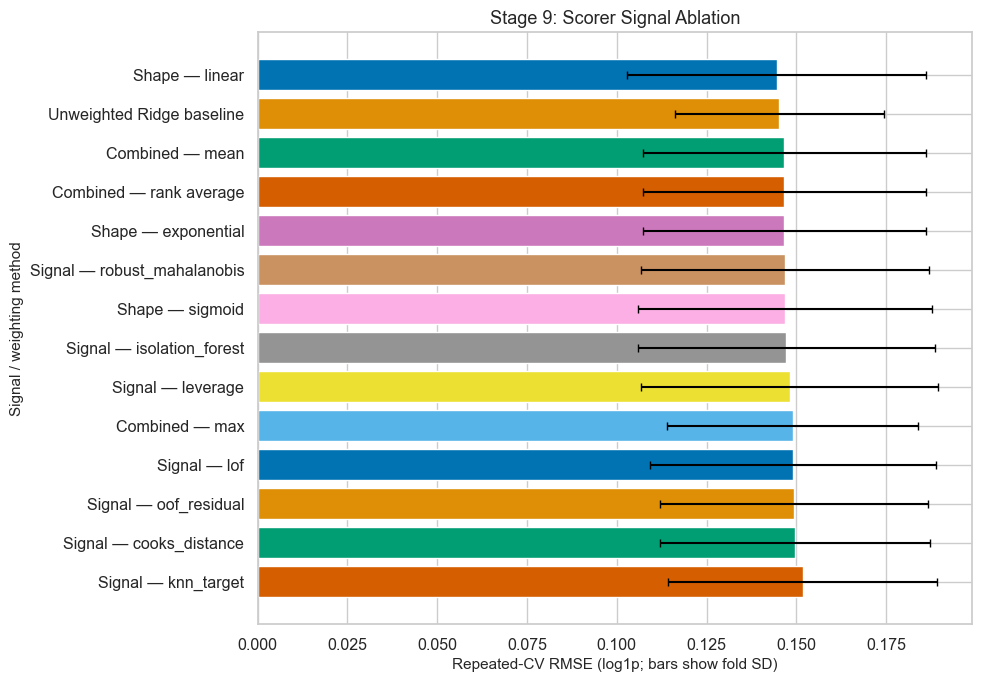

,method,RMSE_log_mean,RMSE_log_sd,MAE_log_mean,P90_log_mean,n_folds
0,Shape — exponential,0.14666,0.03947,0.08742,0.17979,15
1,Shape — linear,0.14451,0.04169,0.08505,0.17185,15
2,Shape — sigmoid,0.14684,0.04096,0.08588,0.17874,15


Saved table: report_assets/tables/table_09_03_weight_shape_cv.csv and report_assets/tables/table_09_03_weight_shape_cv.md
Saved figure: report_assets/figures/fig_09_02_weight_mapping_shapes.png


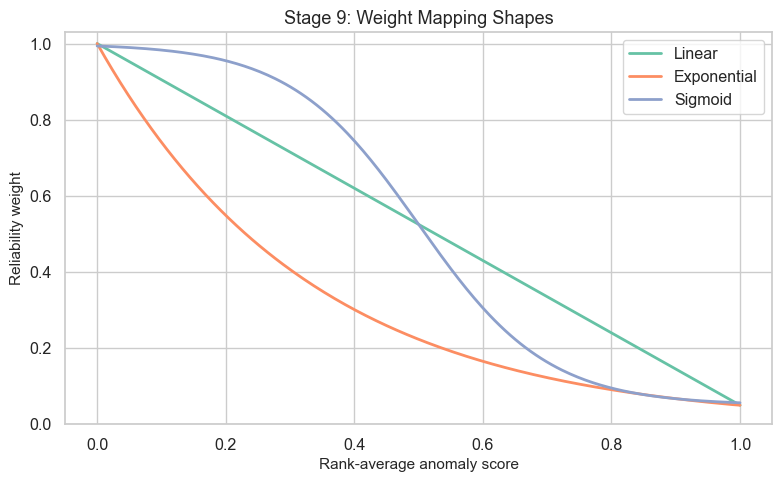

k,0.5,1.0,2.0,3.0,5.0
w_min,,,,,
0.01,0.14449,0.14426,0.14496,0.14666,0.15126
0.05,0.14449,0.14426,0.14496,0.14666,0.15019
0.10,0.14449,0.14426,0.14496,0.14693,0.14793
0.25,0.14449,0.14426,0.14536,0.14569,0.14573


Saved table: report_assets/tables/table_09_04_k_wmin_fold_scores.csv and report_assets/tables/table_09_04_k_wmin_fold_scores.md
Saved table: report_assets/tables/table_09_05_k_wmin_sensitivity.csv and report_assets/tables/table_09_05_k_wmin_sensitivity.md
Saved figure: report_assets/figures/fig_09_03_k_wmin_sensitivity.png


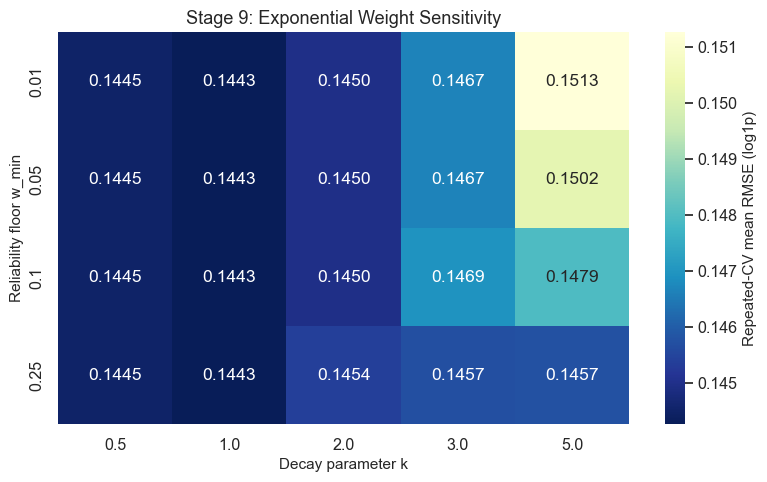

,model,price_segment,n_fold_predictions,mean_sale_price,RMSE_log,MAE_log,P90_log
0,Baseline Ridge,Q1,881,106500.0579,0.1561,0.1087,0.2053
1,Baseline Ridge,Q2,866,145109.9804,0.1789,0.0922,0.1745
2,Baseline Ridge,Q3,882,184951.1451,0.1216,0.0794,0.1595
3,Baseline Ridge,Q4,869,286714.1600,0.1208,0.0864,0.1991
4,Baseline Ridge,nan,6,394950.0000,0.5407,0.4316,0.7828
5,Weighted Ridge,Q1,881,106500.0579,0.1563,0.1060,0.2094
6,Weighted Ridge,Q2,866,145109.9804,0.1893,0.0829,0.1612
7,Weighted Ridge,Q3,882,184951.1451,0.1224,0.0703,0.1437
8,Weighted Ridge,Q4,869,286714.1600,0.1206,0.0879,0.1979
9,Weighted Ridge,nan,6,394950.0000,0.5864,0.4577,0.8395


Saved table: report_assets/tables/table_09_06_error_by_price_segment.csv and report_assets/tables/table_09_06_error_by_price_segment.md
Saved figure: report_assets/figures/fig_09_04_error_by_price_segment.png


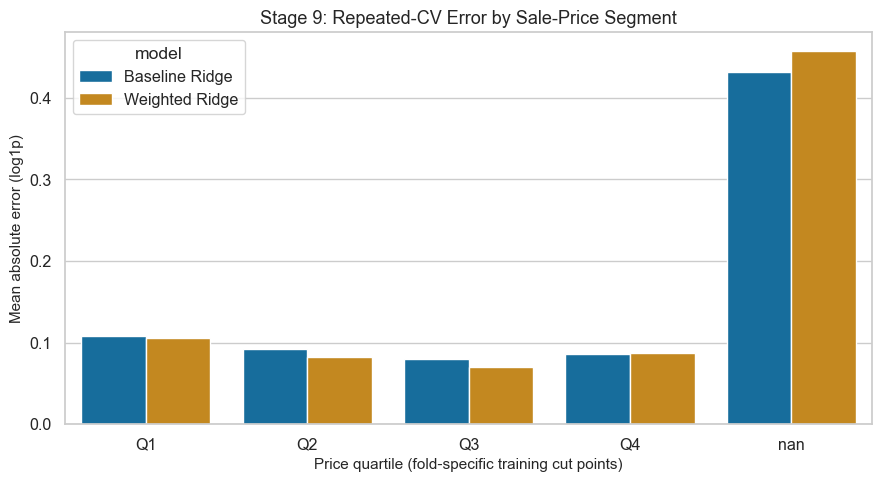

model,feature,Baseline Ridge,Weighted Ridge,weighted_minus_baseline
0,OverallQual,0.03629,0.03748,0.00118
1,GrLivArea,0.02290,0.02432,0.00141
2,YearBuilt,0.00805,0.01657,0.00853
3,Neighborhood,0.01536,0.00535,-0.01002
4,GarageCars,0.01336,0.00798,-0.00538
5,OverallCond,0.01088,0.01260,0.00173
6,1stFlrSF,0.01166,0.01195,0.00029
7,2ndFlrSF,0.01034,0.01184,0.00150
8,TotalBsmtSF,0.00136,0.00772,0.00636
9,BsmtFinType1,0.00597,0.00195,-0.00402


Saved table: report_assets/tables/table_09_07_permutation_importance_fold_scores.csv and report_assets/tables/table_09_07_permutation_importance_fold_scores.md
Saved table: report_assets/tables/table_09_08_permutation_importance_summary.csv and report_assets/tables/table_09_08_permutation_importance_summary.md
Saved table: report_assets/tables/table_09_09_permutation_importance_comparison.csv and report_assets/tables/table_09_09_permutation_importance_comparison.md
Saved figure: report_assets/figures/fig_09_05_permutation_importance.png


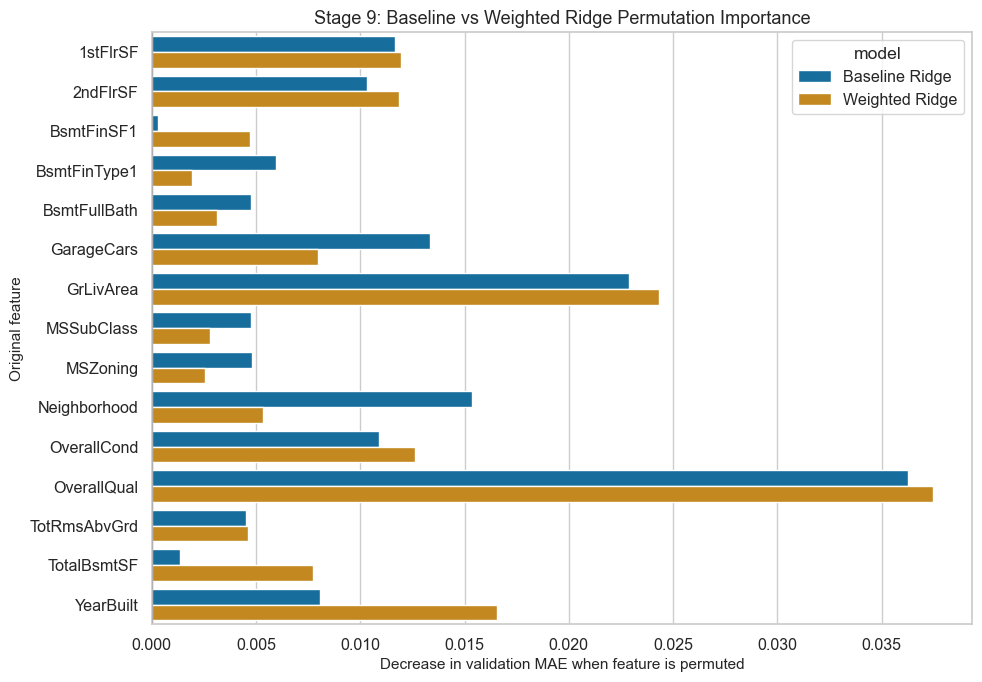

,development_row,SalePrice,influence_score,reliability_weight,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,Neighborhood,LotArea,1stFlrSF
1145,1145,160000.0,0.9932,0.0508,10,5642,2,6110,2008,Edwards,63887,4692
102,102,745000.0,0.9924,0.0509,10,4476,3,2396,1996,NoRidge,15623,2411
456,456,184750.0,0.9796,0.0529,10,4676,3,3138,2007,Edwards,40094,3138
1031,1031,250000.0,0.9761,0.0535,7,2784,2,1392,1978,NWAmes,16692,1392
1075,1075,755000.0,0.9591,0.0563,10,4316,3,2444,1994,NoRidge,21535,2444
484,484,200000.0,0.9547,0.0570,6,3395,0,1440,1914,SWISU,10896,1440
836,836,85000.0,0.9527,0.0574,3,1526,0,1013,1915,IDOTRR,8470,1013
109,109,274970.0,0.9521,0.0575,6,2201,2,697,1966,Edwards,19690,1575
575,575,266500.0,0.9492,0.0580,7,2340,1,1152,1941,Crawfor,9042,1188
310,310,256000.0,0.9474,0.0583,6,2792,2,1510,1920,OldTown,10440,1584


Saved table: report_assets/tables/table_09_10_low_reliability_house_examples.csv and report_assets/tables/table_09_10_low_reliability_house_examples.md


,group,n,mean_score,median_score,precision_at_k,injected_sample_AUROC
0,Natural top-5% candidates (development data),59,0.8974,0.8886,NaN,0.987
1,Injected rows (5% mixed contamination),58,0.9119,0.9154,0.7241,0.987
2,Unchanged rows in injected sample,1110,0.4789,0.4824,NaN,0.987


Saved table: report_assets/tables/table_09_11_natural_vs_injected_scores.csv and report_assets/tables/table_09_11_natural_vs_injected_scores.md
Saved figure: report_assets/figures/fig_09_06_natural_vs_injected_scores.png


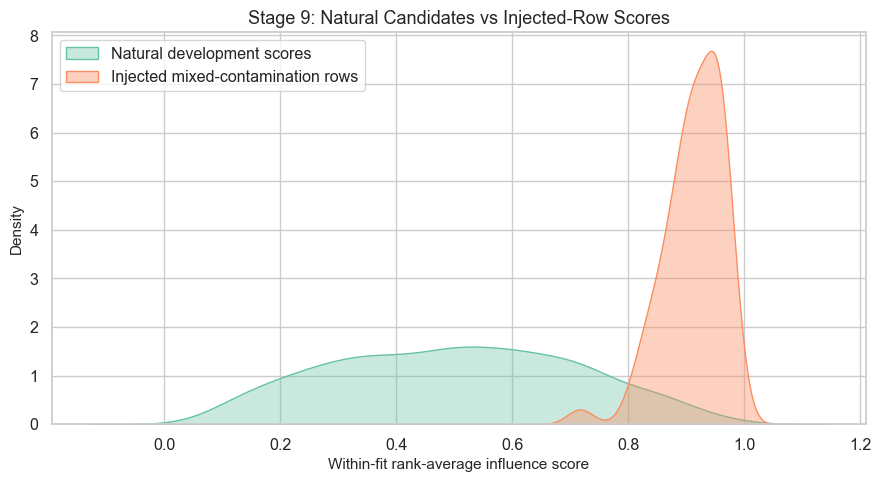

Stage 9 repeated CV completed: 15 outer folds; locked test set unused.
Injected mixed-row detector AUROC on development-only diagnostic: 0.987.


In [33]:
# ── 9.1  Fold-safe scorer ablations and error analysis ──────────────
from sklearn.inspection import permutation_importance

# All model comparisons use the notebook's repeated 5x3 CV on development data.
# Influence scores are recalculated using each outer training fold only.
stage9_fold_rows, stage9_prediction_rows = [], []
stage9_importance_rows, stage9_sensitivity_rows = [], []
stage9_signal_names = list(InfluenceScorer.SIGNALS)
stage9_shapes = ["linear", "exponential", "sigmoid"]
stage9_k_values, stage9_wmin_values = [0.5, 1.0, 2.0, 3.0, 5.0], [0.01, 0.05, 0.10, 0.25]

def _stage9_fit(Xtr, ytr, weights=None):
    est = clone(ridge_model)
    if weights is None:
        return est.fit(Xtr, ytr)
    return _fit_with_sample_weights(est, Xtr, ytr, np.asarray(weights))

def _stage9_record_metrics(records, method, fold, ytrue, pred):
    m = regression_metrics(np.asarray(ytrue), np.asarray(pred))
    records.append({"method": method, "fold": fold, "RMSE_log": m["RMSE_log"],
                    "MAE_log": m["MAE_log"], "MedAE_log": m["MedAE_log"],
                    "P90_log": m["P90_log"]})

for fold, (tr_idx, va_idx) in enumerate(CV.split(X_dev, y_dev), start=1):
    Xtr, Xva = X_dev.iloc[tr_idx].copy(), X_dev.iloc[va_idx].copy()
    ytr, yva = y_dev.iloc[tr_idx].copy(), y_dev.iloc[va_idx].copy()
    fold_scorer = InfluenceScorer(random_state=SEED + fold).fit(Xtr, ytr.to_numpy())
    components = fold_scorer.component_scores_.reset_index(drop=True)
    composites = {
        "Combined — mean": fold_scorer.combine("mean").to_numpy(),
        "Combined — max": fold_scorer.combine("max").to_numpy(),
        "Combined — rank average": fold_scorer.combine("rank_average").to_numpy(),
    }
    fold_models = {}

    # Baseline and individual signal ablations.
    baseline = _stage9_fit(Xtr, ytr)
    fold_models["Unweighted Ridge baseline"] = baseline
    _stage9_record_metrics(stage9_fold_rows, "Unweighted Ridge baseline", fold,
                           yva.to_numpy(), baseline.predict(Xva))
    for signal in stage9_signal_names:
        weights = scores_to_weights(components[signal], "exponential", k=3.0, w_min=0.05)
        est = _stage9_fit(Xtr, ytr, weights)
        label = f"Signal — {signal}"
        fold_models[label] = est
        _stage9_record_metrics(stage9_fold_rows, label, fold, yva.to_numpy(), est.predict(Xva))
    for label, score in composites.items():
        weights = scores_to_weights(score, "exponential", k=3.0, w_min=0.05)
        est = _stage9_fit(Xtr, ytr, weights)
        fold_models[label] = est
        _stage9_record_metrics(stage9_fold_rows, label, fold, yva.to_numpy(), est.predict(Xva))

    # Weight function shape comparison on identical rank-average scores.
    shape_models = {}
    for shape in stage9_shapes:
        if shape == "linear":
            weights = scores_to_weights(composites["Combined — rank average"], shape, w_min=0.05)
        elif shape == "exponential":
            weights = scores_to_weights(composites["Combined — rank average"], shape, k=3.0, w_min=0.05)
        else:
            weights = scores_to_weights(composites["Combined — rank average"], shape,
                                        w_min=0.05, sigmoid_slope=10.0)
        est = _stage9_fit(Xtr, ytr, weights)
        shape_models[shape] = est
        fold_models[f"Shape — {shape}"] = est
        _stage9_record_metrics(stage9_fold_rows, f"Shape — {shape}", fold,
                               yva.to_numpy(), est.predict(Xva))

    # Sensitivity grid: fixed model, folds, scorer combination, and metric.
    rank_score = composites["Combined — rank average"]
    for floor in stage9_wmin_values:
        for decay in stage9_k_values:
            weights = scores_to_weights(rank_score, "exponential", k=decay, w_min=floor)
            est = _stage9_fit(Xtr, ytr, weights)
            m = regression_metrics(yva.to_numpy(), est.predict(Xva))
            stage9_sensitivity_rows.append({
                "fold": fold, "k": decay, "w_min": floor, "RMSE_log": m["RMSE_log"],
                "MAE_log": m["MAE_log"], "P90_log": m["P90_log"],
                "mean_weight": float(weights.mean()),
                "fraction_at_floor": float(np.isclose(weights, floor, atol=1e-8).mean())
            })

    # Store clean validation predictions for matched price-segment error analysis.
    for model_label, est in [("Baseline Ridge", baseline),
                             ("Weighted Ridge", shape_models["exponential"])]:
        pred = est.predict(Xva)
        train_price = np.expm1(ytr.to_numpy())
        val_price = np.expm1(yva.to_numpy())
        edges = np.unique(np.quantile(train_price, [0, .25, .50, .75, 1.0]))
        edges[0] = -np.inf
        edges[-1] = np.inf
        segments = [f"Q{i+1}" for i in range(len(edges)-1)]
        val_segments = pd.cut(val_price, bins=edges, labels=segments, include_lowest=True)
        for pos, (row_idx, actual, estimate, segment) in enumerate(
                zip(Xva.index, yva.to_numpy(), pred, val_segments)):
            stage9_prediction_rows.append({
                "fold": fold, "development_row": row_idx, "model": model_label,
                "price_segment": str(segment), "y_true": float(actual),
                "y_pred": float(estimate), "abs_error": float(abs(actual-estimate))
            })

    # Permutation importance on clean outer validation rows for matched Ridge models.
    for model_label, est in [("Baseline Ridge", baseline),
                             ("Weighted Ridge", shape_models["exponential"])]:
        perm = permutation_importance(
            est, Xva, yva, scoring="neg_mean_absolute_error",
            n_repeats=3, random_state=SEED + fold, n_jobs=-1
        )
        for feature, imp_mean, imp_sd in zip(Xva.columns, perm.importances_mean,
                                              perm.importances_std):
            stage9_importance_rows.append({
                "fold": fold, "model": model_label, "feature": feature,
                "importance_mean": float(imp_mean), "importance_sd": float(imp_sd)
            })
    if fold in (5, 10, 15):
        print(f"Stage 9 repeated CV: completed outer fold {fold}/15.")

# Fold-level ablation summary and plot with standard deviation across the 15 folds.
stage9_fold_ablation = pd.DataFrame(stage9_fold_rows)
stage9_ablation = (stage9_fold_ablation.groupby("method", as_index=False)
    .agg(**{f"{m}_mean": (m, "mean") for m in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log"]},
         **{f"{m}_sd": (m, "std") for m in ["RMSE_log", "MAE_log", "MedAE_log", "P90_log"]},
         n_folds=("fold", "nunique")).sort_values("RMSE_log_mean"))
display(stage9_ablation.round(5))
save_table(stage9_fold_ablation, "table_09_01_signal_ablation_fold_scores")
save_table(stage9_ablation, "table_09_02_signal_ablation_summary")
fig, ax = plt.subplots(figsize=(10, 7))
plot_df = stage9_ablation.sort_values("RMSE_log_mean")
ax.barh(plot_df["method"], plot_df["RMSE_log_mean"], xerr=plot_df["RMSE_log_sd"],
        capsize=3, color=sns.color_palette("colorblind", n_colors=len(plot_df)))
ax.invert_yaxis()
ax.set(xlabel="Repeated-CV RMSE (log1p; bars show fold SD)", ylabel="Signal / weighting method",
       title="Stage 9: Scorer Signal Ablation")
save_fig("fig_09_01_signal_ablation.png")
plt.show()

# Mapping comparison, with fold-level dispersion.
stage9_shape_fold = stage9_fold_ablation[
    stage9_fold_ablation["method"].isin([f"Shape — {x}" for x in stage9_shapes])].copy()
stage9_shape_summary = (stage9_shape_fold.groupby("method", as_index=False)
    .agg(RMSE_log_mean=("RMSE_log", "mean"), RMSE_log_sd=("RMSE_log", "std"),
         MAE_log_mean=("MAE_log", "mean"), P90_log_mean=("P90_log", "mean"),
         n_folds=("fold", "nunique")))
display(stage9_shape_summary.round(5))
save_table(stage9_shape_summary, "table_09_03_weight_shape_cv")
fig, ax = plt.subplots(figsize=(8, 5))
score_grid = np.linspace(0, 1, 250)
for shape in stage9_shapes:
    if shape == "linear":
        curve = scores_to_weights(score_grid, shape, w_min=0.05)
    elif shape == "exponential":
        curve = scores_to_weights(score_grid, shape, k=3.0, w_min=0.05)
    else:
        curve = scores_to_weights(score_grid, shape, w_min=0.05, sigmoid_slope=10.0)
    ax.plot(score_grid, curve, label=shape.title(), linewidth=2)
ax.set(xlabel="Rank-average anomaly score", ylabel="Reliability weight",
       title="Stage 9: Weight Mapping Shapes", ylim=(0, 1.03))
ax.legend()
save_fig("fig_09_02_weight_mapping_shapes.png")
plt.show()

# Aggregate sensitivity results across the same 15 outer folds.
stage9_sensitivity_fold = pd.DataFrame(stage9_sensitivity_rows)
stage9_sensitivity = (stage9_sensitivity_fold.groupby(["k", "w_min"], as_index=False)
    .agg(RMSE_log_mean=("RMSE_log", "mean"), RMSE_log_sd=("RMSE_log", "std"),
         MAE_log_mean=("MAE_log", "mean"), P90_log_mean=("P90_log", "mean"),
         mean_weight=("mean_weight", "mean"), fraction_at_floor=("fraction_at_floor", "mean")))
display(stage9_sensitivity.pivot(index="w_min", columns="k", values="RMSE_log_mean").round(5))
save_table(stage9_sensitivity_fold, "table_09_04_k_wmin_fold_scores")
save_table(stage9_sensitivity, "table_09_05_k_wmin_sensitivity")
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(stage9_sensitivity.pivot(index="w_min", columns="k", values="RMSE_log_mean"),
            annot=True, fmt=".4f", cmap="YlGnBu_r",
            cbar_kws={"label": "Repeated-CV mean RMSE (log1p)"}, ax=ax)
ax.set(title="Stage 9: Exponential Weight Sensitivity", xlabel="Decay parameter k",
       ylabel="Reliability floor w_min")
save_fig("fig_09_03_k_wmin_sensitivity.png")
plt.show()

# Clean validation errors by price segments; quartile boundaries are learned within each training fold.
stage9_predictions = pd.DataFrame(stage9_prediction_rows)
stage9_price_rows = []
for (model_name, segment), group in stage9_predictions.groupby(["model", "price_segment"]):
    residual = group["y_true"].to_numpy() - group["y_pred"].to_numpy()
    stage9_price_rows.append({
        "model": model_name, "price_segment": segment, "n_fold_predictions": len(group),
        "mean_sale_price": float(np.expm1(group["y_true"]).mean()),
        "RMSE_log": float(np.sqrt(np.mean(residual**2))),
        "MAE_log": float(group["abs_error"].mean()),
        "P90_log": float(group["abs_error"].quantile(.90))
    })
stage9_price_errors = pd.DataFrame(stage9_price_rows)
display(stage9_price_errors.round(4))
save_table(stage9_price_errors, "table_09_06_error_by_price_segment")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=stage9_price_errors, x="price_segment", y="MAE_log",
            hue="model", palette="colorblind", ax=ax)
ax.set(title="Stage 9: Repeated-CV Error by Sale-Price Segment",
       xlabel="Price quartile (fold-specific training cut points)", ylabel="Mean absolute error (log1p)")
save_fig("fig_09_04_error_by_price_segment.png")
plt.show()

# Compare average fold-wise permutation importance on untouched validation folds.
stage9_importance_fold = pd.DataFrame(stage9_importance_rows)
stage9_importance_summary = (stage9_importance_fold.groupby(["model", "feature"], as_index=False)
    .agg(importance_mean=("importance_mean", "mean"), importance_sd_across_folds=("importance_mean", "std"),
         permutation_sd_mean=("importance_sd", "mean")))
importance_wide = stage9_importance_summary.pivot(index="feature", columns="model",
                                                  values="importance_mean").fillna(0)
importance_wide["weighted_minus_baseline"] = importance_wide["Weighted Ridge"] - importance_wide["Baseline Ridge"]
importance_wide["sort_key"] = importance_wide[["Weighted Ridge", "Baseline Ridge"]].abs().max(axis=1)
importance_top = (importance_wide.sort_values("sort_key", ascending=False).head(15)
                  .drop(columns="sort_key").reset_index())
display(importance_top.round(5))
save_table(stage9_importance_fold, "table_09_07_permutation_importance_fold_scores")
save_table(stage9_importance_summary, "table_09_08_permutation_importance_summary")
save_table(importance_top, "table_09_09_permutation_importance_comparison")
importance_plot = stage9_importance_summary[
    stage9_importance_summary["feature"].isin(importance_top["feature"])]
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=importance_plot, y="feature", x="importance_mean",
            hue="model", palette="colorblind", ax=ax)
ax.axvline(0, color="black", linewidth=.8)
ax.set(title="Stage 9: Baseline vs Weighted Ridge Permutation Importance",
       xlabel="Decrease in validation MAE when feature is permuted", ylabel="Original feature")
save_fig("fig_09_05_permutation_importance.png")
plt.show()

# Descriptive examples: fit a fresh scorer to development rows only. This full-dev
# diagnostic is not used in the repeated-CV comparisons or any model selection.
stage9_dev_scorer = InfluenceScorer(random_state=SEED).fit(X_dev, y_dev.to_numpy())
dev_score = stage9_dev_scorer.combine("rank_average").to_numpy()
dev_weights = scores_to_weights(dev_score, "exponential", k=3.0, w_min=0.05)
example_df = X_dev.copy()
example_df.insert(0, "development_row", X_dev.index.to_numpy())
example_df["SalePrice"] = np.expm1(y_dev.to_numpy())
example_df["influence_score"] = dev_score
example_df["reliability_weight"] = dev_weights
example_features = [c for c in ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF",
    "YearBuilt", "Neighborhood", "LotArea", "1stFlrSF"] if c in example_df.columns]
stage9_low_reliability = (example_df.sort_values("reliability_weight")
    [["development_row", "SalePrice", "influence_score", "reliability_weight"]
     + example_features].head(15))
display(stage9_low_reliability.round(4))
save_table(stage9_low_reliability, "table_09_10_low_reliability_house_examples")

# Contrast natural high-score candidates with controlled mixed injected rows.
natural_k = max(1, int(np.ceil(.05 * len(dev_score))))
natural_idx = np.argsort(dev_score)[-natural_k:]
natural_mask = np.zeros(len(X_dev), dtype=bool)
natural_mask[natural_idx] = True
X9_injected, y9_injected, injected_mask = inject_training_contamination(
    X_dev, y_dev, contamination_pct=5, contamination_type="mixed", seed=SEED + 900)
injected_scorer = InfluenceScorer(random_state=SEED + 901).fit(X9_injected, y9_injected)
injected_score = injected_scorer.combine("rank_average").to_numpy()
injected_k = max(1, int(injected_mask.sum()))
injected_top_idx = np.argsort(injected_score)[-injected_k:]
stage9_natural_injected = pd.DataFrame([
    {"group": "Natural top-5% candidates (development data)", "n": int(natural_mask.sum()),
     "mean_score": float(dev_score[natural_mask].mean()), "median_score": float(np.median(dev_score[natural_mask])),
     "precision_at_k": np.nan},
    {"group": "Injected rows (5% mixed contamination)", "n": int(injected_mask.sum()),
     "mean_score": float(injected_score[injected_mask].mean()), "median_score": float(np.median(injected_score[injected_mask])),
     "precision_at_k": float(injected_mask[injected_top_idx].mean())},
    {"group": "Unchanged rows in injected sample", "n": int((~injected_mask).sum()),
     "mean_score": float(injected_score[~injected_mask].mean()), "median_score": float(np.median(injected_score[~injected_mask])),
     "precision_at_k": np.nan}
])
stage9_injected_auc = roc_auc_score(injected_mask.astype(int), injected_score)
stage9_natural_injected["injected_sample_AUROC"] = stage9_injected_auc
display(stage9_natural_injected.round(4))
save_table(stage9_natural_injected, "table_09_11_natural_vs_injected_scores")
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(dev_score, fill=True, alpha=.35, label="Natural development scores", ax=ax)
sns.kdeplot(injected_score[injected_mask], fill=True, alpha=.4,
            label="Injected mixed-contamination rows", ax=ax)
ax.set(title="Stage 9: Natural Candidates vs Injected-Row Scores",
       xlabel="Within-fit rank-average influence score", ylabel="Density")
ax.legend()
save_fig("fig_09_06_natural_vs_injected_scores.png")
plt.show()

print(f"Stage 9 repeated CV completed: {CV.get_n_splits()} outer folds; locked test set unused.")
print(f"Injected mixed-row detector AUROC on development-only diagnostic: {stage9_injected_auc:.3f}.")


### 9.2  Price-segment boundary correction

Validation houses can fall outside the minimum and maximum prices observed in a particular training fold. This quick post-processing cell assigns those cases to the outer price quartiles, then refreshes the table and figure without refitting any models. The cut points still come only from each corresponding training fold.


,model,price_segment,n_fold_predictions,mean_sale_price,RMSE_log,MAE_log,P90_log
0,Baseline Ridge,Q1,884,106257.0713,0.1619,0.1109,0.2079
1,Baseline Ridge,Q2,866,145109.9804,0.1789,0.0922,0.1745
2,Baseline Ridge,Q3,882,184951.1451,0.1216,0.0794,0.1595
3,Baseline Ridge,Q4,872,288325.2351,0.1209,0.0865,0.1991
4,Weighted Ridge,Q1,884,106257.0713,0.1632,0.1084,0.2102
5,Weighted Ridge,Q2,866,145109.9804,0.1893,0.0829,0.1612
6,Weighted Ridge,Q3,882,184951.1451,0.1224,0.0703,0.1437
7,Weighted Ridge,Q4,872,288325.2351,0.1206,0.0879,0.1976


Saved table: report_assets/tables/table_09_06_error_by_price_segment.csv and report_assets/tables/table_09_06_error_by_price_segment.md
Saved figure: report_assets/figures/fig_09_04_error_by_price_segment.png


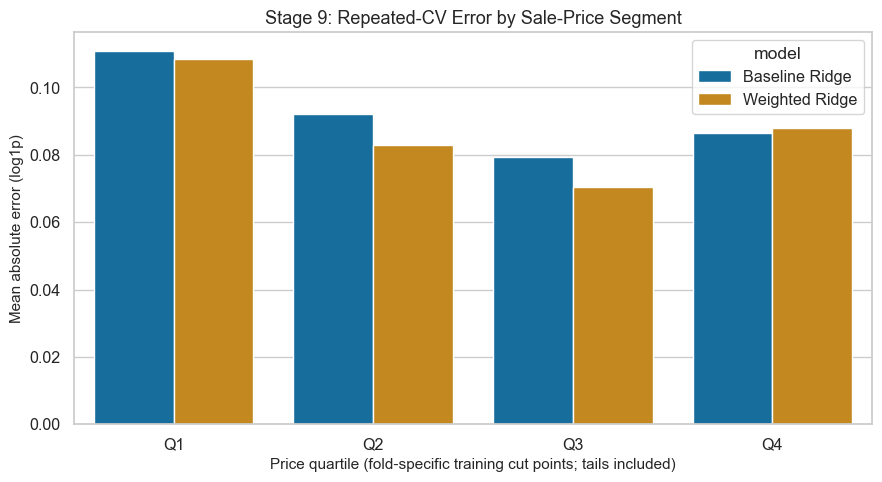

Unassigned validation prices: 0


In [35]:
# Correct price-segment assignment for validation prices outside training-fold extrema.
# Reuses saved repeated-CV predictions; no scorer/model refitting or test access.
_fixed_segment = pd.Series(index=stage9_predictions.index, dtype=object)
for _fold, (_tr, _va) in enumerate(CV.split(X_dev, y_dev), start=1):
    _train_price = np.expm1(y_dev.iloc[_tr].to_numpy())
    _edges = np.unique(np.quantile(_train_price, [0, .25, .50, .75, 1.0]))
    _edges[0], _edges[-1] = -np.inf, np.inf
    _labels = [f"Q{i+1}" for i in range(len(_edges)-1)]
    _rows = stage9_predictions[stage9_predictions["fold"] == _fold]
    _price = np.expm1(_rows["y_true"].to_numpy())
    _fixed_segment.loc[_rows.index] = pd.cut(
        _price, bins=_edges, labels=_labels, include_lowest=True).astype(str)
stage9_predictions["price_segment"] = _fixed_segment

_segment_rows = []
for (_model, _segment), _group in stage9_predictions.groupby(["model", "price_segment"]):
    _resid = _group["y_true"].to_numpy() - _group["y_pred"].to_numpy()
    _segment_rows.append({
        "model": _model, "price_segment": _segment,
        "n_fold_predictions": len(_group),
        "mean_sale_price": float(np.expm1(_group["y_true"]).mean()),
        "RMSE_log": float(np.sqrt(np.mean(_resid**2))),
        "MAE_log": float(_group["abs_error"].mean()),
        "P90_log": float(_group["abs_error"].quantile(.90))
    })
stage9_price_errors = pd.DataFrame(_segment_rows)
display(stage9_price_errors.round(4))
save_table(stage9_price_errors, "table_09_06_error_by_price_segment")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=stage9_price_errors, x="price_segment", y="MAE_log",
            hue="model", palette="colorblind", ax=ax)
ax.set(title="Stage 9: Repeated-CV Error by Sale-Price Segment",
       xlabel="Price quartile (fold-specific training cut points; tails included)",
       ylabel="Mean absolute error (log1p)")
save_fig("fig_09_04_error_by_price_segment.png")
plt.show()
print("Unassigned validation prices:", int(stage9_predictions["price_segment"].isna().sum()))


### Stage 9 — Observations & Inferences

Across the repeated 5×3 cross-validation ablation, linear reliability weighting produced the lowest mean RMSE among the reported configurations (0.14451), compared with 0.14519 for unweighted Ridge. It also reduced mean MAE from 0.09229 to 0.08505 and P90 absolute error from 0.18443 to 0.17185. These gains were not accompanied by lower fold variability: the RMSE standard deviation was 0.04169 for linear weighting and 0.02908 for the unweighted baseline. The combined mean and rank-average scores, evaluated with exponential decay at k=3 and w_min=0.05, had RMSE 0.14666; sigmoid weighting had RMSE 0.14684, while max aggregation had RMSE 0.14902. No individual influence signal alone improved mean RMSE over the baseline; kNN target inconsistency had the highest RMSE at 0.15172. The results therefore indicate that performance depends on the score combination and weight mapping rather than improving uniformly through influence weighting.

The weight sensitivity grid had its lowest mean RMSE, 0.14426, at k=1.0 with either w_min=0.01 or 0.05. Higher decay generally performed less well in this grid, with k=5 and w_min=0.01 yielding RMSE 0.15126. Several floor settings produced identical results at lower k because the calculated exponential weights did not reach the specified floor. These point estimates describe this development-set CV experiment; the ablation did not include paired significance tests, and the comparatively large fold standard deviations mean that small differences should not be treated as reliable gains.

Price-segment errors showed metric-specific changes. Weighted Ridge reduced MAE and P90 in Q2 (MAE 0.0922 to 0.0829; P90 0.1745 to 0.1612) and Q3 (MAE 0.0794 to 0.0703; P90 0.1595 to 0.1437). In Q1, MAE improved slightly (0.1109 to 0.1084), while RMSE and P90 increased (0.1619 to 0.1632 and 0.2079 to 0.2102). In Q4, MAE increased slightly (0.0865 to 0.0879), while RMSE and P90 changed little (0.1209 to 0.1206 and 0.1991 to 0.1976). Thus, weighting improved typical and tail errors in the middle price bands but did not improve every segment or metric. Price bands use fold-specific training cut points, with observations beyond the training range retained in the outer bands.

The lowest-reliability examples included unusually large homes with comparatively modest sale prices, as well as expensive, high-quality homes, including examples priced around $745,000 and $755,000. The flagged records therefore cannot be interpreted as erroneous solely because they receive low weights; rarity or unusual feature combinations may describe legitimate houses. This is consistent with the intended interpretation of reliability as an influence diagnostic rather than a data-validity label.

Permutation importance retained OverallQual and GrLivArea as the leading predictors for both Ridge models (OverallQual: 0.03629 baseline and 0.03748 weighted; GrLivArea: 0.02290 and 0.02432). Weighted Ridge assigned greater importance to YearBuilt (0.01657 versus 0.00805) and TotalBsmtSF (0.00772 versus 0.00136), and lower importance to Neighborhood (0.00535 versus 0.01536) and GarageCars (0.00798 versus 0.01336). These are descriptive changes in fold-averaged permutation importance, not causal effects.

For the development-only 5% mixed-contamination diagnostic, injected rows achieved AUROC 0.987 and precision@k 0.7241; their mean score was 0.9119, compared with 0.4789 for unchanged rows. Naturally high-scoring development observations also had high scores (top-5% mean 0.8974). Since the natural and injected scores came from separately fitted scorers, their absolute magnitudes are not directly calibrated against each other. The detector result supports identifying the particular synthetic mixed corruption tested, but it does not by itself show that weighting improves predictive robustness for every contamination type.

With respect to H1–H3, Stage 9 provides qualified, non-uniform evidence for H1 (accuracy): linear weighting improved the mean point estimates, whereas other combinations and shapes did not, and the fold variability prevents a strong conclusion from this ablation alone. H2 (contamination robustness) is supported for detection of the injected mixed rows, but Stage 9 does not establish a universal downstream accuracy benefit. H3 (fold stability) is not supported by the linear-weighting ablation, whose RMSE fold standard deviation exceeded that of unweighted Ridge. These conclusions are limited to the Ames Housing dataset and the specified synthetic corruption procedure; replication on additional datasets and contamination mechanisms would be required to establish broader generality.

---
## Stage 10 — Conclusions and Report Synthesis

### Direct answer to the research question

Explicitly modelling observation influence can help in some settings, but the evidence does not show a consistent advantage over standard regression or conventional outlier handling. In the frozen hold-out comparison, the preselected weighted Gradient Boosting model achieved RMSE 0.12376, compared with 0.13043 for the no-handling HistGBDT baseline, a 5.12% point reduction. However, the paired repeated-CV strategy comparisons did not survive Holm correction, the bootstrap test intervals overlap, and Stage 9 found that the value of weighting depended on the score signal, weight map, error metric, and price segment. The most defensible conclusion is conditional promise rather than general superiority.

### Best-method summary

The summary below reports the principal development-CV and frozen hold-out results. Hold-out ranks are descriptive only; no method or configuration was selected after examining test results.

| Method | Selection view | CV RMSE (SD) | Test RMSE (95% bootstrap CI) | Interpretation |
|---|---|---:|---:|---|
| Hard removal — HistGBDT | Lowest mean development-CV RMSE | 0.13947 (0.01501) | 0.12070 ([0.10208, 0.14203]) | CV leader; paired Holm comparison not significant. |
| No handling — HistGBDT | No-handling reference | 0.14008 (0.01455) | 0.13043 ([0.10662, 0.15307]) | Strong standard tree baseline. |
| Weighted — Gradient Boosting | Preselected weighted strategy | 0.14268 (0.01453) | 0.12376 ([0.10754, 0.13958]) | 5.12% lower test RMSE point estimate than no-handling HistGBDT; CIs overlap. |
| Hard removal — Ridge | Lowest one-time test RMSE (descriptive) | 0.14502 (0.04324) | 0.11350 ([0.09838, 0.12842]) | Post-hoc test point-estimate leader; not selected using test results. |
| Weighted — Ridge (tuned exponential) | Weighted linear-model comparison | 0.14416 (0.03465) | 0.11859 ([0.10190, 0.13589]) | Small CV point-estimate gain; relatively high fold variability. |

### When explicit outlier modelling helps—and when it does not

The approach appears most useful when training observations are demonstrably corrupted or have unusual feature combinations that also make their target inconsistent with neighboring observations. Stage 8 showed strong detection of injected leverage and mixed contamination, while target-only noise was harder to identify. Linear weighting gave the best Stage 9 ablation point estimates for Ridge and lowered MAE/P90 in the middle price bands. These findings suggest that soft reliability weights can be useful when the influence signal aligns with the source of corruption and the evaluation objective values typical or tail errors.

The approach did not help uniformly. Several combined or individual signals worsened average RMSE relative to unweighted Ridge, stronger exponential decay degraded performance in the sensitivity grid, and Stage 9 fold variability for linear weighting exceeded that of the baseline. Low reliability also included rare but plausible expensive homes. Robust losses and weights cannot be assumed to protect every model or every price segment, and a detector’s ability to flag synthetic rows does not itself establish improved predictions.

### Limitations

The analysis uses one Ames Housing dataset and one stratified hold-out split with approximately 290 test observations. The hold-out bootstrap intervals therefore have limited precision, particularly for rare houses and upper-price tails. Repeated-CV folds share observations and training data, so fold-to-fold standard deviations are descriptive and the paired tests should not be interpreted as if all folds were independent. Stage 8 used two contamination repeats and a small set of specified synthetic corruption mechanisms; its repeat variability is coarse and the results may not represent real-world data errors. Outlier scores are proxies for influence, not verified data-quality labels. Stage 9 permutation importance and price-segment comparisons are descriptive diagnostics. Finally, HuberRegressor showed a severe CV-to-test performance gap (test RMSE 1.97891 versus CV RMSE 0.15528), demonstrating that some fitted strategies were not stable on the locked test sample.

### Future work

Future studies should replicate the protocol on additional tabular regression datasets and larger or temporal hold-outs; evaluate more realistic, independently repeated contamination mechanisms; distinguish feature anomalies from target corruption; calibrate reliability scores against verified data-quality labels; and quantify the effect of weighting on protected or rare subgroups. They should also investigate fold-stable weighting functions, nested parameter selection, model-specific influence measures, and uncertainty-aware decisions about when to down-weight rather than remove observations.

### Validation protocol and threats to validity

The Ames Housing records were divided once into an 80% development set (1,168 observations) and a 20% locked hold-out test set (292 observations), stratified by quantile bins of log1p(SalePrice) with random seed 42. Development-set model comparison used repeated 5-fold cross-validation with three repeats (15 outer folds). Hyperparameter selection and gradient-boosting early stopping used a 15% inner validation split drawn only from the corresponding outer training fold. Influence scores, preprocessing, removal rules, clipping limits, and training weights were estimated from training data only; outer validation folds were left clean. In Stage 8, synthetic contamination affected the outer training data only, while outer validation and the locked test set remained clean; the inner early-stopping subset was drawn after contamination and could contain corrupted cases.

The locked test set was not used for EDA, scoring, tuning, filtering, weighting, or model selection. After the development comparisons and configurations were frozen, each strategy was evaluated on the test set once, with bootstrap 95% intervals based on 1,000 resamples. The test size of 292 is modest for estimating tail performance, comparing many strategies, or evaluating rare/high-price houses; bootstrap intervals quantify resampling uncertainty within this one split but do not capture uncertainty from choosing another split, dataset, or time period. Overlapping repeated-CV training sets and a single dataset further limit generalization. Any test-set ranking is therefore descriptive and must not be used to revise the frozen configurations.

In [ ]:
# ── 10.1  Compact summary of selected methods and frozen test results ─
stage10_summary = pd.DataFrame([
    {"method": "Hard removal — HistGBDT",
     "selection_view": "Lowest mean development-CV RMSE",
     "CV_RMSE_log": 0.139475, "CV_RMSE_SD": 0.015009,
     "test_RMSE_log": 0.120701, "test_RMSE_CI_95": "[0.10208, 0.14203]",
     "interpretation": "CV leader; paired Holm comparison was not significant."},
    {"method": "No handling — HistGBDT",
     "selection_view": "Strong no-handling reference",
     "CV_RMSE_log": 0.140085, "CV_RMSE_SD": 0.014545,
     "test_RMSE_log": 0.130434, "test_RMSE_CI_95": "[0.10662, 0.15307]",
     "interpretation": "No-handling tree baseline."},
    {"method": "Weighted — Gradient Boosting",
     "selection_view": "Preselected weighted strategy",
     "CV_RMSE_log": 0.142683, "CV_RMSE_SD": 0.014532,
     "test_RMSE_log": 0.123756, "test_RMSE_CI_95": "[0.10754, 0.13958]",
     "interpretation": "Test RMSE was 5.12% below the no-handling HistGBDT point estimate; test intervals overlap."},
    {"method": "Hard removal — Ridge",
     "selection_view": "Lowest one-time test RMSE (descriptive)",
     "CV_RMSE_log": 0.145021, "CV_RMSE_SD": 0.043240,
     "test_RMSE_log": 0.113500, "test_RMSE_CI_95": "[0.09838, 0.12842]",
     "interpretation": "Post-hoc test point-estimate leader; not selected using test results."},
    {"method": "Weighted — Ridge (tuned exponential)",
     "selection_view": "Weighted linear-model reference",
     "CV_RMSE_log": 0.144163, "CV_RMSE_SD": 0.034653,
     "test_RMSE_log": 0.118590, "test_RMSE_CI_95": "[0.10190, 0.13589]",
     "interpretation": "Improved over its Ridge CV reference by a small point estimate; high fold variability."},
])
display(stage10_summary)
save_table(stage10_summary, "table_10_01_best_method_summary")

# Project-level hypothesis status, stated with the evidence limits retained.
stage10_hypotheses = pd.DataFrame([
    {"hypothesis": "H1 — Accuracy",
     "status": "Supported by the prespecified hold-out point-estimate criterion; not conclusive",
     "evidence": "Preselected weighted Gradient Boosting test RMSE 0.12376 vs no-handling HistGBDT 0.13043 (5.12% reduction); Stage 7 Holm-adjusted CV comparisons were not significant and test CIs overlap."},
    {"hypothesis": "H2 — Contamination robustness",
     "status": "Partially supported",
     "evidence": "Stage 8 detection was strong for leverage/mixed injections, weaker for target noise; degradation behavior varied by method and corruption type."},
    {"hypothesis": "H3 — Fold stability",
     "status": "Partially supported overall; not supported by the Stage 9 linear-weighting ablation",
     "evidence": "Stage 7 summary reported only a 1.2% weighted-vs-baseline SD reduction, below its 20% criterion; Stage 9 linear-weighted Ridge RMSE SD was 0.04169 vs baseline 0.02908."},
])
display(stage10_hypotheses)
save_table(stage10_hypotheses, "table_10_02_final_hypothesis_status")


## Key Findings

1. **The best mean development-CV RMSE was obtained by hard-removal HistGBDT (0.13948 ± 0.01501), narrowly ahead of no-handling HistGBDT (0.14009 ± 0.01455); paired comparisons did not survive Holm correction.** [Table 07.01](report_assets/tables/table_07_01_paired_cv_ranked_comparison.csv)

2. **The preselected weighted Gradient Boosting strategy had a lower hold-out RMSE point estimate than no-handling HistGBDT (0.12376 vs 0.13043), a 5.12% reduction, but the bootstrap intervals overlapped.** [Table 07.05](report_assets/tables/table_07_05_one_time_holdout_results.csv)

3. **Stage 9’s linear-weighted Ridge achieved modestly lower CV RMSE, MAE, and P90 than unweighted Ridge, but it had higher fold RMSE variability; other scoring/aggregation choices were not uniformly better.** [Table 09.02](report_assets/tables/table_09_02_signal_ablation_summary.csv), [Figure 09.01](report_assets/figures/fig_09_01_signal_ablation.png)

4. **Greater exponential decay was not consistently helpful: the sensitivity grid’s best mean RMSE was 0.14426 at k=1, while k=5 produced 0.15126 at w_min=0.01.** [Table 09.05](report_assets/tables/table_09_05_k_wmin_sensitivity.csv), [Figure 09.03](report_assets/figures/fig_09_03_k_wmin_sensitivity.png)

5. **The influence scorer detected injected leverage/mixed rows more reliably than target-only corruption; for one 5% mixed injection diagnostic, AUROC was 0.987 and precision@k was 0.724.** [Table 08.04](report_assets/tables/table_08_04_injected_row_detection_summary.csv), [Table 09.11](report_assets/tables/table_09_11_natural_vs_injected_scores.csv)

6. **In the corrected price-segment analysis, weighting reduced MAE and P90 in Q2–Q3, but its effects were mixed in Q1 and Q4.** [Table 09.06](report_assets/tables/table_09_06_error_by_price_segment.csv), [Figure 09.04](report_assets/figures/fig_09_04_error_by_price_segment.png)

7. **Low-reliability flags included both unusual large/modestly priced homes and expensive, high-quality homes, so anomaly scores should not be equated with invalid records.** [Table 09.10](report_assets/tables/table_09_10_low_reliability_house_examples.csv)

8. **The one-time test results included a severe HuberRegressor CV-to-test gap (0.15528 CV RMSE vs 1.97891 test RMSE), underscoring the risk of relying on a single split or assuming robust losses always generalize.** [Table 07.05](report_assets/tables/table_07_05_one_time_holdout_results.csv)

## Report Assets Index

The index lists the figure and table assets currently saved under `./report_assets/`. Table rows identify all available saved formats. Captions are concise descriptions derived from the numbered asset names.

| Type | Saved asset(s) | Format(s) | One-line caption |
|---|---|---|---|
| Figure | report_assets/figures/fig_02_01_stratification_check.png | PNG | Stage 02, figure 01: Stratification check. |
| Figure | report_assets/figures/fig_02_02_target_distribution.png | PNG | Stage 02, figure 02: Target distribution. |
| Figure | report_assets/figures/fig_02_03_missingness.png | PNG | Stage 02, figure 03: Missingness. |
| Figure | report_assets/figures/fig_02_04_top_correlations.png | PNG | Stage 02, figure 04: Top correlations. |
| Figure | report_assets/figures/fig_02_05_correlation_heatmap.png | PNG | Stage 02, figure 05: Correlation heatmap. |
| Figure | report_assets/figures/fig_02_06_grliv_vs_saleprice.png | PNG | Stage 02, figure 06: Grliv vs saleprice. |
| Figure | report_assets/figures/fig_02_07_boxplots_numeric.png | PNG | Stage 02, figure 07: Boxplots numeric. |
| Figure | report_assets/figures/fig_02_08_leverage_cooks.png | PNG | Stage 02, figure 08: Leverage cooks. |
| Figure | report_assets/figures/fig_02_09_feature_scatter_panels.png | PNG | Stage 02, figure 09: Feature scatter panels. |
| Figure | report_assets/figures/fig_03_01_baseline_cv_comparison.png | PNG | Stage 03, figure 01: Baseline cv comparison. |
| Figure | report_assets/figures/fig_03_02_baseline_residuals.png | PNG | Stage 03, figure 02: Baseline residuals. |
| Figure | report_assets/figures/fig_03_03_tail_error_cdf.png | PNG | Stage 03, figure 03: Tail error cdf. |
| Figure | report_assets/figures/fig_04_01_score_distributions.png | PNG | Stage 04, figure 01: Score distributions. |
| Figure | report_assets/figures/fig_04_02_signal_correlation.png | PNG | Stage 04, figure 02: Signal correlation. |
| Figure | report_assets/figures/fig_04_03_top5_overlap.png | PNG | Stage 04, figure 03: Top5 overlap. |
| Figure | report_assets/figures/fig_04_04_known_candidates.png | PNG | Stage 04, figure 04: Known candidates. |
| Figure | report_assets/figures/fig_04_05_bootstrap_stability.png | PNG | Stage 04, figure 05: Bootstrap stability. |
| Figure | report_assets/figures/fig_05_01_weight_mappings.png | PNG | Stage 05, figure 01: Weight mappings. |
| Figure | report_assets/figures/fig_05_02_weight_distributions.png | PNG | Stage 05, figure 02: Weight distributions. |
| Figure | report_assets/figures/fig_05_03_weight_vs_saleprice.png | PNG | Stage 05, figure 03: Weight vs saleprice. |
| Figure | report_assets/figures/fig_05_04_irls_convergence.png | PNG | Stage 05, figure 04: Irls convergence. |
| Figure | report_assets/figures/fig_07_01_ranked_cv_rmse.png | PNG | Stage 07, figure 01: Ranked cv rmse. |
| Figure | report_assets/figures/fig_08_01_rmse_by_contamination.png | PNG | Stage 08, figure 01: Rmse by contamination. |
| Figure | report_assets/figures/fig_08_02_p90_by_contamination.png | PNG | Stage 08, figure 02: P90 by contamination. |
| Figure | report_assets/figures/fig_08_03_injected_row_detection.png | PNG | Stage 08, figure 03: Injected row detection. |
| Figure | report_assets/figures/fig_09_01_signal_ablation.png | PNG | Stage 09, figure 01: Signal ablation. |
| Figure | report_assets/figures/fig_09_02_weight_mapping_shapes.png | PNG | Stage 09, figure 02: Weight mapping shapes. |
| Figure | report_assets/figures/fig_09_03_k_wmin_sensitivity.png | PNG | Stage 09, figure 03: K wmin sensitivity. |
| Figure | report_assets/figures/fig_09_04_error_by_price_segment.png | PNG | Stage 09, figure 04: Error by price segment. |
| Figure | report_assets/figures/fig_09_05_permutation_importance.png | PNG | Stage 09, figure 05: Permutation importance. |
| Figure | report_assets/figures/fig_09_06_natural_vs_injected_scores.png | PNG | Stage 09, figure 06: Natural vs injected scores. |
| Table | report_assets/tables/table_04_01_score_summary.csv; report_assets/tables/table_04_01_score_summary.md | CSV, MD | Stage 04, table 01: Score summary. |
| Table | report_assets/tables/table_04_02_known_candidate_scores.csv; report_assets/tables/table_04_02_known_candidate_scores.md | CSV, MD | Stage 04, table 02: Known candidate scores. |
| Table | report_assets/tables/table_04_03_bootstrap_stability.csv; report_assets/tables/table_04_03_bootstrap_stability.md | CSV, MD | Stage 04, table 03: Bootstrap stability. |
| Table | report_assets/tables/table_05_01_weight_summary.csv; report_assets/tables/table_05_01_weight_summary.md | CSV, MD | Stage 05, table 01: Weight summary. |
| Table | report_assets/tables/table_05_02_irls_convergence.csv; report_assets/tables/table_05_02_irls_convergence.md | CSV, MD | Stage 05, table 02: Irls convergence. |
| Table | report_assets/tables/table_05_03_irls_weight_summary.csv; report_assets/tables/table_05_03_irls_weight_summary.md | CSV, MD | Stage 05, table 03: Irls weight summary. |
| Table | report_assets/tables/table_06_01_weighted_robust_cv_summary.csv; report_assets/tables/table_06_01_weighted_robust_cv_summary.md | CSV, MD | Stage 06, table 01: Weighted robust cv summary. |
| Table | report_assets/tables/table_06_02_weighted_robust_cv_folds.csv; report_assets/tables/table_06_02_weighted_robust_cv_folds.md | CSV, MD | Stage 06, table 02: Weighted robust cv folds. |
| Table | report_assets/tables/table_07_01_paired_cv_ranked_comparison.csv; report_assets/tables/table_07_01_paired_cv_ranked_comparison.md | CSV, MD | Stage 07, table 01: Paired cv ranked comparison. |
| Table | report_assets/tables/table_07_02_paired_cv_fold_scores.csv; report_assets/tables/table_07_02_paired_cv_fold_scores.md | CSV, MD | Stage 07, table 02: Paired cv fold scores. |
| Table | report_assets/tables/table_07_03_hypothesis_cv_status.csv; report_assets/tables/table_07_03_hypothesis_cv_status.md | CSV, MD | Stage 07, table 03: Hypothesis cv status. |
| Table | report_assets/tables/table_07_04_frozen_final_configs.csv; report_assets/tables/table_07_04_frozen_final_configs.md | CSV, MD | Stage 07, table 04: Frozen final configs. |
| Table | report_assets/tables/table_07_05_one_time_holdout_results.csv; report_assets/tables/table_07_05_one_time_holdout_results.md | CSV, MD | Stage 07, table 05: One time holdout results. |
| Table | report_assets/tables/table_07_06_hypothesis_status.csv; report_assets/tables/table_07_06_hypothesis_status.md | CSV, MD | Stage 07, table 06: Hypothesis status. |
| Table | report_assets/tables/table_08_01_contamination_fold_scores.csv; report_assets/tables/table_08_01_contamination_fold_scores.md | CSV, MD | Stage 08, table 01: Contamination fold scores. |
| Table | report_assets/tables/table_08_02_contamination_performance_summary.csv; report_assets/tables/table_08_02_contamination_performance_summary.md | CSV, MD | Stage 08, table 02: Contamination performance summary. |
| Table | report_assets/tables/table_08_03_injected_row_detection_fold_scores.csv; report_assets/tables/table_08_03_injected_row_detection_fold_scores.md | CSV, MD | Stage 08, table 03: Injected row detection fold scores. |
| Table | report_assets/tables/table_08_04_injected_row_detection_summary.csv; report_assets/tables/table_08_04_injected_row_detection_summary.md | CSV, MD | Stage 08, table 04: Injected row detection summary. |
| Table | report_assets/tables/table_08_05_sharp_degradation_thresholds.csv; report_assets/tables/table_08_05_sharp_degradation_thresholds.md | CSV, MD | Stage 08, table 05: Sharp degradation thresholds. |
| Table | report_assets/tables/table_09_01_signal_ablation_fold_scores.csv; report_assets/tables/table_09_01_signal_ablation_fold_scores.md | CSV, MD | Stage 09, table 01: Signal ablation fold scores. |
| Table | report_assets/tables/table_09_02_signal_ablation_summary.csv; report_assets/tables/table_09_02_signal_ablation_summary.md | CSV, MD | Stage 09, table 02: Signal ablation summary. |
| Table | report_assets/tables/table_09_03_weight_shape_cv.csv; report_assets/tables/table_09_03_weight_shape_cv.md | CSV, MD | Stage 09, table 03: Weight shape cv. |
| Table | report_assets/tables/table_09_04_k_wmin_fold_scores.csv; report_assets/tables/table_09_04_k_wmin_fold_scores.md | CSV, MD | Stage 09, table 04: K wmin fold scores. |
| Table | report_assets/tables/table_09_05_k_wmin_sensitivity.csv; report_assets/tables/table_09_05_k_wmin_sensitivity.md | CSV, MD | Stage 09, table 05: K wmin sensitivity. |
| Table | report_assets/tables/table_09_06_error_by_price_segment.csv; report_assets/tables/table_09_06_error_by_price_segment.md | CSV, MD | Stage 09, table 06: Error by price segment. |
| Table | report_assets/tables/table_09_07_permutation_importance_fold_scores.csv; report_assets/tables/table_09_07_permutation_importance_fold_scores.md | CSV, MD | Stage 09, table 07: Permutation importance fold scores. |
| Table | report_assets/tables/table_09_08_permutation_importance_summary.csv; report_assets/tables/table_09_08_permutation_importance_summary.md | CSV, MD | Stage 09, table 08: Permutation importance summary. |
| Table | report_assets/tables/table_09_09_permutation_importance_comparison.csv; report_assets/tables/table_09_09_permutation_importance_comparison.md | CSV, MD | Stage 09, table 09: Permutation importance comparison. |
| Table | report_assets/tables/table_09_10_low_reliability_house_examples.csv; report_assets/tables/table_09_10_low_reliability_house_examples.md | CSV, MD | Stage 09, table 10: Low reliability house examples. |
| Table | report_assets/tables/table_09_11_natural_vs_injected_scores.csv; report_assets/tables/table_09_11_natural_vs_injected_scores.md | CSV, MD | Stage 09, table 11: Natural vs injected scores. |
| Table | report_assets/tables/table_10_01_best_method_summary.csv; report_assets/tables/table_10_01_best_method_summary.md | CSV, MD | Stage 10, table 01: Best method summary. |
| Table | report_assets/tables/table_10_02_final_hypothesis_status.csv; report_assets/tables/table_10_02_final_hypothesis_status.md | CSV, MD | Stage 10, table 02: Final hypothesis status. |

**Indexed assets:** 31 figures and 32 tables. This index reflects the currently saved assets; a full Restart & Run All was not performed.
